# Recruitment Analytics & Hiring Intelligence

**Notebook:** Descriptive business analysis | **Source:** Six related synthetic recruitment CSV tables

**Purpose:** Answer six recruitment-management questions using readable Python, documented transformations, and clearly explained visuals. Hypothesis testing belongs in a separate `Statistics.ipynb`.

**Reproducibility:** Keep `applications.csv`, `candidates.csv`, `companies.csv`, `interviews.csv`, `jobs.csv`, and `offers.csv` in the notebook's working directory, then run **Restart Kernel → Run All**. The original CSV files are never overwritten.

**Interpretation:** Distinguish applications from unique candidates, offer acceptance from confirmed hiring, and synthetic timestamps from real-world operational evidence.


In [151]:
# Data manipulation and numerical operations
import pandas as pd
import numpy as np


# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import kaleido # to render plotly charts as png for github

# Statistical hypothesis testing
from scipy import stats
from scipy.stats import chi2_contingency, ttest_ind, mannwhitneyu

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Set the default Matplotlib figure size
plt.rcParams["figure.figsize"] = (20, 7)

In [87]:
# Load the six original CSV files
applications = pd.read_csv("applications.csv")
candidates = pd.read_csv("candidates.csv")
companies = pd.read_csv("companies.csv")
interviews = pd.read_csv("interviews.csv")
jobs = pd.read_csv("jobs.csv")
offers = pd.read_csv("offers.csv")

# Verify that all six datasets loaded correctly
print("Applications:", applications.shape)
print("Candidates:", candidates.shape)
print("Companies:", companies.shape)
print("Interviews:", interviews.shape)
print("Jobs:", jobs.shape)
print("Offers:", offers.shape)

Applications: (15000, 7)
Candidates: (9000, 6)
Companies: (320, 5)
Interviews: (7196, 5)
Jobs: (2000, 11)
Offers: (938, 6)


# Data Preparation

## Step 1 — Convert Date Columns

In [88]:
# Convert application dates
applications["applied_at"] = pd.to_datetime(applications["applied_at"])

# Convert job posting dates
jobs["posted_at"] = pd.to_datetime(jobs["posted_at"])

# Convert interview dates
interviews["scheduled_at"] = pd.to_datetime(interviews["scheduled_at"])

# Convert offer and acceptance dates
offers["offered_at"] = pd.to_datetime(offers["offered_at"])
offers["accepted_at"] = pd.to_datetime(offers["accepted_at"])

# Verify the date conversions
print(applications["applied_at"].dtype)
print(jobs["posted_at"].dtype)
print(interviews["scheduled_at"].dtype)
print(offers[["offered_at", "accepted_at"]].dtypes)

datetime64[ns]
datetime64[ns]
datetime64[ns]
offered_at     datetime64[ns]
accepted_at    datetime64[ns]
dtype: object


## Step 2 — Recreate Date Validation Fields

Recreate the analytical columns from the initial investigation. Keep original timestamps unchanged. These fields document chronology, not corrected recruitment dates.

In [89]:
# Calculate the number of days between an offer and its acceptance
offers["acceptance_days"] = (
    offers["accepted_at"] - offers["offered_at"]
).dt.days

# Initially classify records as not applicable
offers["validation"] = "not_applicable"

# Identify accepted offers with valid chronological dates
offers.loc[
    (offers["accepted"] == True) &
    (offers["acceptance_days"] >= 0),
    "validation"
] = "valid_date"

# Identify accepted offers with negative acceptance durations
offers.loc[
    (offers["accepted"] == True) &
    (offers["acceptance_days"] < 0),
    "validation"
] = "chronology_exception"

# Verify the classification
print(offers["validation"].value_counts())

validation
valid_date              482
not_applicable          239
chronology_exception    217
Name: count, dtype: int64


## Step 3 — Recruitment Source Standardization

- During the initial data investigation, the `applications` dataset was found to contain five recruitment source categories: `job_board`, `linkedin`, `referral`, `outbound`, and `recruiter`.
- The `recruiter` category is ambiguous because recruiters may source candidates through job boards, LinkedIn, referrals, existing ATS databases, or direct outreach.
- One possible interpretation is that `recruiter` represents candidates rediscovered through an existing résumé database. However, this cannot be confirmed from the available dataset.

**Data Preparation Decision:**

  - Preserve the original `source` column.
  - Create a descriptive `Source_Label` column for visualizations and reporting.
  - Identify `outbound` as **Outbound / Proactive Sourcing**.
  - Identify `recruiter` as **Recruiter-Sourced (Unspecified)** until its meaning can be verified.
  - Recommend more detailed ATS source classifications for future recruitment analysis.
  

In [90]:
# Define clear recruitment source labels
source_labels = {
    "job_board": "Job Board",
    "linkedin": "LinkedIn",
    "referral": "Referral",
    "outbound": "Outbound / Proactive Sourcing",
    "recruiter": "Recruiter-Sourced (Unspecified)"
}

# Create a descriptive recruitment source column
applications["Source_Label"] = applications["source"].replace(source_labels)

# Verify the original and standardized source labels
display(
    applications[["source", "Source_Label"]]
    .drop_duplicates()
    .sort_values("source")
)

,source,Source_Label
0,job_board,Job Board
1,linkedin,LinkedIn
8,outbound,Outbound / Proactive Sourcing
4,recruiter,Recruiter-Sourced (Unspecified)
13,referral,Referral


# Q1 — Recruitment Funnel Effectiveness

**Business question:** Where do applications drop off between application, interview, offer, and acceptance?

### Step 1 — Build and Verify the Recruitment Funnel

In [91]:
# Count the total number of unique applications
total_applications = applications["application_id"].nunique()

# Count applications that received at least one interview
total_interviewed = interviews["application_id"].nunique()

# Count applications that received an offer
total_offers = offers["application_id"].nunique()

# Count applications with an accepted offer
total_accepted = offers.loc[
    offers["accepted"] == True, "application_id"
].nunique()

# Create a DataFrame summarizing the recruitment funnel
funnel_df = pd.DataFrame({
    "Stage": ["Applications", "Interviewed", "Offers", "Accepted Offers"],
    "Count": [total_applications, total_interviewed, total_offers, total_accepted]
})

# Display the recruitment funnel
display(funnel_df)

,Stage,Count
0,Applications,15000
1,Interviewed,3570
2,Offers,938
3,Accepted Offers,699


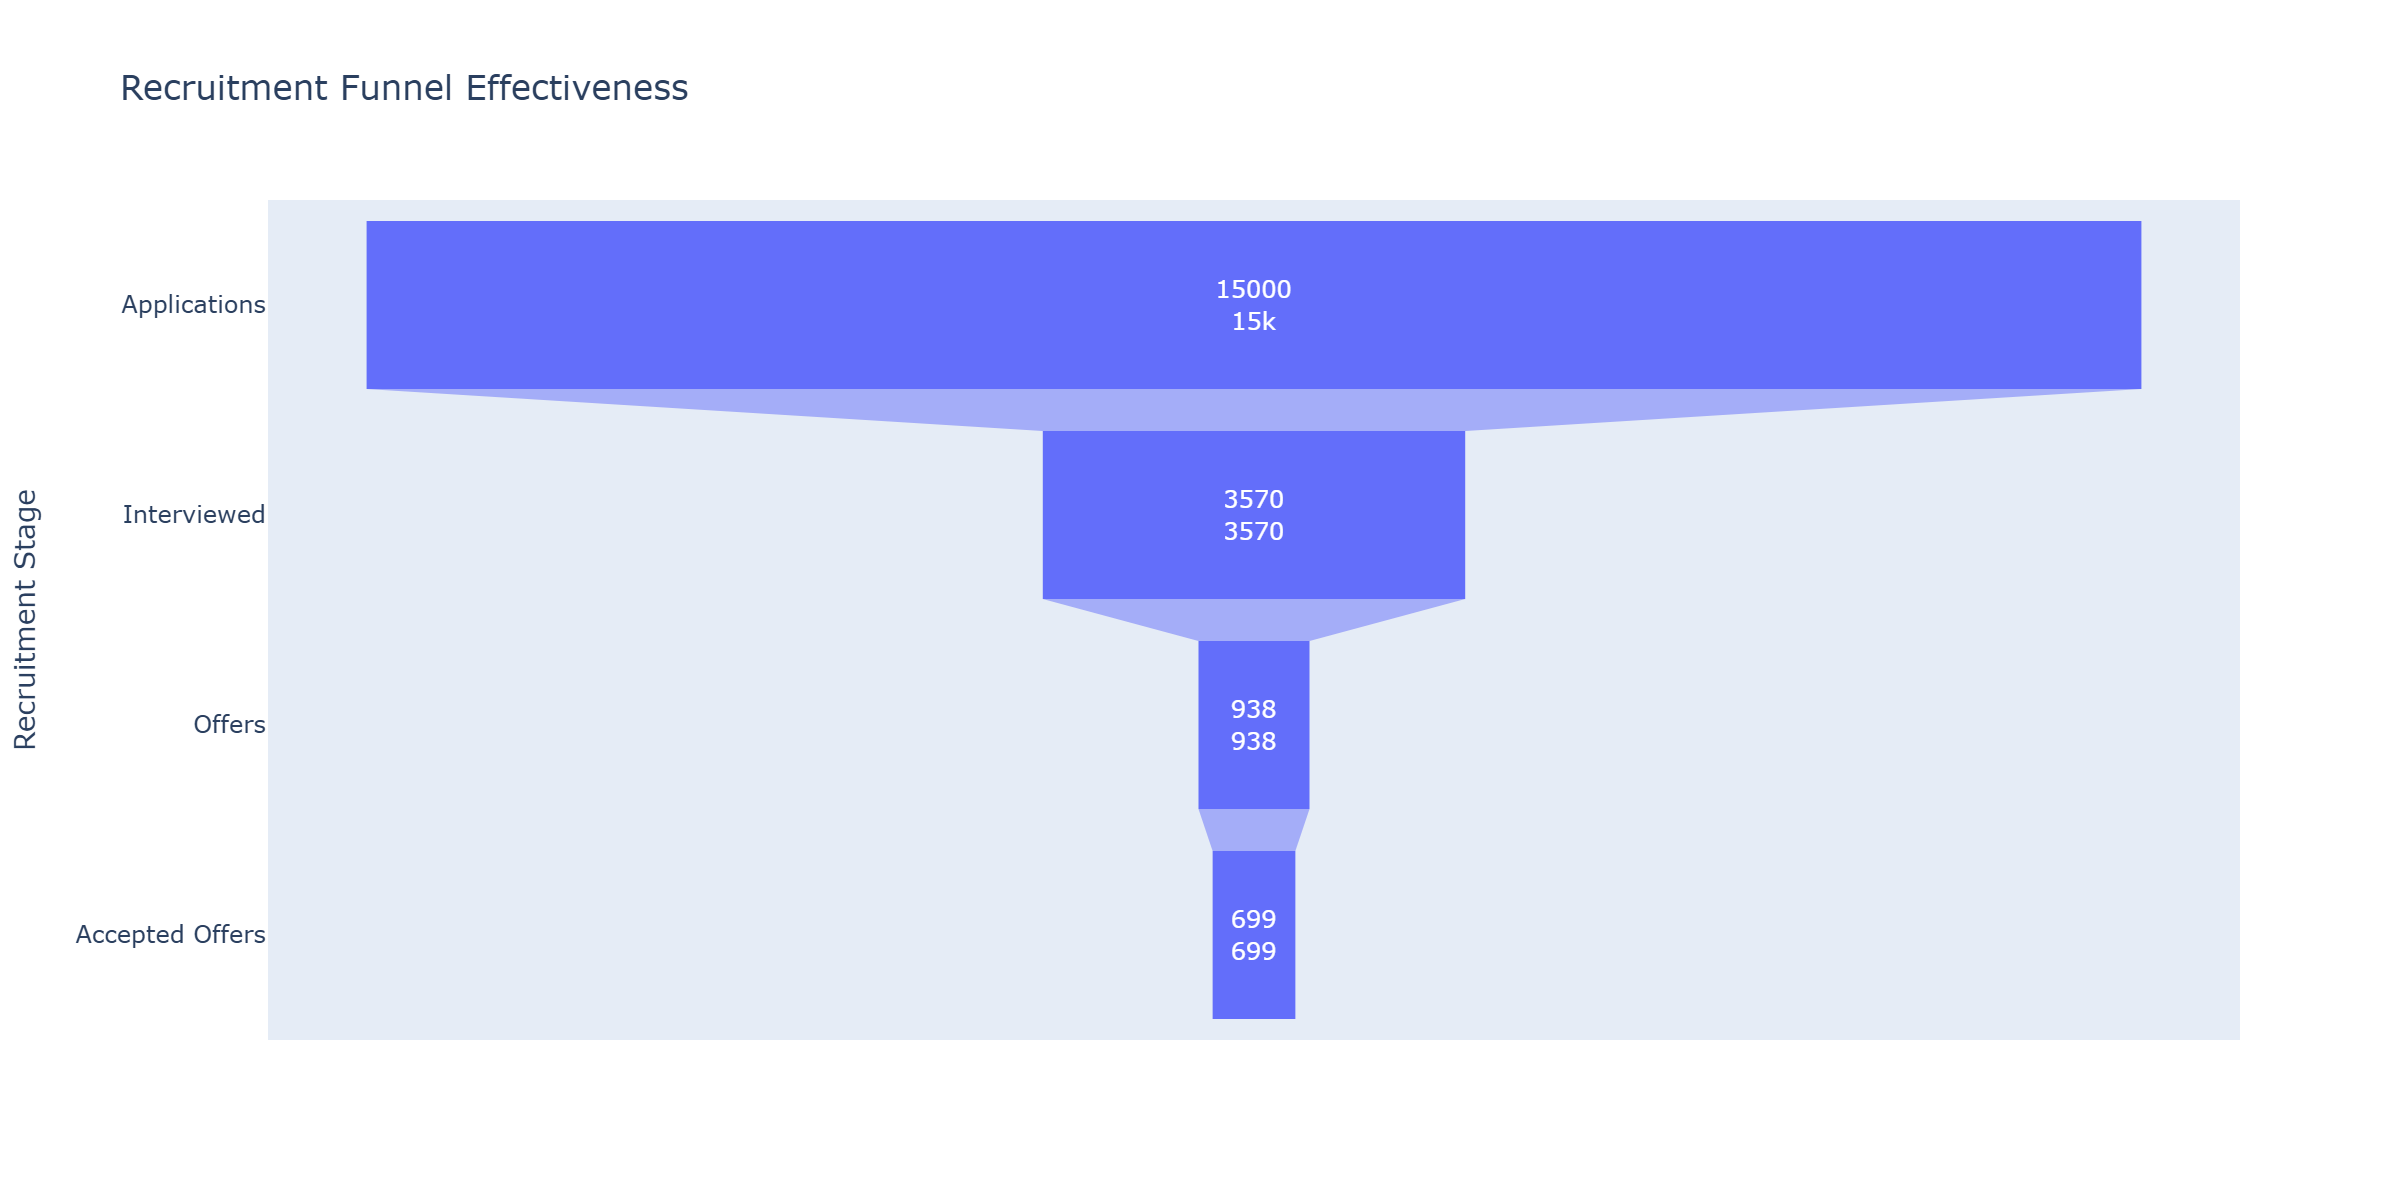

In [92]:
# Create a recruitment funnel chart using Plotly
fig = px.funnel(
    funnel_df,
    x="Count",
    y="Stage",
    title="Recruitment Funnel Effectiveness",
    text="Count"
)

# Update the layout for a cleaner presentation
fig.update_layout(
    yaxis_title="Recruitment Stage",
    xaxis_title="Number of Unique Applications"
)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

In [93]:
# Extract unique application IDs from both tables
offered_ids = set(offers["application_id"])
interviewed_ids = set(interviews["application_id"])

# Identify offers without corresponding interview records
missing_interviews = offered_ids - interviewed_ids

# Select accepted offers
accepted_offers = offers[offers["accepted"] == True]

# Count unique applications with accepted offers
accepted_count = accepted_offers["application_id"].nunique()

# Display validation results
print("Offers without interviews:", len(missing_interviews))
print("Accepted offers:", accepted_count)

Offers without interviews: 0
Accepted offers: 699


### Step 3 — Calculate funnel conversion rates in Python

#### Calculating Funnel Conversion Rates

- **Stage conversion rate:** Current milestone count divided by the previous milestone count × 100.
- **Overall conversion rate:** Current milestone count divided by all 15,000 applications × 100.

Each milestone counts **distinct applications**. A recorded application stage is not the same as a historical funnel milestone.

**Formula examples:**

- Application → first interview: `3,570 / 15,000 × 100 = 23.80%`
- Interview → offer: `938 / 3,570 × 100 = 26.27%`
- Offer → acceptance: `699 / 938 × 100 = 74.52%`

*These are milestone conversion rates, not rejection rates or a time-based cohort analysis.*

In [94]:
# Calculate conversion rates relative to the previous stage
funnel_df["Conversion_Rate"] = (
    funnel_df["Count"] / funnel_df["Count"].shift(1) * 100
)

# Set the first stage conversion to 100%, our starting population
funnel_df.loc[0, "Conversion_Rate"] = 100

# Calculate percentage of original applications reaching each stage
funnel_df["Overall_Rate"] = (
    funnel_df["Count"] / total_applications * 100
)

# Display the updated recruitment funnel
display(funnel_df.round(2))

,Stage,Count,Conversion_Rate,Overall_Rate
0,Applications,15000,100.00,100.00
1,Interviewed,3570,23.80,23.80
2,Offers,938,26.27,6.25
3,Accepted Offers,699,74.52,4.66


### Step 4 — Explore recruitment application stages

In [95]:
# Count applications by their recorded recruitment stage
stage_counts = applications["stage"].value_counts()

# Display the stage distribution
display(stage_counts)

stage
applied      8638
screened     2792
interview    2632
offer         938
Name: count, dtype: int64

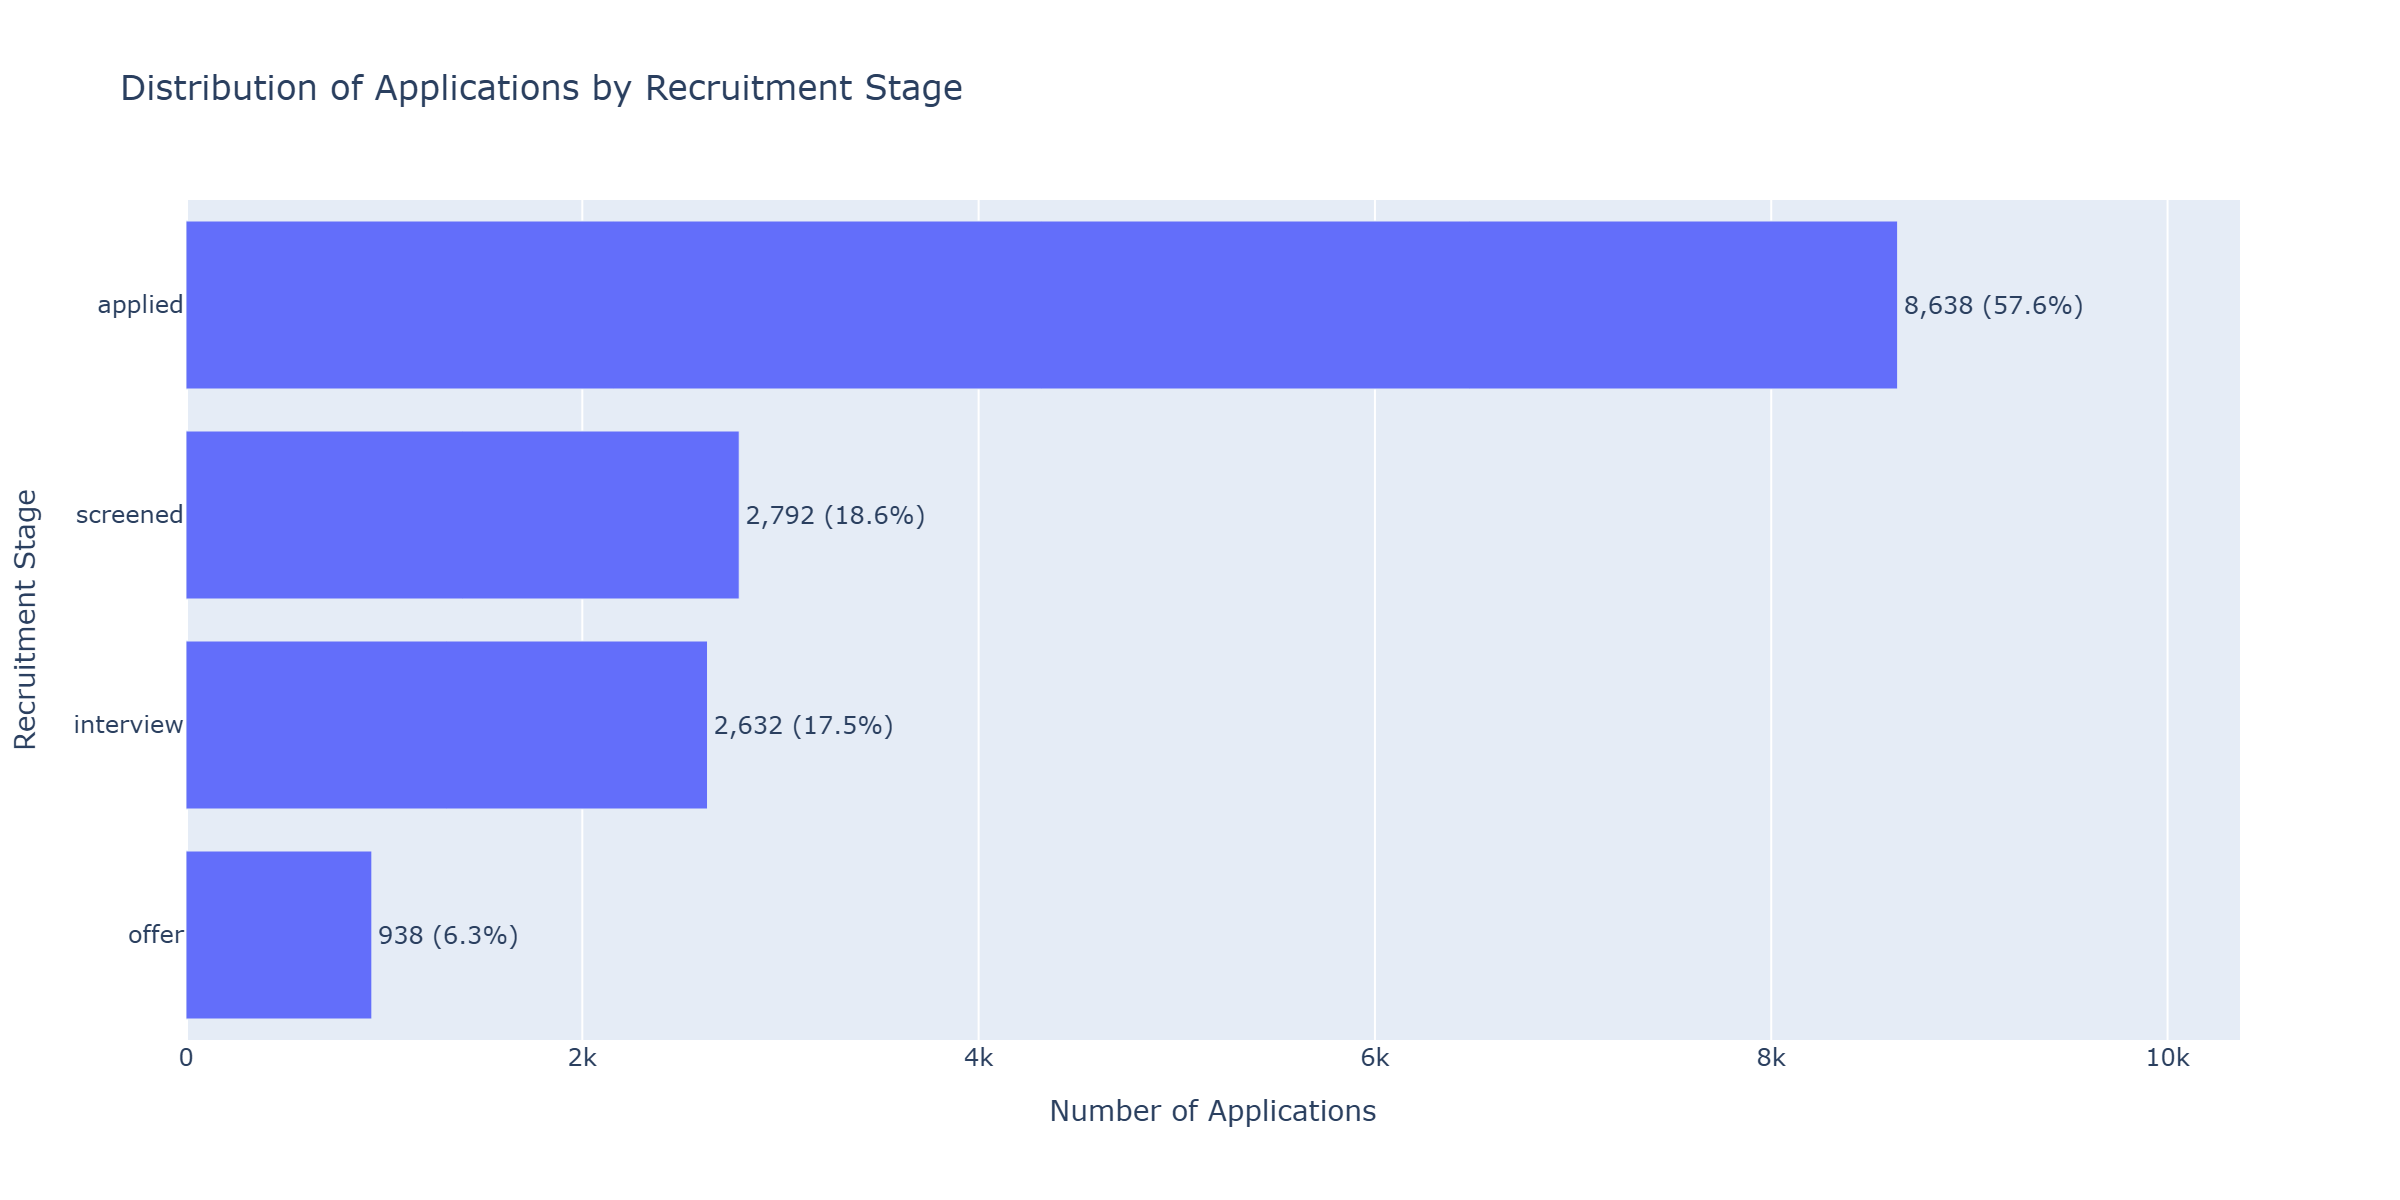

In [96]:
# Create a DataFrame from the application stage counts
stage_df = applications["stage"].value_counts().reset_index()

# Rename the columns for readability
stage_df.columns = ["Stage", "Count"]

# Calculate the percentage of total applications in each stage
stage_df["Percentage"] = stage_df["Count"] / len(applications) * 100

# Create labels showing the count and percentage
stage_df["Label"] = (
    stage_df["Count"].map("{:,}".format) +
    " (" + stage_df["Percentage"].map("{:.1f}%".format) + ")"
)

# Create a horizontal bar chart
fig = px.bar(
    stage_df,
    x="Count",
    y="Stage",
    orientation="h",
    text="Label",
    title="Distribution of Applications by Recruitment Stage"
)

# Place the largest category at the top
fig.update_yaxes(categoryorder="total ascending")

# Position the labels outside the bars
fig.update_traces(textposition="outside")

# Add descriptive axis titles and space for labels
fig.update_layout(
    xaxis_title="Number of Applications",
    yaxis_title="Recruitment Stage",
    xaxis_range=[0, stage_df["Count"].max() * 1.2],
    showlegend=False
)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

Recruitment Stage Distribution: Of the 15,000 applications, 57.6% are recorded at the applied stage, followed by 18.6% at screening, 17.5% at interview, and 6.3% at offer. This distribution indicates that most applications remain classified in the earlier stages of recruitment.

These figures represent recorded application stages, not historical stage-to-stage conversion rates. They should therefore be interpreted separately from the recruitment funnel analysis.

### Step 5 — Validate the stage classification

In [97]:
# Select applications classified at the offer stage
offer_stage = applications[applications["stage"] == "offer"]

# Extract the application IDs and convert them to sets
offer_stage_ids = set(offer_stage["application_id"])
actual_offer_ids = set(offers["application_id"])

# Identify IDs that do not match between the two tables
missing_offers = offer_stage_ids - actual_offer_ids
wrong_stage = actual_offer_ids - offer_stage_ids

# Display the validation results
print("Offer-stage applications:", len(offer_stage_ids))
print("Offer stage without offer record:", len(missing_offers))
print("Offer records with another stage:", len(wrong_stage))

Offer-stage applications: 938
Offer stage without offer record: 0
Offer records with another stage: 0


### Step 6 — Confirm the interview-stage relationship

In [98]:
# Select applications classified at the interview stage
interview_stage = applications[applications["stage"] == "interview"]

# Extract unique application IDs from both tables
interview_stage_ids = set(interview_stage["application_id"])
interviewed_ids = set(interviews["application_id"])

# Identify IDs that do not match between the two tables
missing_interviews = interview_stage_ids - interviewed_ids
other_stages = interviewed_ids - interview_stage_ids

# Display the validation results
print("Interview stage without interview records:", len(missing_interviews))
print("Other stages with interview records:", len(other_stages))

Interview stage without interview records: 0
Other stages with interview records: 938


### Q1 — Findings and Business Implications

#### Key Findings

- **15,000 applications**, **3,570 applications with interviews**, **938 with offers**, and **699 with accepted offers**.
- **23.80%** of all applications had an interview; **26.27%** of interviewed applications received an offer.
- **74.52%** of offers were accepted; overall application-to-accepted-offer conversion was **4.66%**.
- The largest count reduction was between application and first interview (**76.20%** without an interview record).
- Recorded offer-stage and interview-stage classifications were checked against their corresponding records.

#### Business Insights & Recommendations

- Investigate sourcing and early-stage screening to understand why comparatively few applications have interview records.
- Examine offer acceptance and recruitment-source outcomes to identify useful areas for process review.
- Maintain separate definitions for *current application stage* and *historical recruitment milestone*.

#### Analytical Limitations

- Applications without an interview or offer record should **not** automatically be classified as rejected; some may still be in progress.
- Counts are cross-sectional rather than a time-based application cohort.
- An accepted offer is **not** necessarily a confirmed hire.
- This is a synthetic dataset and does not measure actual employer outcomes.

# Q2 — Recruitment Source Effectiveness

**Business question:** Which sources generate higher offer and acceptance rates?

#### Metrics to Evaluate

| Metric | Business Purpose |
|---|---|
| Application volume | Which sources attract the most applications? |
| Offer conversion rate | Which sources generate the highest proportion of offers per application? |
| Offer acceptance rate | Which sources have the highest proportion of accepted offers per offer made? |

*These denominators differ: offer conversion uses applications, while acceptance uses offers.*

### Step 1 — Examine our recruitment sources

In [99]:
# Count applications from each recruitment Source_Label
source_counts = applications["Source_Label"].value_counts()

# Calculate each Source_Label's percentage of total applications
source_percentage = applications["Source_Label"].value_counts(normalize=True) * 100

# Combine the results into a DataFrame
source_df = pd.DataFrame({
    "Applications": source_counts,
    "Percentage": source_percentage
})

# Display the recruitment Source_Label summary
display(source_df.round(2))

,Applications,Percentage
Source_Label,,
Job Board,7094,47.29
Referral,2694,17.96
LinkedIn,2648,17.65
Outbound / Proactive Sourcing,1333,8.89
Recruiter-Sourced (Unspecified),1231,8.21


### Step 2 — Visualize recruitment source volume

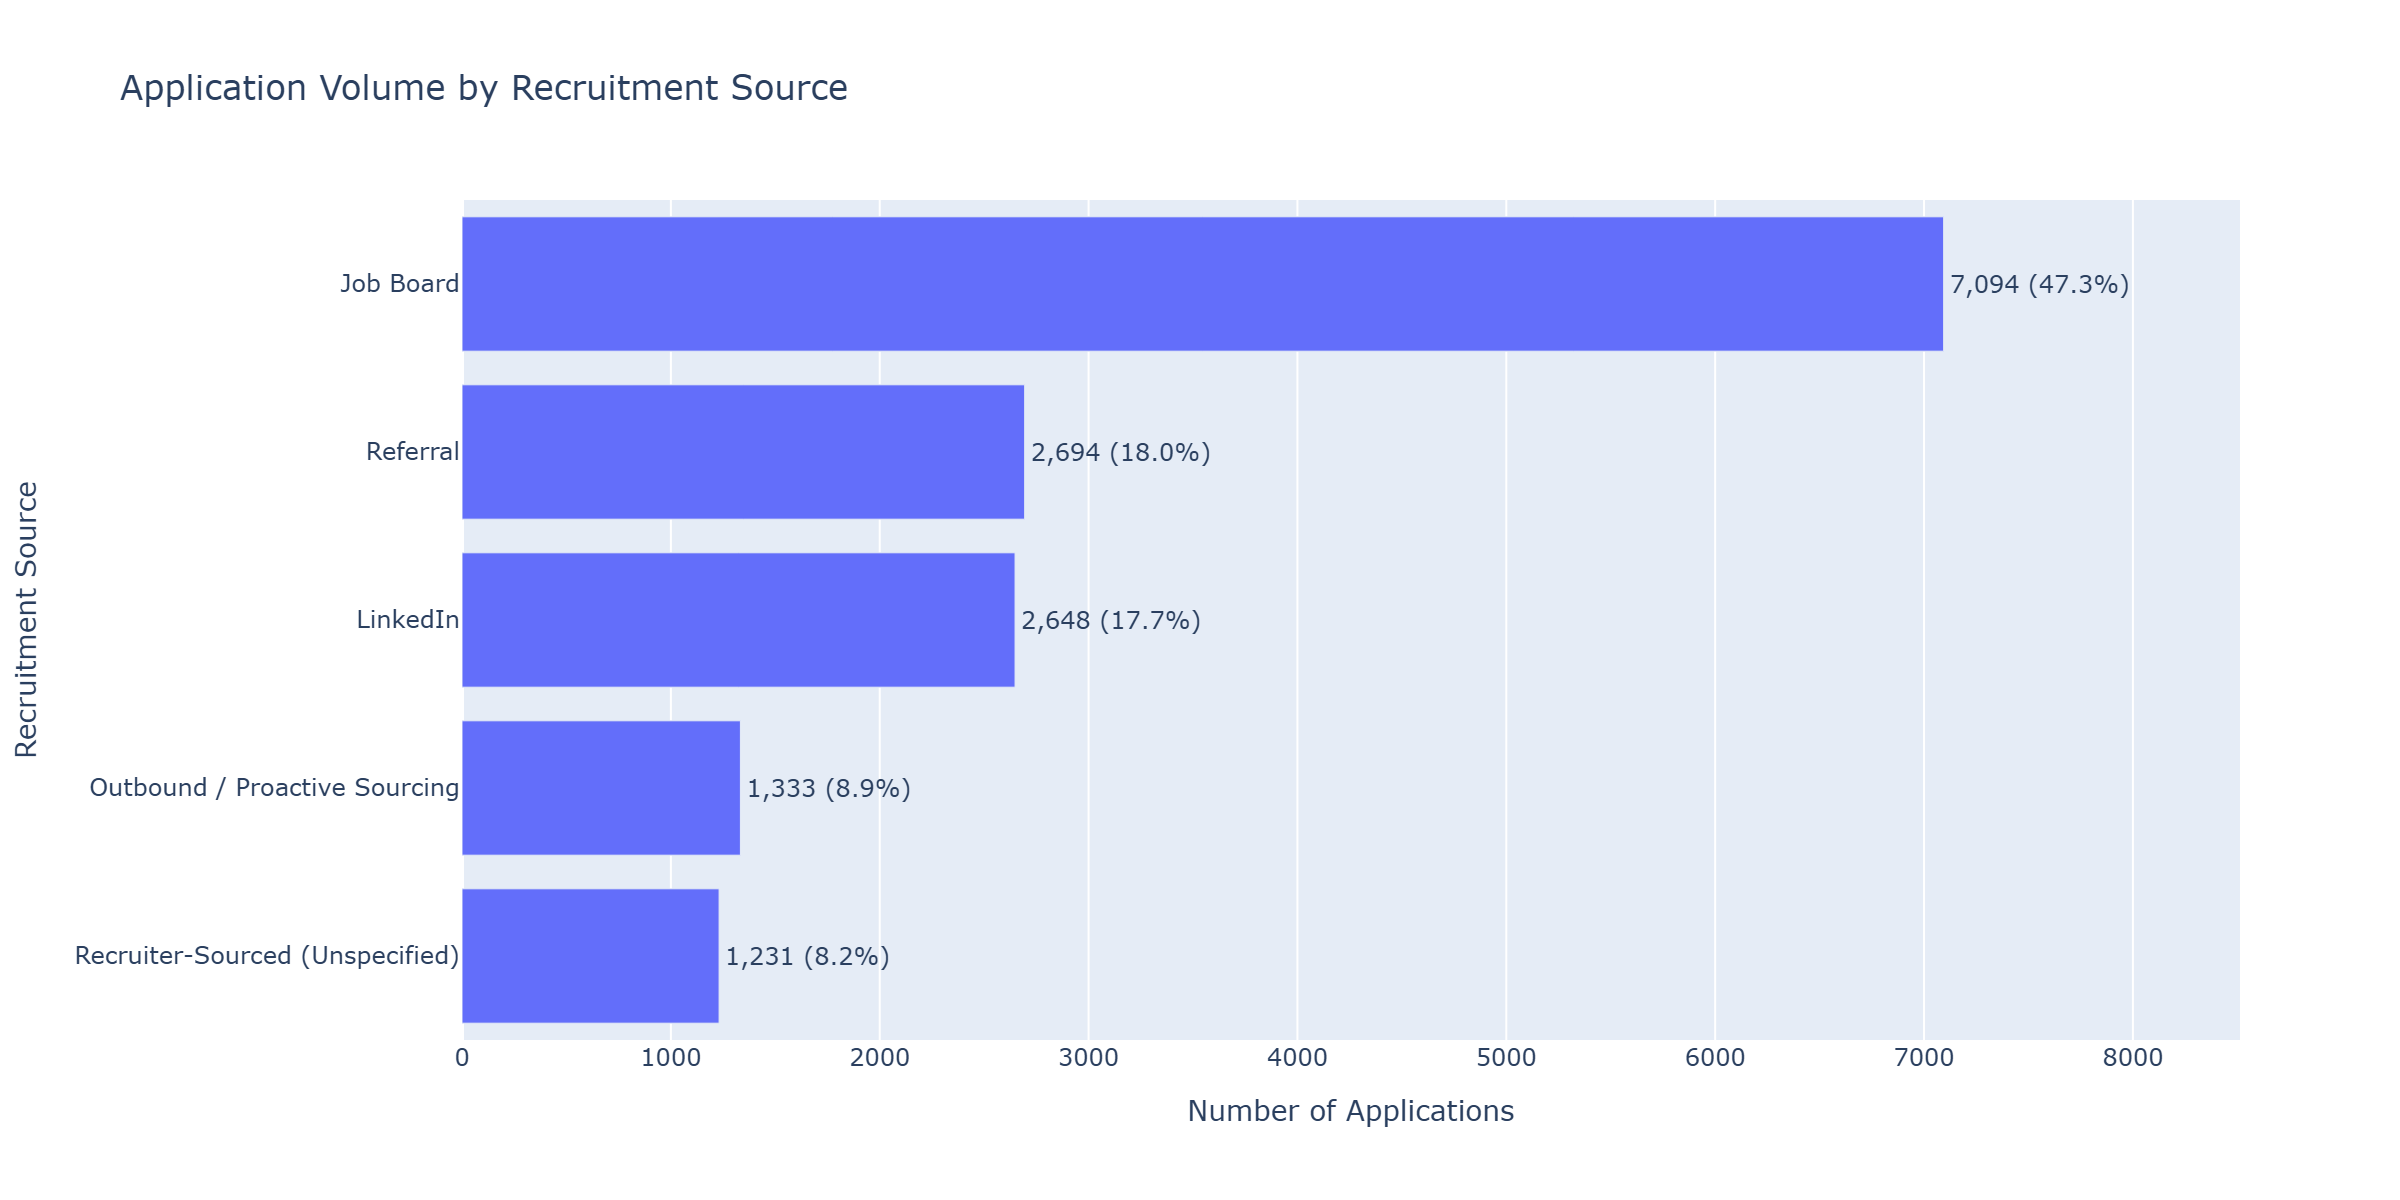

In [100]:
# Reset the index to turn recruitment sources into a column
source_chart = source_df.reset_index()

# Create labels showing application counts and percentages
source_chart["Label"] = (
    source_chart["Applications"].map("{:,}".format)
    + " (" + source_chart["Percentage"].map("{:.1f}%".format) + ")"
)

# Create a horizontal bar chart
fig = px.bar(
    source_chart,
    x="Applications",
    y="Source_Label",
    orientation="h",
    text="Label",
    title="Application Volume by Recruitment Source"
)

# Sort sources from highest to lowest application volume
fig.update_yaxes(categoryorder="total ascending")

# Display labels outside the bars
fig.update_traces(textposition="outside")

# Improve chart layout
fig.update_layout(
    xaxis_title="Number of Applications",
    yaxis_title="Recruitment Source",
    xaxis_range=[0, source_chart["Applications"].max() * 1.2],
    showlegend=False
)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

#### Recruitment Source — Business Observation

- Company career portals and employee referral programmes can be valuable recruitment channels.
- Referral incentives may encourage employees to recommend qualified candidates.
- This dataset does not identify company career portals separately from external job boards or provide referral costs.
- The `outbound` and `recruiter` classifications mix potentially different sourcing concepts; their operational definitions are unverified.
- **Recommendation:** Distinguish original sourcing channels, outreach methods and recruiter involvement in the ATS.

The following comparisons describe the source labels supplied by this synthetic dataset; they do not establish causal effectiveness.

### Step 3 — Calculate offers and acceptances by source

In [101]:
# Merge applications with offers, keeping all applications
source_analysis = applications.merge(
    offers[["application_id", "accepted"]],
    on="application_id",
    how="left"
)

# Create a column identifying applications that received offers
source_analysis["Received_Offer"] = source_analysis["accepted"].notna() # .notna() checks whether a value is not missing.

# Count applications, offers and accepted offers by source: to summarize outcomes of each sourse
source_summary = source_analysis.groupby("Source_Label").agg(
    Applications=("application_id", "count"),
    Offers=("Received_Offer", "sum"),
    Accepted_Offers=("accepted", "sum")
).reset_index()

# Display the recruitment source summary
display(source_summary)

,Source_Label,Applications,Offers,Accepted_Offers
0,Job Board,7094,459,345
1,LinkedIn,2648,159,108
2,Outbound / Proactive Sourcing,1333,84,59
3,Recruiter-Sourced (Unspecified),1231,84,69
4,Referral,2694,152,118


### Step 4 — Calculate recruitment source conversion rates

**Recruitment source KPIs**

- `Offer_Rate = Offers / Applications × 100`
- `Acceptance_Rate = Accepted_Offers / Offers × 100`

Use the second denominator only for offers actually made; do not confuse offer acceptance with application-to-hire conversion.

In [102]:
# Calculate the percentage of applications receiving offers
source_summary["Offer_Rate"] = (
    source_summary["Offers"] / source_summary["Applications"] * 100
)

# Calculate the percentage of offers that were accepted
source_summary["Acceptance_Rate"] = (
    source_summary["Accepted_Offers"] / source_summary["Offers"] * 100
)

# Display the results, sorted by offer rate
source_summary = source_summary.sort_values("Offer_Rate", ascending=False)

# Display the summary rounded to two decimal places
display(source_summary.round(2))

,Source_Label,Applications,Offers,Accepted_Offers,Offer_Rate,Acceptance_Rate
3,Recruiter-Sourced (Unspecified),1231,84,69,6.82,82.14
0,Job Board,7094,459,345,6.47,75.16
2,Outbound / Proactive Sourcing,1333,84,59,6.30,70.24
1,LinkedIn,2648,159,108,6.00,67.92
4,Referral,2694,152,118,5.64,77.63


### Step 5 —RTecruitment Source Performance (side by side)

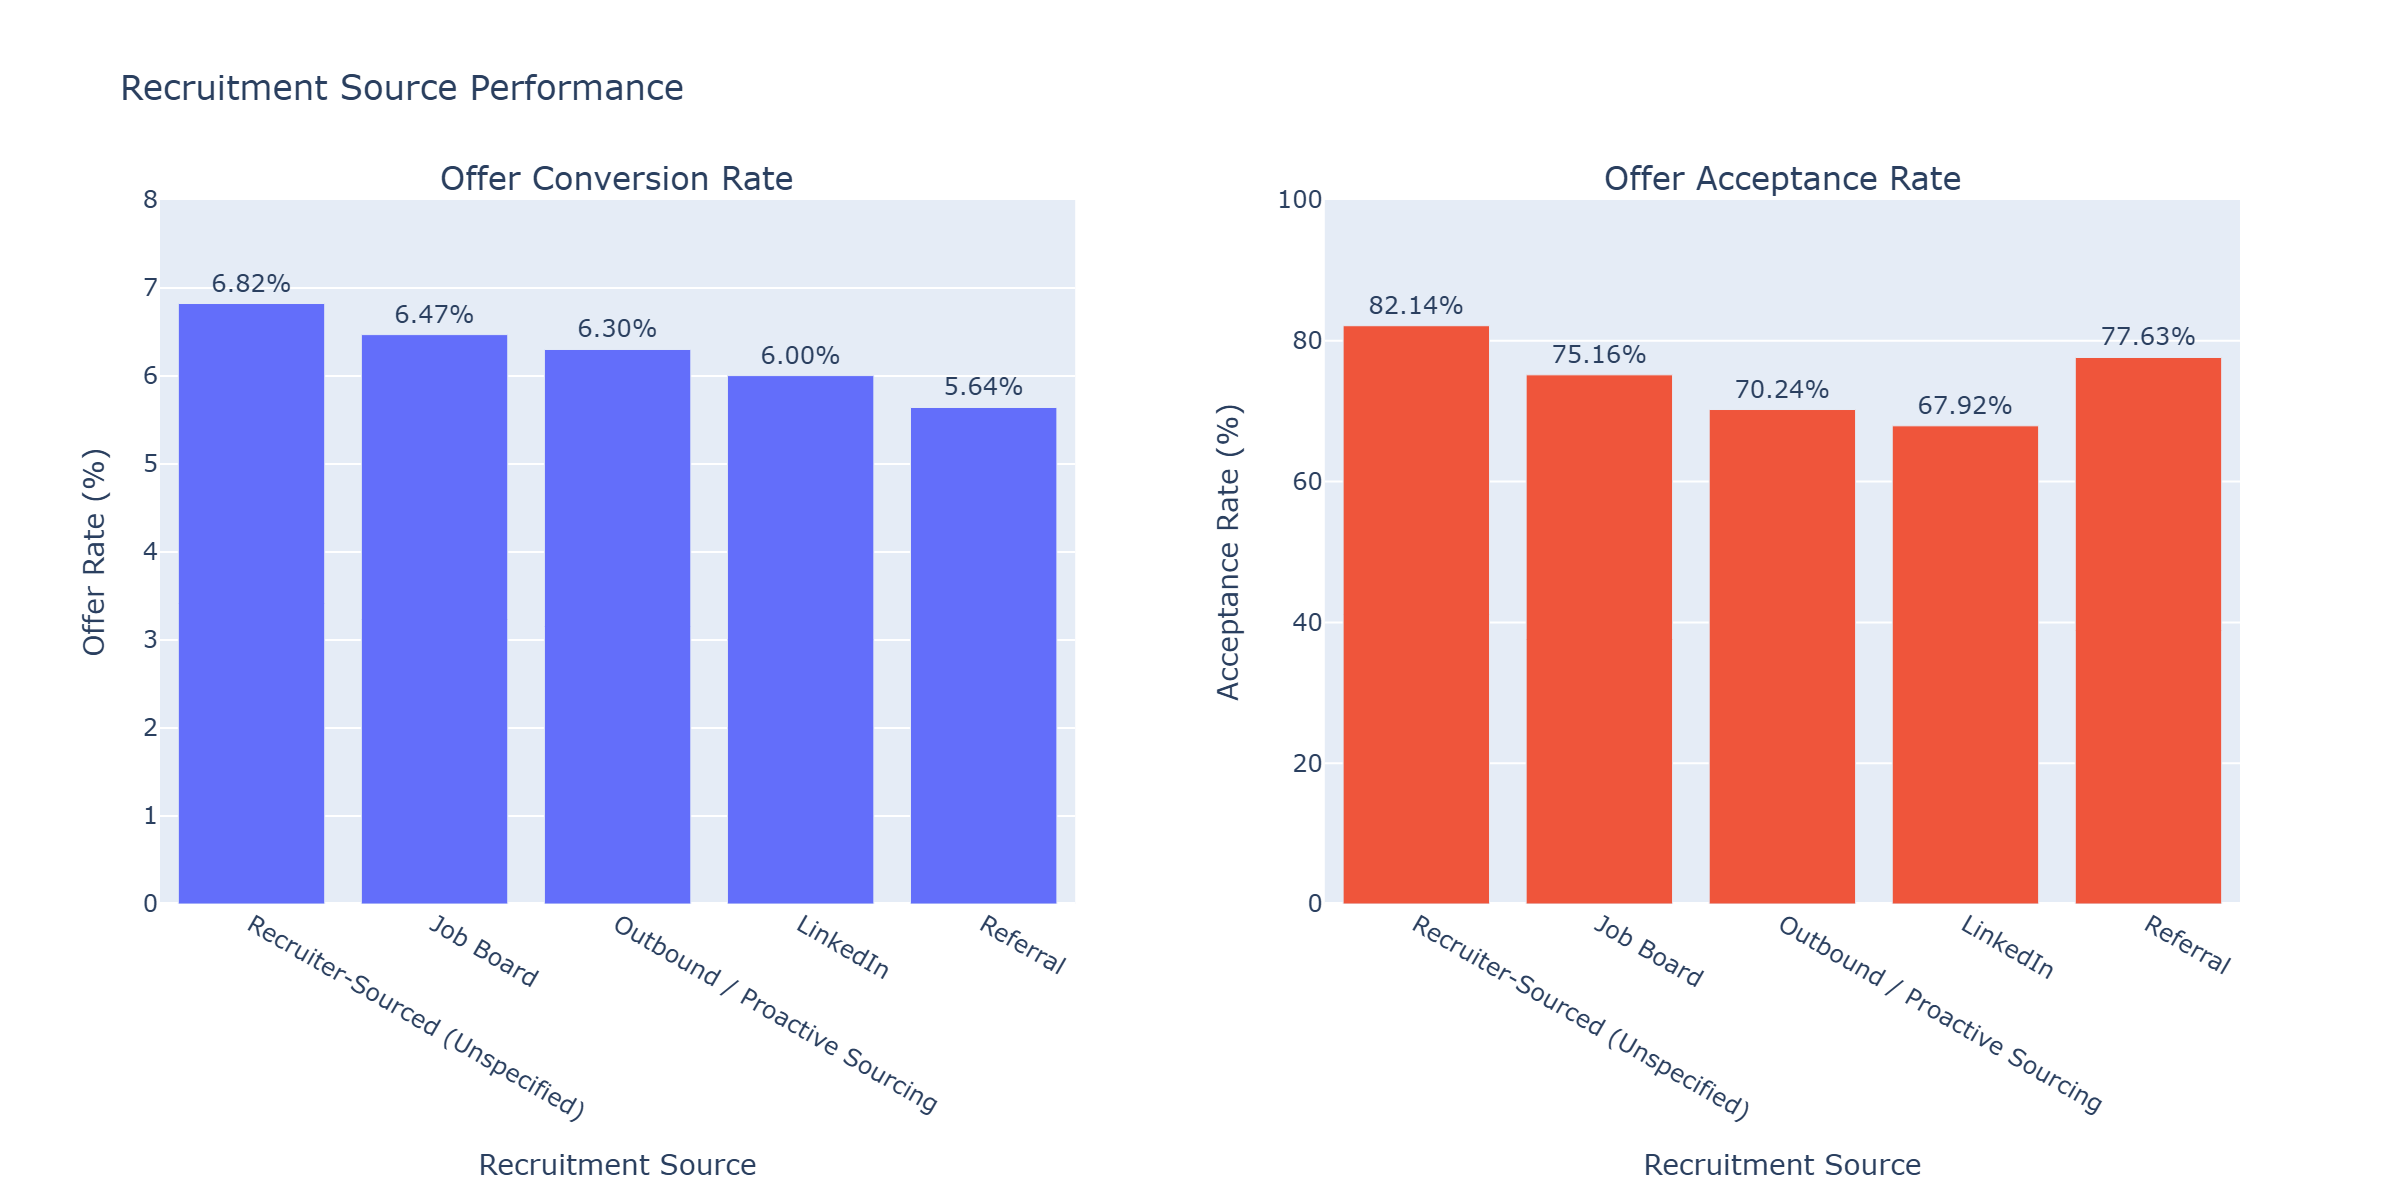

In [103]:
# Create two side-by-side charts with independent y-axes
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Offer Conversion Rate",
        "Offer Acceptance Rate"
    ),
    horizontal_spacing=0.12
)

# Add Offer Conversion Rate to the first chart
fig.add_trace(
    go.Bar(
        x=source_summary["Source_Label"],
        y=source_summary["Offer_Rate"],
        text=source_summary["Offer_Rate"],
        texttemplate="%{text:.2f}%",
        textposition="outside",
        name="Offer Rate"
    ),
    row=1, col=1
)

# Add Offer Acceptance Rate to the second chart
fig.add_trace(
    go.Bar(
        x=source_summary["Source_Label"],
        y=source_summary["Acceptance_Rate"],
        text=source_summary["Acceptance_Rate"],
        texttemplate="%{text:.2f}%",
        textposition="outside",
        name="Acceptance Rate"
    ),
    row=1, col=2
)

# Label the horizontal axes
fig.update_xaxes(title_text="Recruitment Source", row=1, col=1)
fig.update_xaxes(title_text="Recruitment Source", row=1, col=2)

# Set separate vertical scales for each metric
fig.update_yaxes(title_text="Offer Rate (%)", range=[0, 8], row=1, col=1)
fig.update_yaxes(title_text="Acceptance Rate (%)", range=[0, 100], row=1, col=2)

# Improve the overall layout
fig.update_layout(
    title_text="Recruitment Source Performance",
    height=600,
    width=1400,
    showlegend=False
)

# Display the combined chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)


### Business Question #2 — Recruitment Source Effectiveness

#### Key Findings

- **Recruiter-Sourced (Unspecified)** recorded the highest offer conversion rate (6.82%) and offer acceptance rate (82.14%).
- **Job Boards** generated the largest application volume (7,094), resulting in 459 offers and 345 accepted offers.
- **Referrals** recorded the lowest offer conversion rate (5.64%) but the second-highest offer acceptance rate (77.63%).
- **LinkedIn** recorded a 6.00% offer conversion rate and the lowest offer acceptance rate (67.92%).
- **Outbound / Proactive Sourcing** achieved a 6.30% offer conversion rate and a 70.24% acceptance rate.

#### Business Insights & Recommendations

- **Evaluate recruiter-led sourcing:** Investigate whether its relatively strong conversion and acceptance rates can be maintained with greater sourcing volume.
- **Maintain job-board visibility:** Job boards generated the largest number of accepted offers and remain an important recruitment channel.
- **Review LinkedIn sourcing:** Investigate its lower offer acceptance rate before changing recruitment investment.
- **Strengthen referral programmes:** Evaluate whether referral incentives and improved candidate targeting could increase offer conversion.
- **Improve ATS source classifications:** Distinguish sourcing channels from recruitment methods, particularly for `outbound` and `recruiter`.
- **Assess recruitment costs:** Track cost-per-application, cost-per-offer, and cost-per-accepted-offer to better evaluate recruitment efficiency.

#### Analytical Limitations

- Recruitment source definitions are not fully documented in this synthetic dataset.
- The observed differences are descriptive; statistical significance will be investigated separately in `Statistics.ipynb`.
- Recruitment costs and candidate quality measures are unavailable.


# Q3 — Hiring Difficulty by Job Type

**Business question:** Which role families or seniority levels show lower offer conversion?

### Step 1 — Examine our job categories

In [104]:
# Count jobs by role family
role_counts = jobs["role_family"].value_counts()

# Display role family distribution
display(role_counts)

# Count jobs by seniority level
level_counts = jobs["level"].value_counts()

# Display seniority level distribution
display(level_counts)

role_family
operations          991
engineering         425
data                302
product             128
customer_success     77
sales                77
Name: count, dtype: int64

level
senior    748
mid       739
lead      260
junior    253
Name: count, dtype: int64

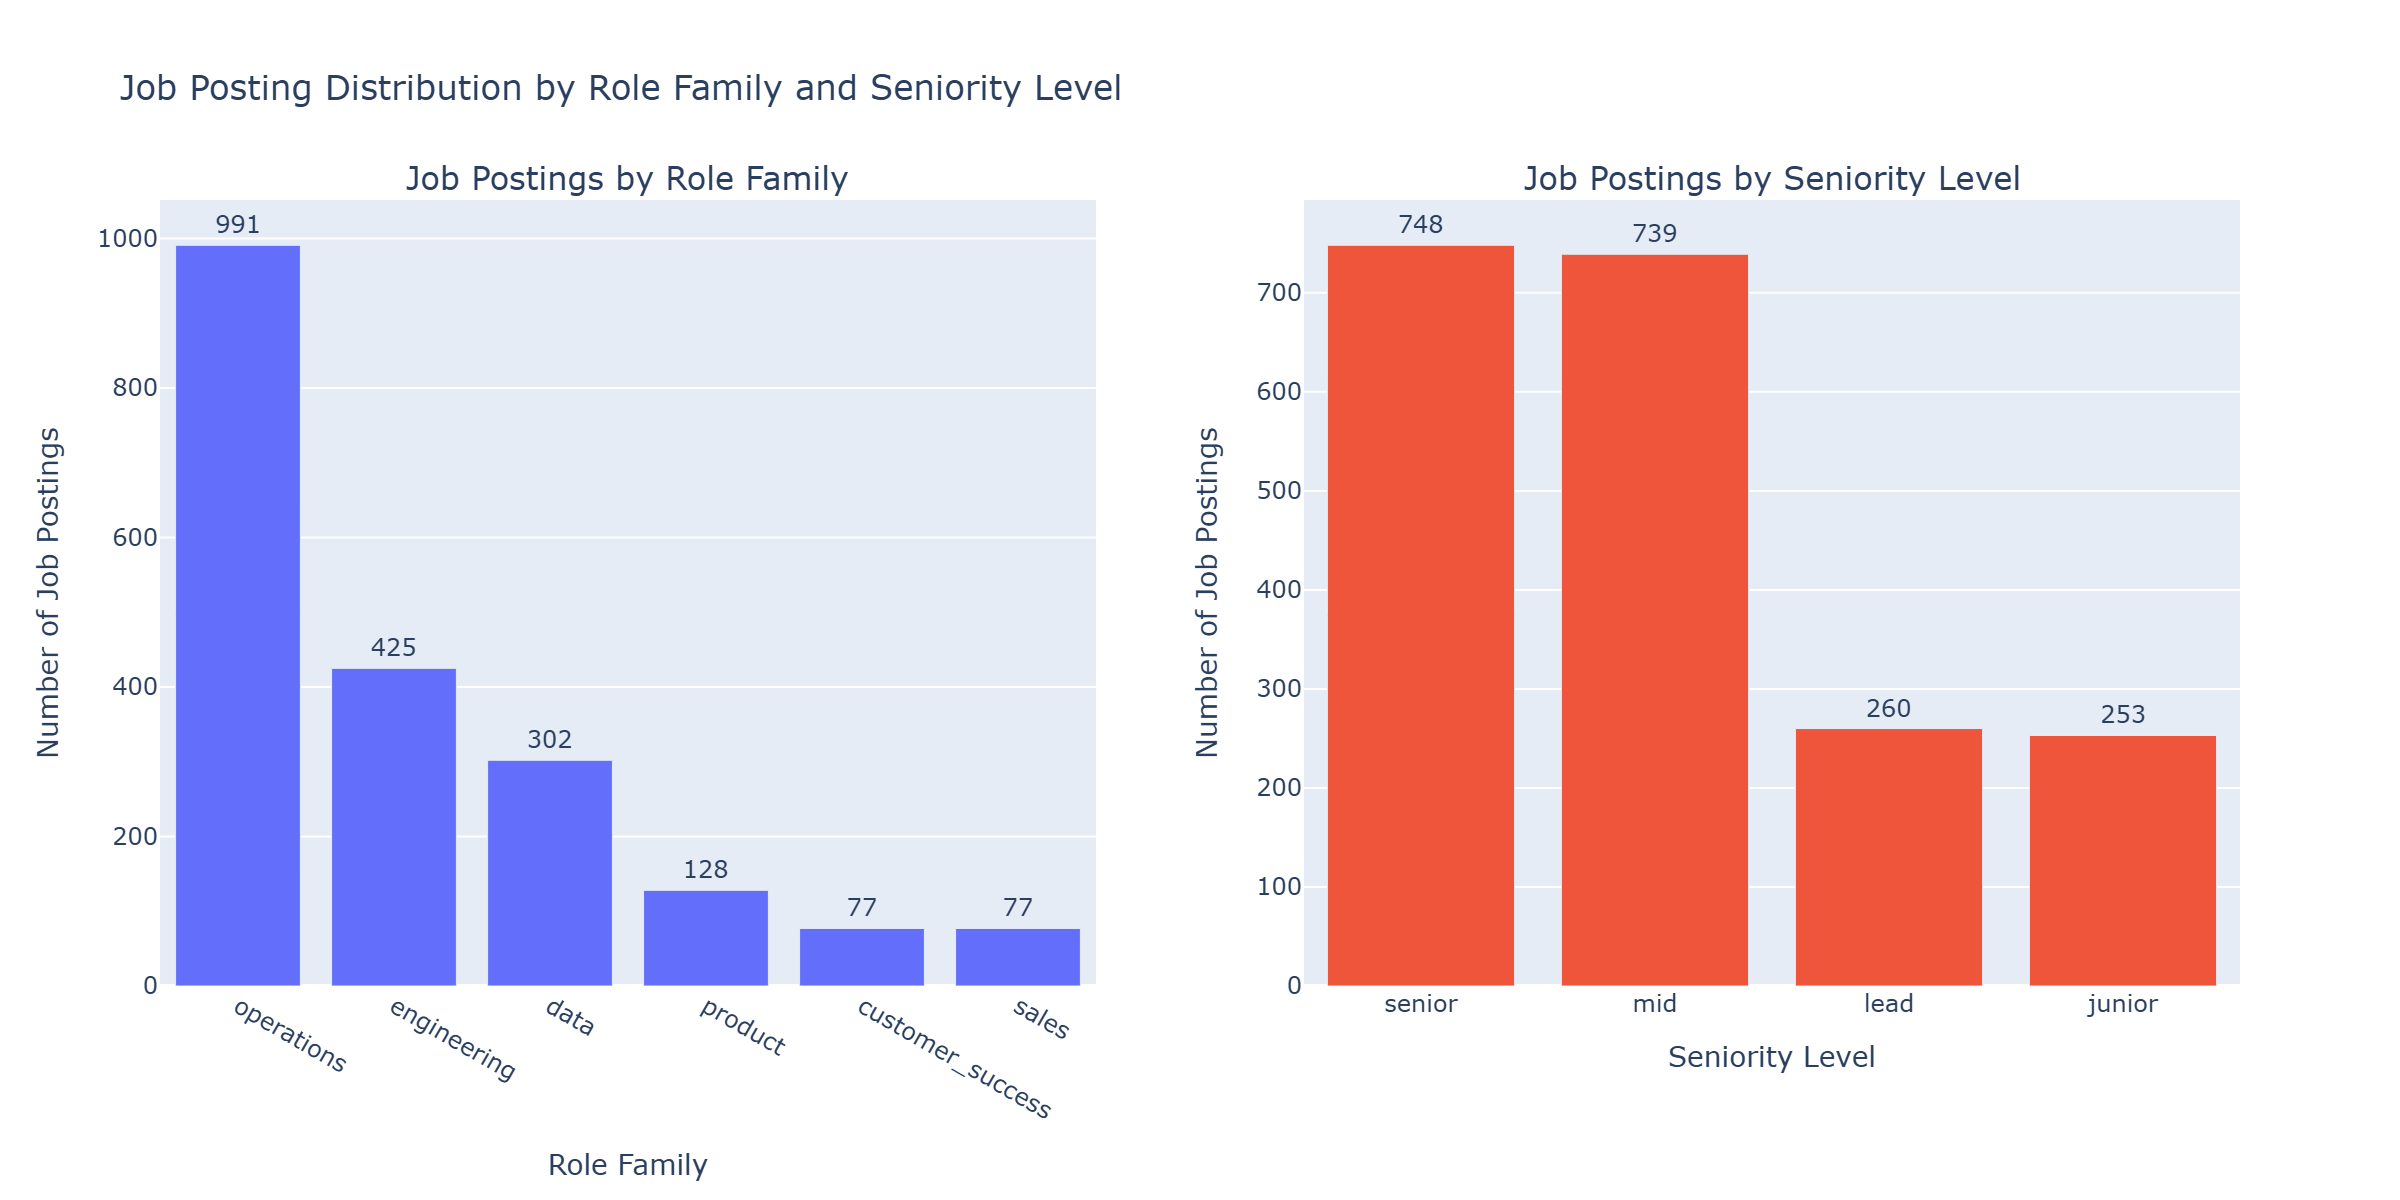

In [105]:
# Reset the indexes to convert categories into columns
role_chart = role_counts.reset_index()
level_chart = level_counts.reset_index()

# Create two charts side by side
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Job Postings by Role Family", "Job Postings by Seniority Level")
)

# Add the Role Family bar chart
fig.add_trace(
    go.Bar(
        x=role_chart["role_family"],
        y=role_chart["count"],
        text=role_chart["count"],
        textposition="outside",
        name="Role Family"
    ),
    row=1, col=1
)

# Add the Seniority Level bar chart
fig.add_trace(
    go.Bar(
        x=level_chart["level"],
        y=level_chart["count"],
        text=level_chart["count"],
        textposition="outside",
        name="Seniority Level"
    ),
    row=1, col=2
)

# Update chart titles and layout
fig.update_layout(
    title_text="Job Posting Distribution by Role Family and Seniority Level",
    height=550,
    showlegend=False
)

# Label the axes
fig.update_xaxes(title_text="Role Family", row=1, col=1)
fig.update_xaxes(title_text="Seniority Level", row=1, col=2)
fig.update_yaxes(title_text="Number of Job Postings", row=1, col=1)
fig.update_yaxes(title_text="Number of Job Postings", row=1, col=2)

# Display the charts
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

### Step 2 — Connect Job Postings to Applications

In [106]:
# Select the relevant job information
job_details = jobs[["job_id", "role_family", "level"]]

# Merge applications with job details using job_id
hiring_analysis = applications.merge(
    job_details,
    on="job_id",
    how="left"
)

# Verify that all applications have a role family and seniority level
print("Total applications:", len(hiring_analysis))
print("Missing role families:", hiring_analysis["role_family"].isna().sum())
print("Missing seniority levels:", hiring_analysis["level"].isna().sum())

# Preview the relevant columns
display(hiring_analysis[["application_id", "role_family", "level"]].head())

Total applications: 15000
Missing role families: 0
Missing seniority levels: 0


,application_id,role_family,level
0,1,customer_success,mid
1,2,operations,mid
2,3,operations,lead
3,4,engineering,junior
4,5,engineering,lead


### Step 3 — Identify Applications That Received Offers

In [107]:
# Select the application IDs that received offers
offer_ids = offers[["application_id"]]

# Merge the offer records into our hiring analysis
hiring_analysis = hiring_analysis.merge(
    offer_ids,
    on="application_id",
    how="left",
    indicator=True
)

# Identify applications that received offers
hiring_analysis["Received_Offer"] = (
    hiring_analysis["_merge"] == "both"
)

# Remove the temporary merge indicator
hiring_analysis = hiring_analysis.drop(columns="_merge")

# Verify the results
print("Total applications:", len(hiring_analysis))
print("Applications with offers:", hiring_analysis["Received_Offer"].sum())
print("Applications without offers:", (~hiring_analysis["Received_Offer"]).sum())

Total applications: 15000
Applications with offers: 938
Applications without offers: 14062


### Step 4 — Offer Conversion Rate by Role Family

**Offer conversion rate by job category:** `Offers / Applications × 100`.

This measures the proportion of applications receiving offers, **not** the percentage of vacancies filled or time-to-fill. Lower conversion alone does not establish that a role is difficult to fill.

In [108]:
# Count applications and offers by role family
role_summary = hiring_analysis.groupby("role_family").agg(
    Applications=("application_id", "count"),
    Offers=("Received_Offer", "sum")
).reset_index()

# Calculate offer conversion rate for each role family
role_summary["Offer_Rate"] = (
    role_summary["Offers"] / role_summary["Applications"] * 100
)

# Sort role families from highest to lowest offer conversion rate
role_summary = role_summary.sort_values("Offer_Rate", ascending=False)

# Display the results
display(role_summary.round(2))

,role_family,Applications,Offers,Offer_Rate
3,operations,7443,487,6.54
2,engineering,3142,202,6.43
5,sales,561,34,6.06
4,product,1000,57,5.70
1,data,2291,129,5.63
0,customer_success,563,29,5.15


### Step 5 — Visualize Offer Conversion by Role Family

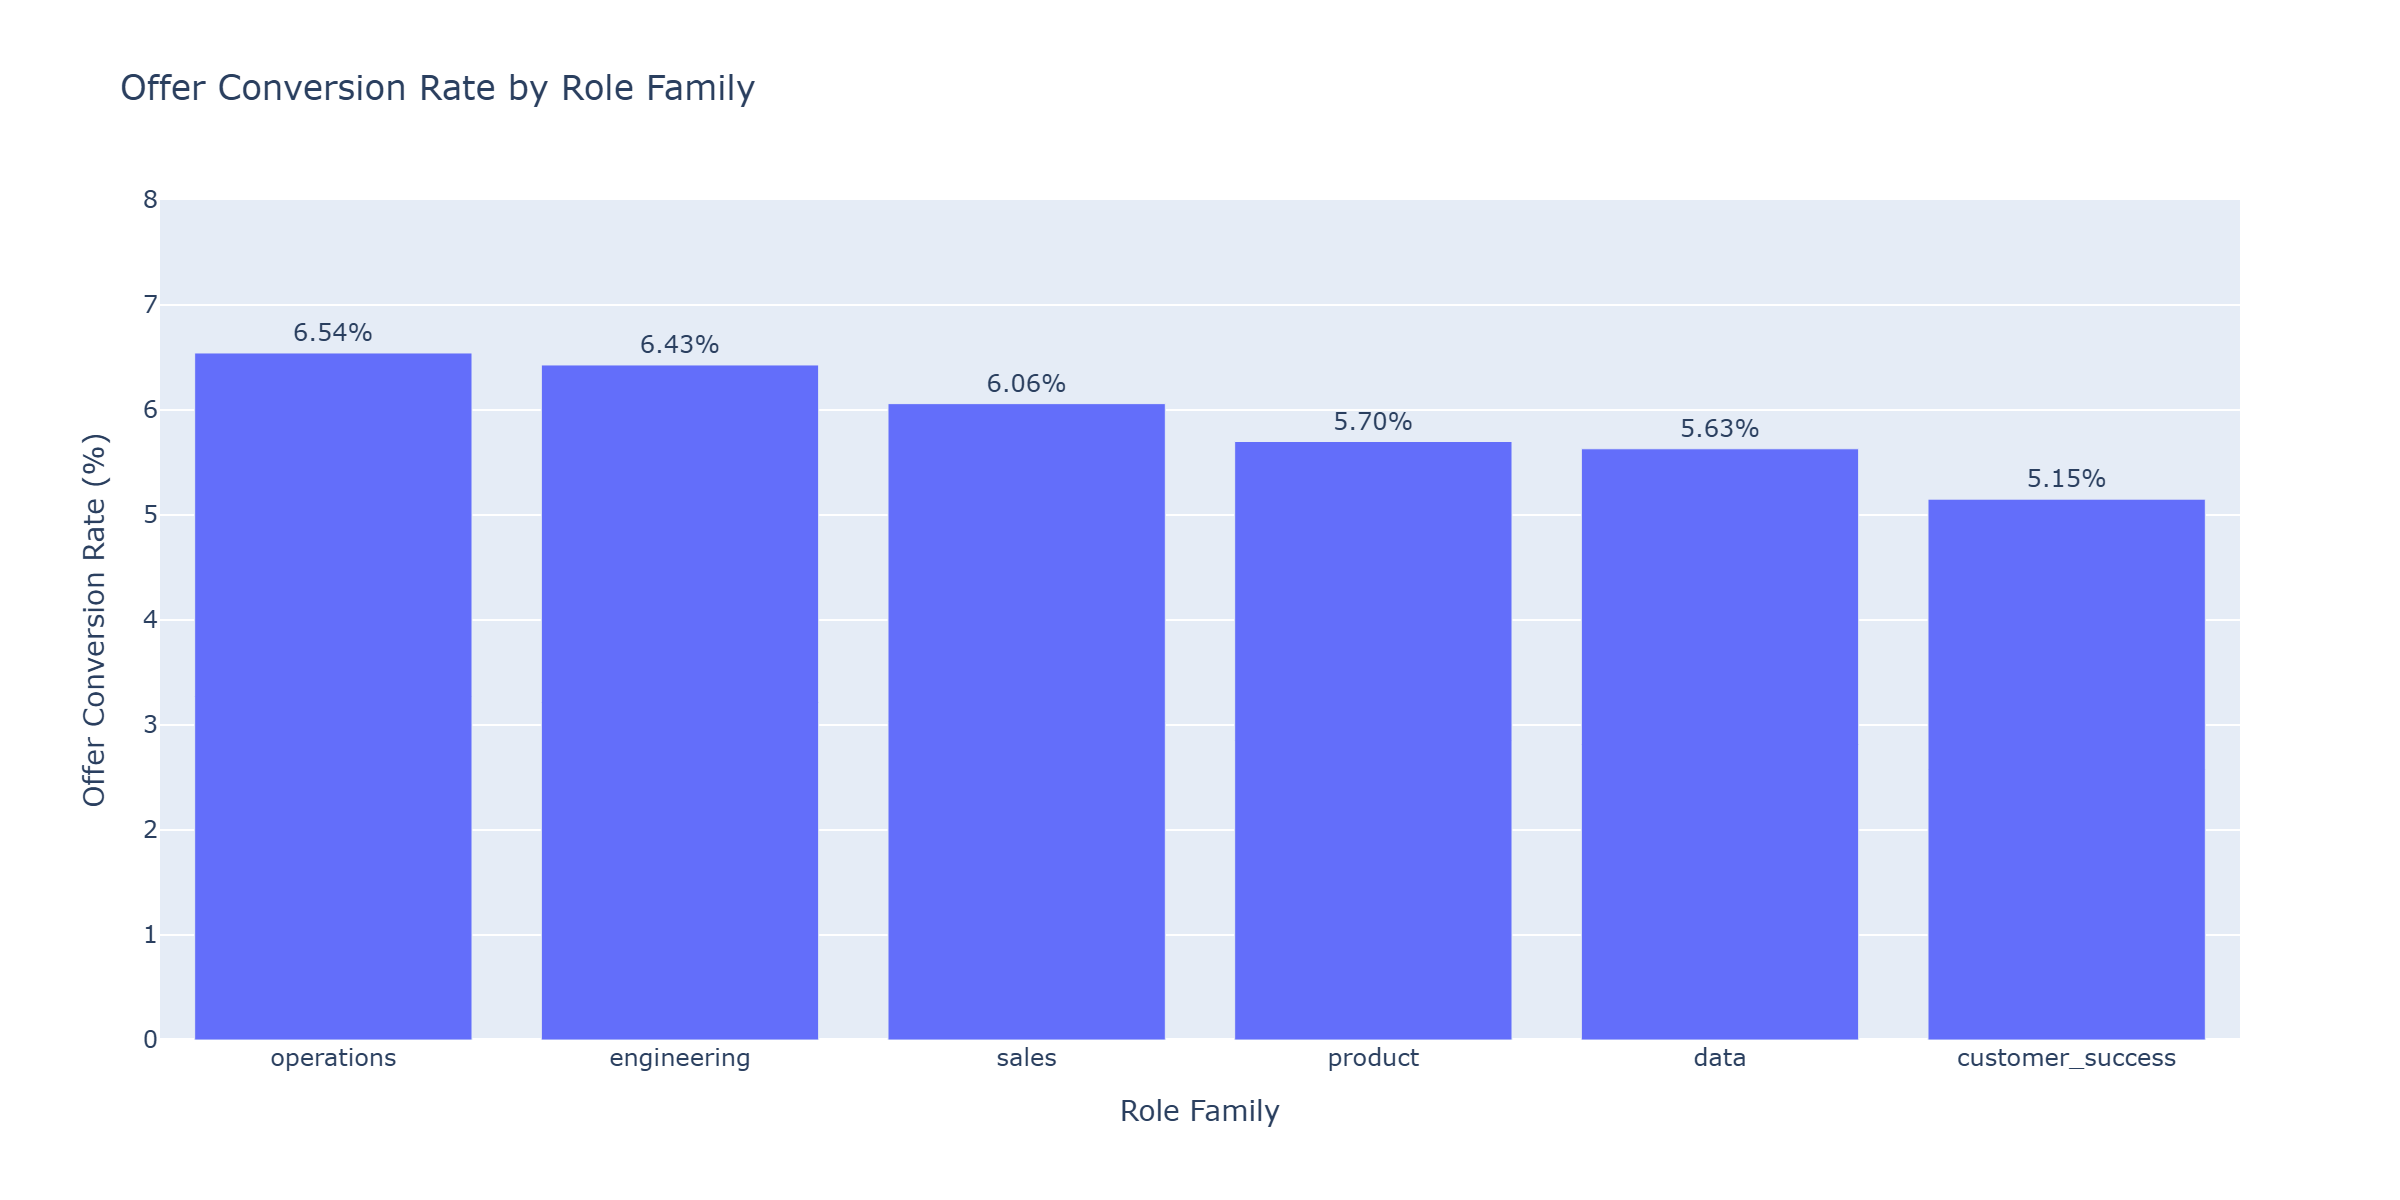

In [109]:
# Create a bar chart comparing offer rates by role family
fig = px.bar(
    role_summary,
    x="role_family",
    y="Offer_Rate",
    text="Offer_Rate",
    title="Offer Conversion Rate by Role Family"
)

# Display percentages above each bar
fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside",
    hovertemplate="<b>%{x}</b><extra></extra>Offer Rate: %{y:.2f}%"
)

# Improve chart labels and layout
fig.update_layout(
    xaxis_title="Role Family",
    yaxis_title="Offer Conversion Rate (%)",
    yaxis_range=[0, 8],
    showlegend=False
)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

### Step 6 — Offer Conversion Rate by Seniority Level

In [110]:
# Count applications and offers by seniority level
level_summary = hiring_analysis.groupby("level").agg(
    Applications=("application_id", "count"),
    Offers=("Received_Offer", "sum")
).reset_index()

# Calculate offer conversion rate for each seniority level
level_summary["Offer_Rate"] = (
    level_summary["Offers"] / level_summary["Applications"] * 100
)

# Sort seniority levels from highest to lowest offer rate
level_summary = level_summary.sort_values("Offer_Rate", ascending=False)

# Display the results
display(level_summary.round(2))

,level,Applications,Offers,Offer_Rate
1,lead,1975,131,6.63
2,mid,5587,369,6.60
0,junior,1856,114,6.14
3,senior,5582,324,5.80


### Step 7 — Visualize Offer Conversion by Seniority Level

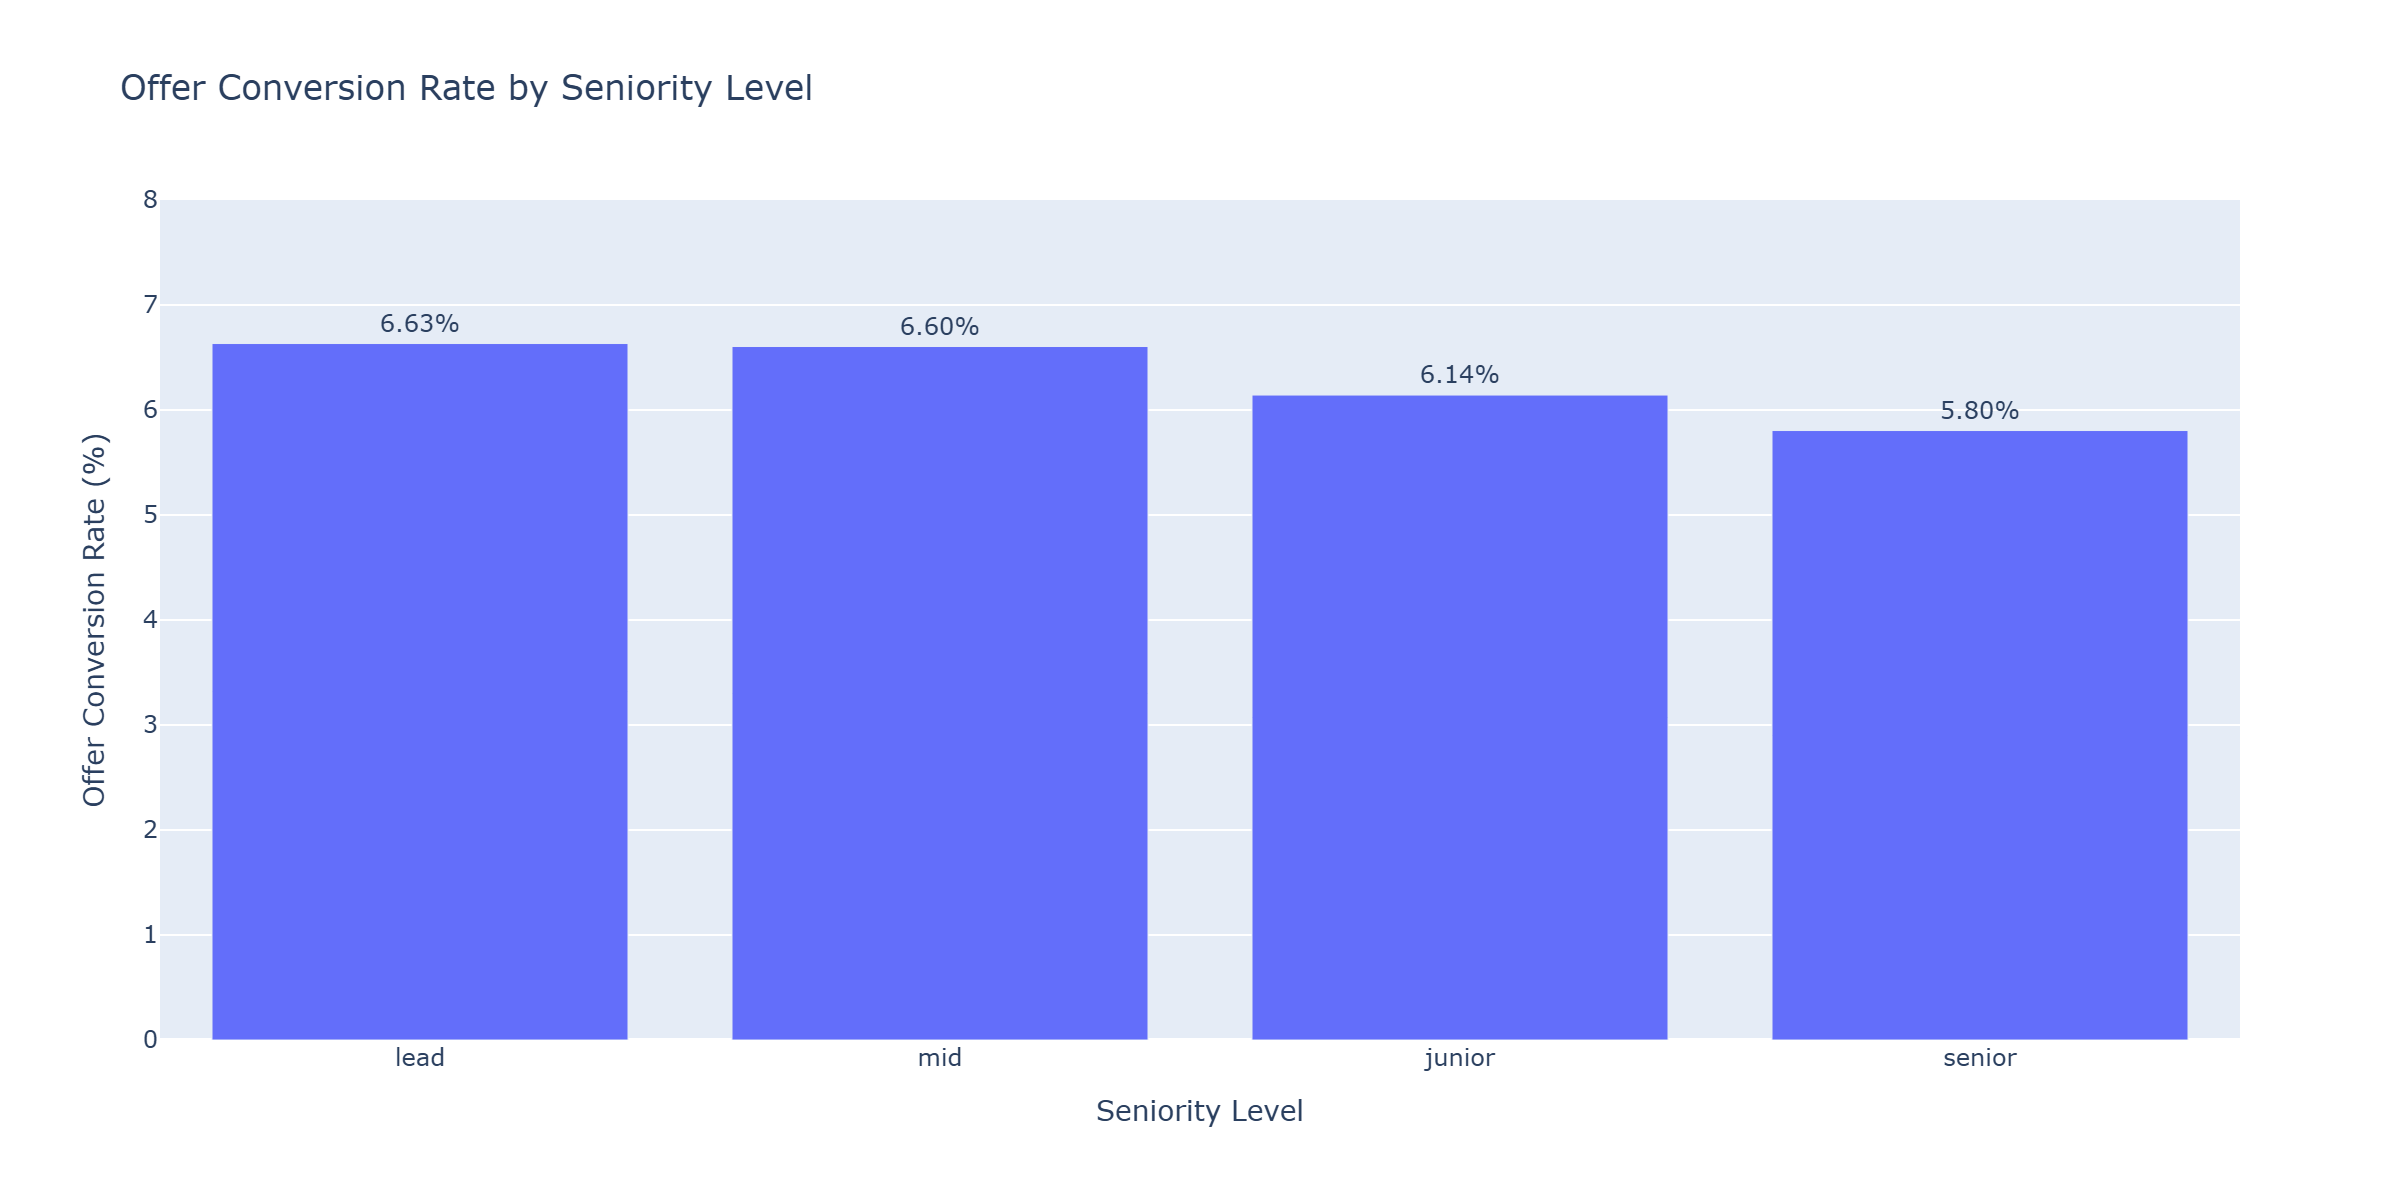

In [111]:
# Create a bar chart comparing offer rates by seniority level
fig = px.bar(
    level_summary,
    x="level",
    y="Offer_Rate",
    text="Offer_Rate",
    title="Offer Conversion Rate by Seniority Level"
)

# Display percentages above each bar
fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside",
    hovertemplate="<b>%{x}</b><extra></extra>Offer Rate: %{y:.2f}%"
)

# Improve chart labels and layout
fig.update_layout(
    xaxis_title="Seniority Level",
    yaxis_title="Offer Conversion Rate (%)",
    yaxis_range=[0, 8],
    showlegend=False
)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

### Step 8 — Offer Conversion by Role Family AND Seniority Level

In [112]:
# Count applications and offers by role family and seniority level
role_level_summary = hiring_analysis.groupby(
    ["role_family", "level"]
).agg(
    Applications=("application_id", "count"),
    Offers=("Received_Offer", "sum")
).reset_index()

# Calculate the offer conversion rate
role_level_summary["Offer_Rate"] = (
    role_level_summary["Offers"] / role_level_summary["Applications"] * 100
)

# Sort by role family and seniority level
role_level_summary = role_level_summary.sort_values(
    ["role_family", "level"]
)

# Display the results
display(role_level_summary.round(2))

,role_family,level,Applications,Offers,Offer_Rate
0,customer_success,junior,103,6,5.83
1,customer_success,lead,41,5,12.20
2,customer_success,mid,194,10,5.15
3,customer_success,senior,225,8,3.56
4,data,junior,291,19,6.53
5,data,lead,376,20,5.32
6,data,mid,773,50,6.47
7,data,senior,851,40,4.70
8,engineering,junior,445,23,5.17
9,engineering,lead,368,29,7.88


### Step 9 — Create our Plotly Heatmap

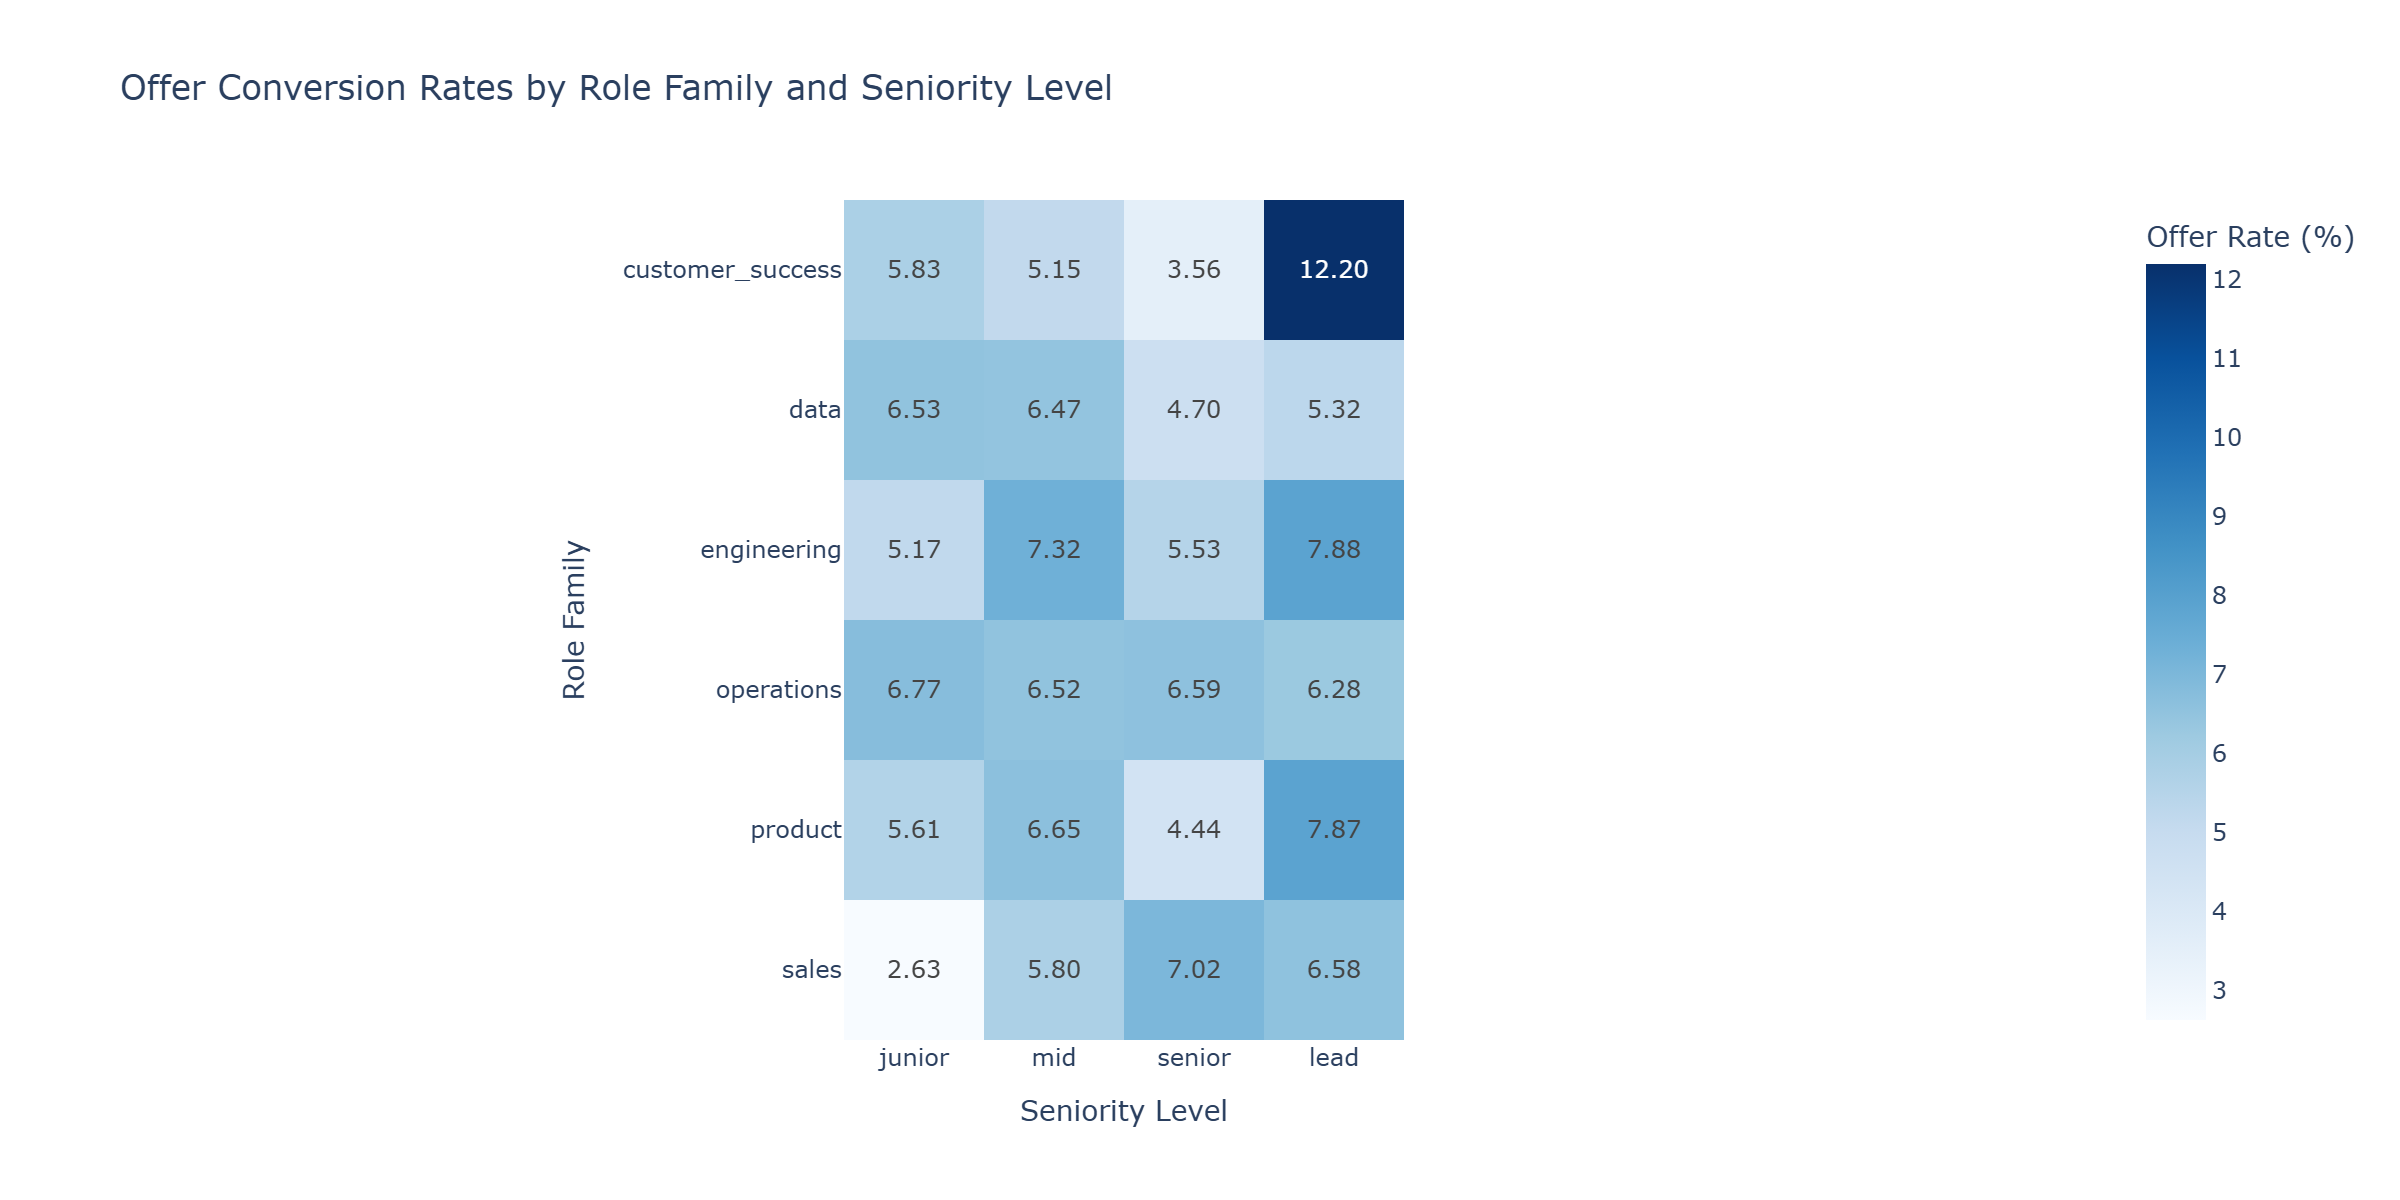

In [113]:
# Reshape offer conversion rates into a table for the heatmap
heatmap_df = role_level_summary.pivot(
    index="role_family",
    columns="level",
    values="Offer_Rate"
)

# Arrange seniority levels in a logical order
heatmap_df = heatmap_df[["junior", "mid", "senior", "lead"]]

# Create the heatmap
fig = px.imshow(
    heatmap_df,
    text_auto=".2f",
    color_continuous_scale="Blues",
    labels={
        "x": "Seniority Level",
        "y": "Role Family",
        "color": "Offer Rate (%)"
    },
    title="Offer Conversion Rates by Role Family and Seniority Level"
)

# Improve chart layout
fig.update_layout(
    height=550,
    xaxis_title="Seniority Level",
    yaxis_title="Role Family"
)
# Increase the heatmap's width and height
fig.update_layout(
    width=950,
    height=600
)

# Display the heatmap
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)


### Business Question #3 — Hiring Difficulty by Job Type

#### Key Findings

- **Operations** recorded the highest overall offer conversion rate (6.54%), followed closely by Engineering (6.43%).
- **Customer Success** recorded the lowest overall offer conversion rate (5.15%), followed by Data (5.63%) and Product (5.70%).
- **Lead (6.63%) and Mid-level (6.60%)** positions had the highest offer conversion rates across seniority levels.
- **Senior positions** recorded the lowest overall offer conversion rate (5.80%), despite receiving 5,582 applications.
- **Senior Data (4.70%) and Senior Engineering (5.53%)** had lower offer conversion rates than their respective Mid-level positions (6.47% and 7.32%).
- **Operations** showed relatively consistent conversion rates across all four seniority levels, ranging from 6.28% to 6.77%.
- **Lead Customer Success** recorded the highest individual conversion rate (12.20%), but this represents only 5 offers from 41 applications.
- **Junior Sales** recorded the lowest individual conversion rate (2.63%), based on just 1 offer from 38 applications.

#### Business Insights & Recommendations

- **Review senior-level recruitment:** Investigate whether lower offer conversion rates reflect specialized job requirements, candidate qualification gaps, or more selective screening.
- **Examine Data and Engineering recruitment:** Assess candidate qualifications and screening criteria for senior positions, where conversion rates are comparatively low.
- **Investigate Customer Success recruitment:** Review application quality and recruitment processes to understand its relatively low overall offer conversion rate.
- **Use Operations as a comparison:** Examine whether its relatively consistent conversion rates across seniority levels offer useful recruitment process insights.
- **Monitor smaller recruitment segments:** Avoid making major recruitment decisions based on unusually high or low conversion rates from small application groups.
- **Improve recruitment performance tracking:** Include qualified applicant rates, interview conversion, time-to-fill, and vacancy outcomes to better understand actual hiring difficulty.

#### Analytical Limitations

- Offer conversion rates are used as an indirect indicator of hiring difficulty; they do not directly measure how difficult a position is to fill.
- Applications without offers may still be progressing through recruitment and should not automatically be classified as rejected.
- Differences in conversion rates may reflect candidate qualifications, screening criteria, hiring demand, or recruitment practices.
- Some role family and seniority combinations have relatively small application and offer counts.
- The analysis uses a synthetic recruitment dataset, so findings should not be generalized to actual recruitment markets.
- Statistical significance will be evaluated separately in `Statistics.ipynb`.


# Q4 — Recruitment Process Efficiency

**Business question:** How long does it take from application to first scheduled interview and to offer?

### Step 1 — Identify the First Scheduled Interview

In [114]:
# Find the earliest scheduled interview date for each application
first_interview = interviews.groupby("application_id")["scheduled_at"].min()

# Convert the result into a DataFrame
first_interview = first_interview.reset_index()

# Rename the date column for clarity
first_interview = first_interview.rename(
    columns={"scheduled_at": "first_interview_at"}
)

# Display the number of applications with interviews
print("Applications with interviews:", len(first_interview))

# Preview the results
display(first_interview.head())

Applications with interviews: 3570


,application_id,first_interview_at
0,2,2025-07-31 01:17:20
1,4,2025-10-19 01:22:15
2,8,2025-05-28 01:49:44
3,9,2025-03-26 08:07:38
4,10,2024-11-03 09:42:14


### Step 2 — Calculate Time from Application to First Interview

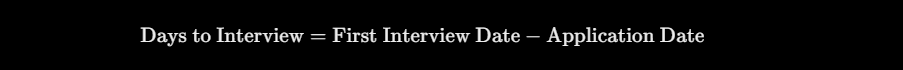

In [115]:
# Select application IDs and application dates
application_dates = applications[["application_id", "applied_at"]]

# Merge application dates with first interview dates
interview_timeline = first_interview.merge(
    application_dates,
    on="application_id",
    how="left"
)

# Calculate the number of days from application to first interview
interview_timeline["Days_to_Interview"] = (
    interview_timeline["first_interview_at"]
    - interview_timeline["applied_at"]
).dt.total_seconds() / 86400

# Verify the number of records and check for negative durations
print("Applications with interviews:", len(interview_timeline))
print("Missing application dates:", interview_timeline["applied_at"].isna().sum())
print("Negative interview durations:", (interview_timeline["Days_to_Interview"] < 0).sum())

# Preview the results
display(interview_timeline.head())

Applications with interviews: 3570
Missing application dates: 0
Negative interview durations: 0


,application_id,first_interview_at,applied_at,Days_to_Interview
0,2,2025-07-31 01:17:20,2025-07-18 01:17:20,13.00
1,4,2025-10-19 01:22:15,2025-10-09 01:22:15,10.00
2,8,2025-05-28 01:49:44,2025-05-16 01:49:44,12.00
3,9,2025-03-26 08:07:38,2025-03-13 08:07:38,13.00
4,10,2024-11-03 09:42:14,2024-10-27 09:42:14,7.00


### Step 3 — Recruitment Timeline Summary Statistics

In [116]:
# Calculate summary statistics for time to first interview
interview_stats = interview_timeline["Days_to_Interview"].describe()

# Display the results
display(interview_stats.round(2))

count   3570.00
mean      12.42
std        3.69
min        5.00
25%        9.00
50%       12.00
75%       15.00
max       20.00
Name: Days_to_Interview, dtype: float64

#### Initial Findings — Time to First Scheduled Interview

- Mean waiting time: **12.42 days**; median: **12 days**.
- Middle 50%: **9–15 days**.
- Shortest recorded duration: **5 days**; longest: **20 days**.
- Dates refer to the scheduled first interview, **not** the date the interview was arranged or confirmed as completed.

### Step 4 — Visualize Time to First Interview

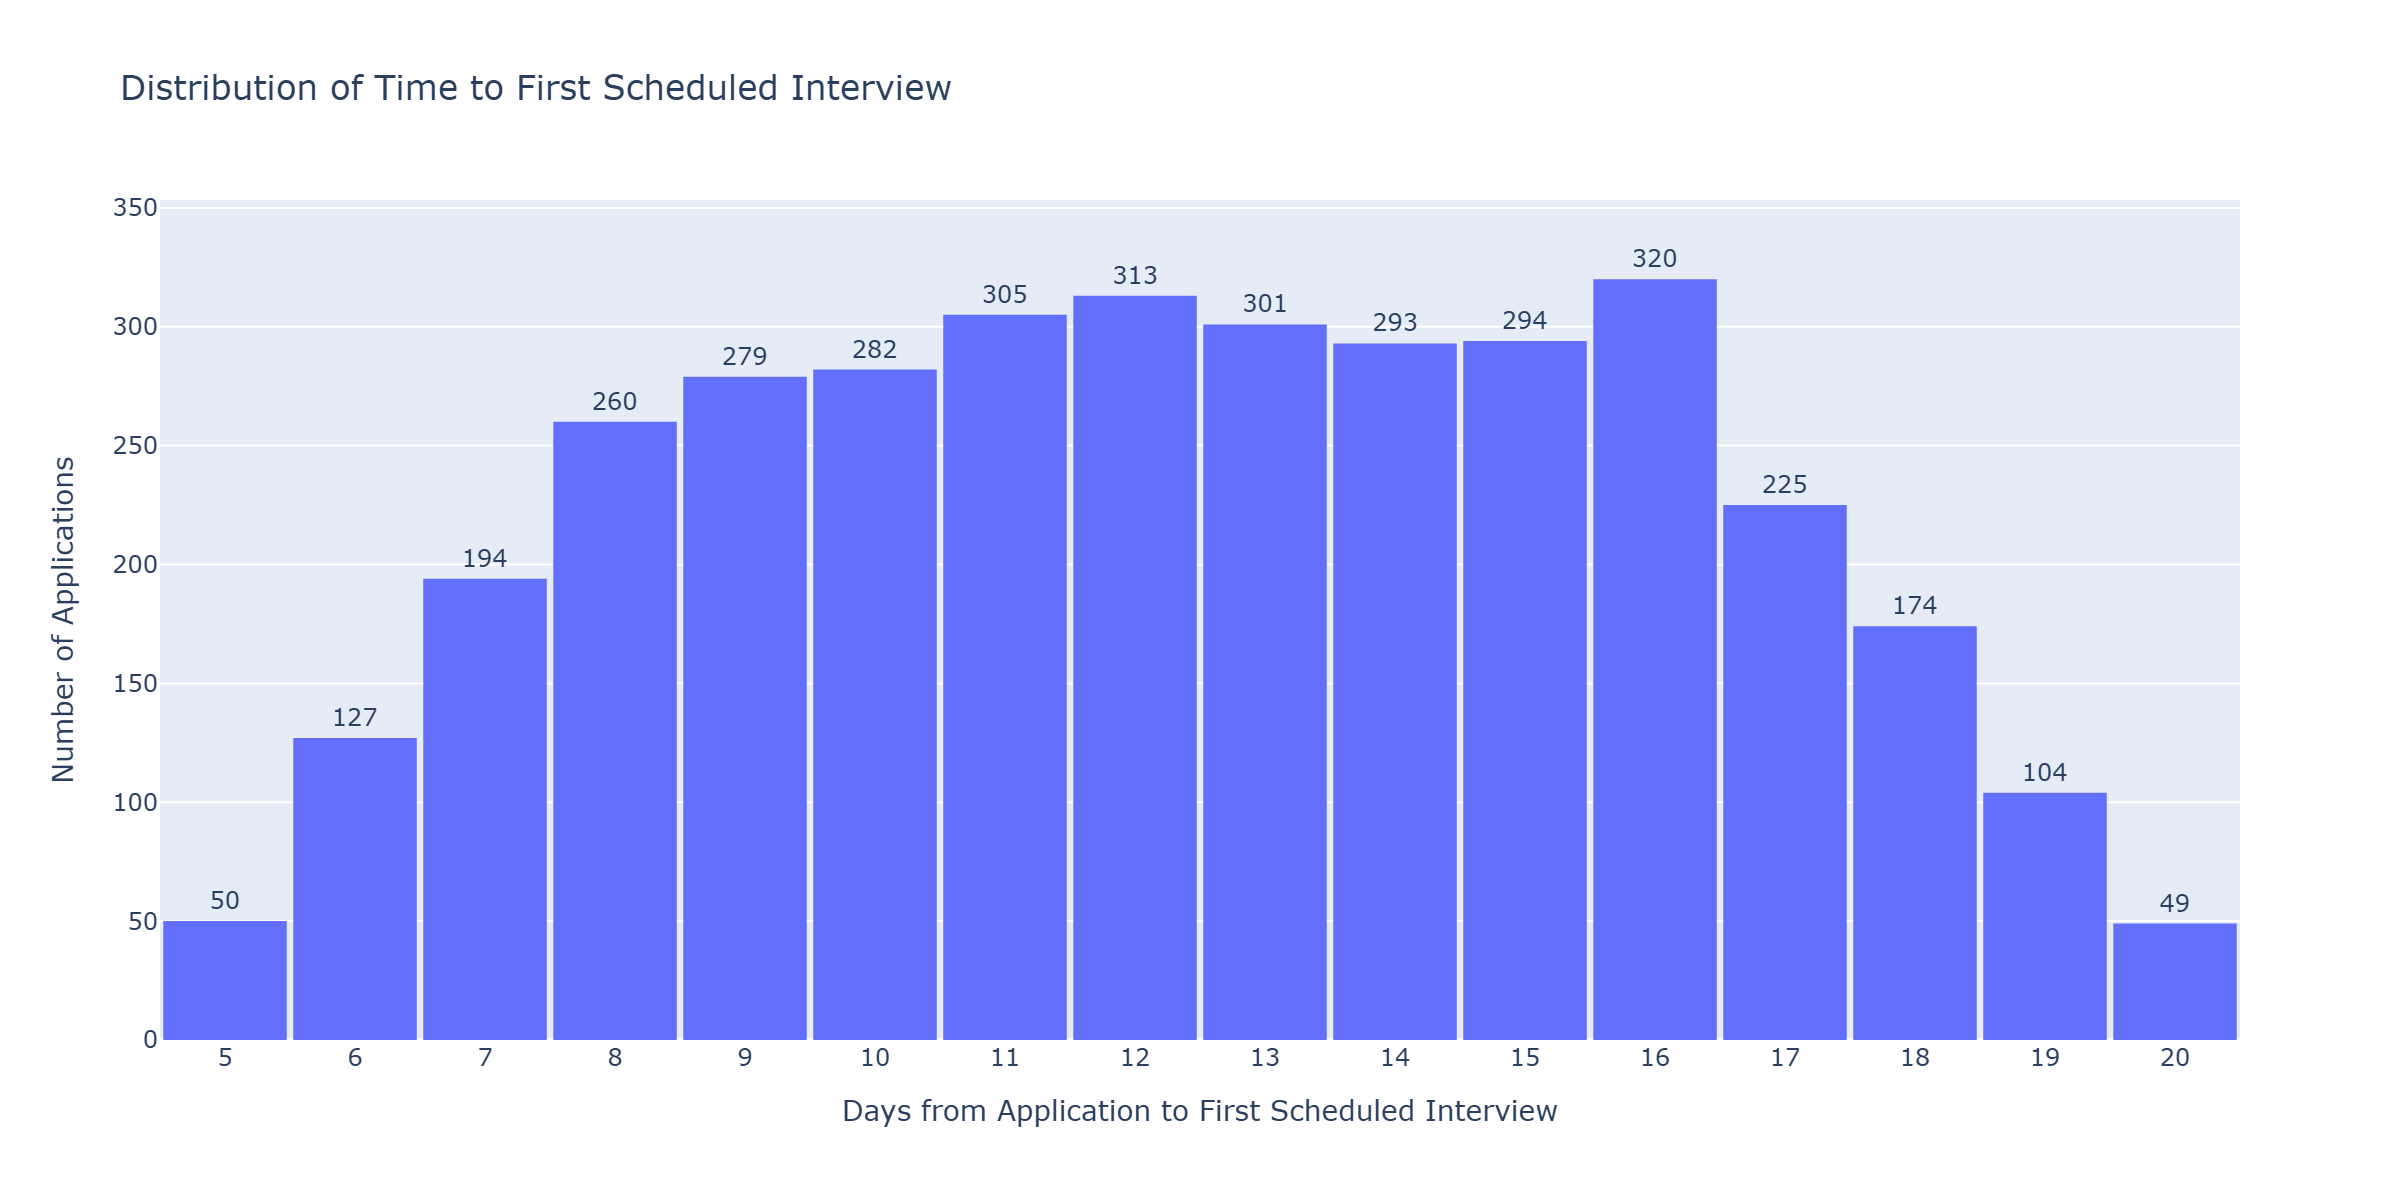

In [117]:
# Create a histogram of days to first scheduled interview
fig = px.histogram(
    interview_timeline,
    x="Days_to_Interview",
    nbins=16,
    title="Distribution of Time to First Scheduled Interview"
)

# Display the number of applications above each bar
fig.update_traces(
    texttemplate="%{y}",
    textposition="outside"
)

# Improve chart layout
fig.update_layout(
    xaxis_title="Days from Application to First Scheduled Interview",
    yaxis_title="Number of Applications",
    bargap=0.05,
    showlegend=False
)

# Display whole-day values on the horizontal axis
fig.update_xaxes(dtick=1)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)


#### Visualization — Time to First Scheduled Interview

**Why a Histogram?**

- `Days_to_Interview` is a numerical variable representing elapsed time between application and the first scheduled interview.
- A histogram displays the frequency distribution of numerical values, allowing us to examine how interview waiting times are distributed.
- Unlike a bar chart, which compares distinct categories, a histogram groups numerical observations into intervals (bins).
- Since our dataset contains whole-day durations ranging from 5 to 20 days, we selected one-day intervals to display the frequency of each waiting time.
- This visualization helps identify common waiting periods, the spread of recruitment timelines, and unusually short or long durations.
- The histogram complements our descriptive statistics, including the mean (12.42 days), median (12 days), and standard deviation (3.69 days).


### Step 5 — Calculate Time from Application to Offer

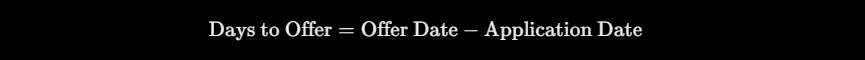

In [118]:
# Select application IDs and offer dates
offer_dates = offers[["application_id", "offered_at"]]

# Select application IDs and application dates
application_dates = applications[["application_id", "applied_at"]]

# Merge offer dates with application dates
offer_timeline = offer_dates.merge(
    application_dates,
    on="application_id",
    how="left"
)

# Calculate the number of days from application to offer
offer_timeline["Days_to_Offer"] = (
    offer_timeline["offered_at"] - offer_timeline["applied_at"]
).dt.total_seconds() / 86400

# Verify the results
print("Applications with offers:", len(offer_timeline))
print("Missing application dates:", offer_timeline["applied_at"].isna().sum())
print("Negative offer durations:", (offer_timeline["Days_to_Offer"] < 0).sum())

# Preview the results
display(offer_timeline.head())

Applications with offers: 938
Missing application dates: 0
Negative offer durations: 0


,application_id,offered_at,applied_at,Days_to_Offer
0,8,2025-06-24 01:49:44,2025-05-16 01:49:44,39.00
1,13,2025-01-31 20:46:02,2025-01-17 20:46:02,14.00
2,25,2024-12-01 02:55:22,2024-11-16 02:55:22,15.00
3,29,2025-05-27 06:18:41,2025-04-29 06:18:41,28.00
4,30,2026-01-03 10:31:40,2025-12-20 10:31:40,14.00


### Step 6 — Calculate Time-to-Offer Statistics

In [119]:
# Calculate summary statistics for time from application to offer
offer_stats = offer_timeline["Days_to_Offer"].describe()

# Display the results rounded to two decimal places
display(offer_stats.round(2))

count   938.00
mean     28.70
std       8.94
min      14.00
25%      21.00
50%      28.00
75%      37.00
max      44.00
Name: Days_to_Offer, dtype: float64

### Step 7 — Visualize Time to Offer

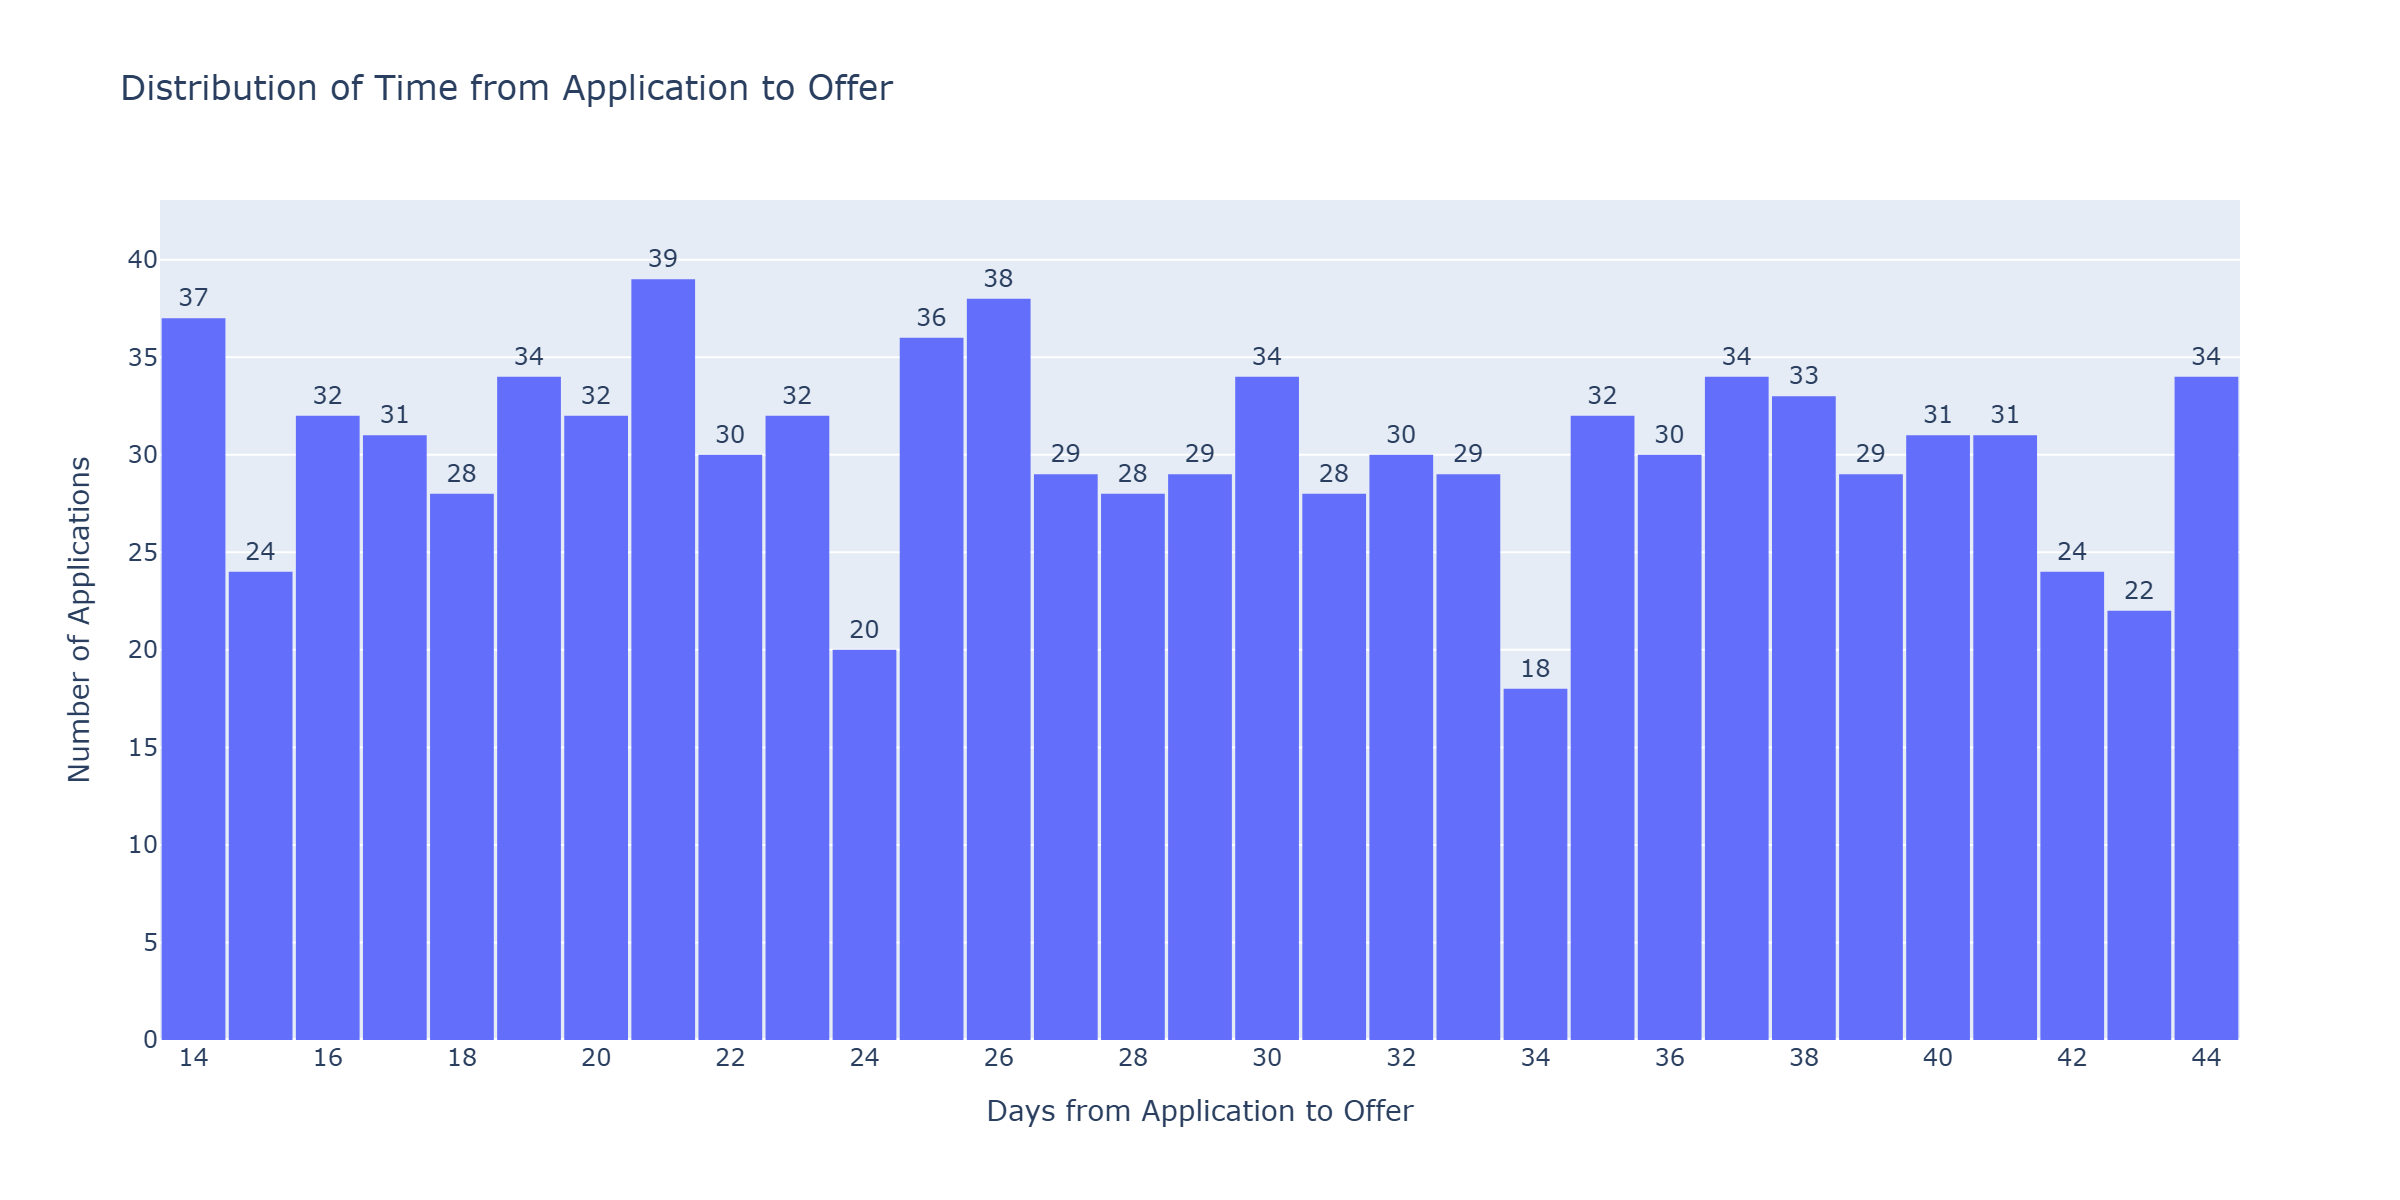

In [120]:
# Create a histogram of days from application to offer
fig = px.histogram(
    offer_timeline,
    x="Days_to_Offer",
    nbins=31,
    title="Distribution of Time from Application to Offer"
)

# Display application counts above each bar
fig.update_traces(
    texttemplate="%{y}",
    textposition="outside"
)

# Improve chart layout
fig.update_layout(
    xaxis_title="Days from Application to Offer",
    yaxis_title="Number of Applications",
    bargap=0.05,
    showlegend=False
)

# Display whole-day values on the horizontal axis
fig.update_xaxes(dtick=2)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

### Step 7 — Time-to-Offer Distribution Using Weekly-Style Intervals

#### Additional Visualization — Grouped Time-to-Offer Intervals

The original histogram displayed the full day-by-day distribution of `Days_to_Offer`, which preserves the most detailed view of the recruitment timeline. However, because the offer durations span many individual day values, the original chart appears visually crowded and does not clearly highlight broader patterns.

To improve interpretability, the same `Days_to_Offer` variable was also grouped into weekly-style intervals:

- 14–20 days  
- 21–27 days  
- 28–34 days  
- 35–41 days  
- 42–48 days  

This grouped view simplifies the distribution and makes it easier to identify the approximate time ranges in which most offers are made.

**Why keep both charts?**

- The **original histogram** preserves the detailed day-level distribution.
- The **grouped interval chart** provides a clearer summary for business interpretation and reporting.

Together, the two visualizations provide both analytical detail and a more accessible high-level summary of recruitment process efficiency.

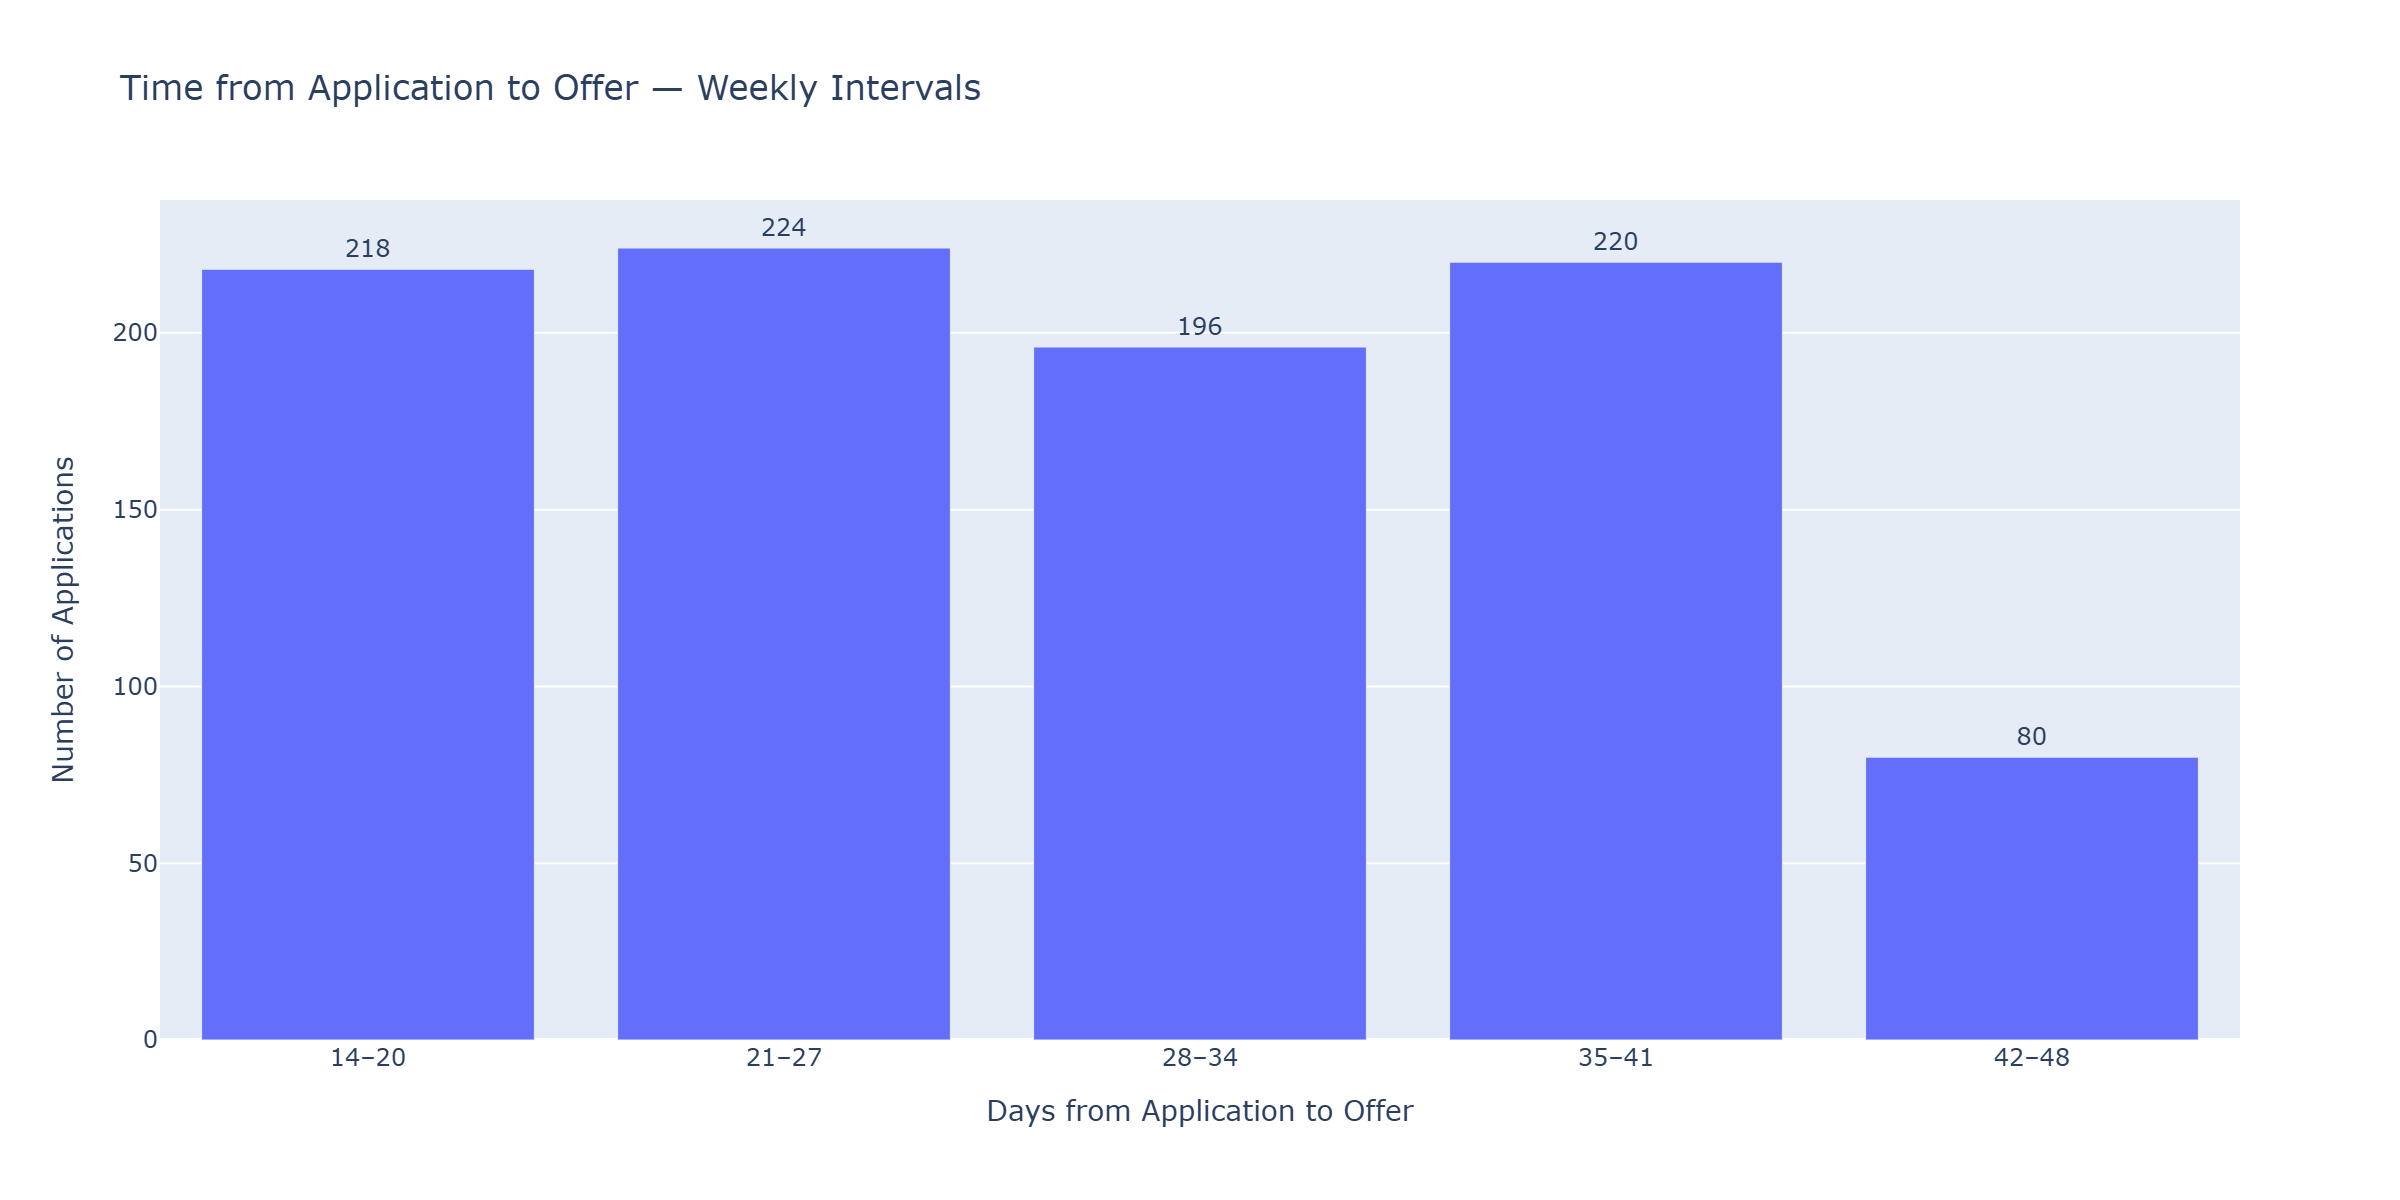

In [121]:
# Define weekly duration intervals
bins = [13, 20, 27, 34, 41, 48]

# Define descriptive labels for each interval
labels = ["14–20", "21–27", "28–34", "35–41", "42–48"]

# Group offer durations into weekly intervals
offer_timeline["Offer_Interval"] = pd.cut(
    offer_timeline["Days_to_Offer"],
    bins=bins,
    labels=labels
)

# Count applications within each interval
offer_interval_counts = offer_timeline["Offer_Interval"].value_counts().sort_index()

# Convert results into a DataFrame
offer_interval_df = offer_interval_counts.reset_index()

# Create a bar chart of grouped offer durations
fig = px.bar(
    offer_interval_df,
    x="Offer_Interval",
    y="count",
    text="count",
    title="Time from Application to Offer — Weekly Intervals"
)

# Display application counts above each bar
fig.update_traces(textposition="outside")

# Improve chart labels and layout
fig.update_layout(
    xaxis_title="Days from Application to Offer",
    yaxis_title="Number of Applications",
    showlegend=False
)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

### Step 8 — Calculate Time from First Scheduled Interview to Offer

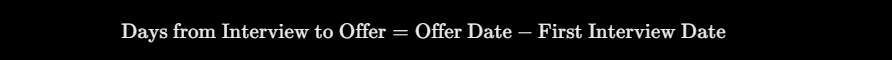

In [122]:
# Select application IDs and first scheduled interview dates
first_interview_dates = interview_timeline[
    ["application_id", "first_interview_at"]
]

# Merge first interview dates with offer timelines
interview_offer_timeline = offer_timeline.merge(
    first_interview_dates,
    on="application_id",
    how="left"
)

# Calculate days between first scheduled interview and offer
interview_offer_timeline["Days_Interview_to_Offer"] = (
    interview_offer_timeline["offered_at"]
    - interview_offer_timeline["first_interview_at"]
).dt.total_seconds() / 86400

# Verify the results
print("Applications with offers:", len(interview_offer_timeline))
print("Missing interview dates:", interview_offer_timeline["first_interview_at"].isna().sum())
print("Negative durations:", (interview_offer_timeline["Days_Interview_to_Offer"] < 0).sum())

# Display the first five records
display(interview_offer_timeline.head())

Applications with offers: 938
Missing interview dates: 0
Negative durations: 29


,application_id,offered_at,applied_at,Days_to_Offer,Offer_Interval,first_interview_at,Days_Interview_to_Offer
0,8,2025-06-24 01:49:44,2025-05-16 01:49:44,39.00,35–41,2025-05-28 01:49:44,27.00
1,13,2025-01-31 20:46:02,2025-01-17 20:46:02,14.00,14–20,2025-01-30 20:46:02,1.00
2,25,2024-12-01 02:55:22,2024-11-16 02:55:22,15.00,14–20,2024-11-28 02:55:22,3.00
3,29,2025-05-27 06:18:41,2025-04-29 06:18:41,28.00,28–34,2025-05-12 06:18:41,15.00
4,30,2026-01-03 10:31:40,2025-12-20 10:31:40,14.00,14–20,2026-01-06 10:31:40,-3.00


### Step 9 — Flag the anomalies

In [123]:
# Initially classify all interview-to-offer timelines as valid
interview_offer_timeline["Timeline_Validation"] = "valid_date"

# Flag records where the first scheduled interview occurs after the offer
interview_offer_timeline.loc[
    interview_offer_timeline["Days_Interview_to_Offer"] < 0,
    "Timeline_Validation"
] = "chronology_exception"

# Count records in each validation category
display(interview_offer_timeline["Timeline_Validation"].value_counts())

Timeline_Validation
valid_date              909
chronology_exception     29
Name: count, dtype: int64

### Step 10 — Create a separate DataFrame for duration analysis

In [124]:
# Select records with chronologically consistent interview-to-offer dates
valid_interview_offer = interview_offer_timeline[
    interview_offer_timeline["Timeline_Validation"] == "valid_date"
].copy()

# Calculate descriptive statistics for valid durations
interview_offer_stats = valid_interview_offer["Days_Interview_to_Offer"].describe()

# Display summary statistics
display(interview_offer_stats.round(2))

count   909.00
mean     16.65
std       9.31
min       0.00
25%       9.00
50%      17.00
75%      24.00
max      38.00
Name: Days_Interview_to_Offer, dtype: float64

### Step 11 — Comparative Box Plot

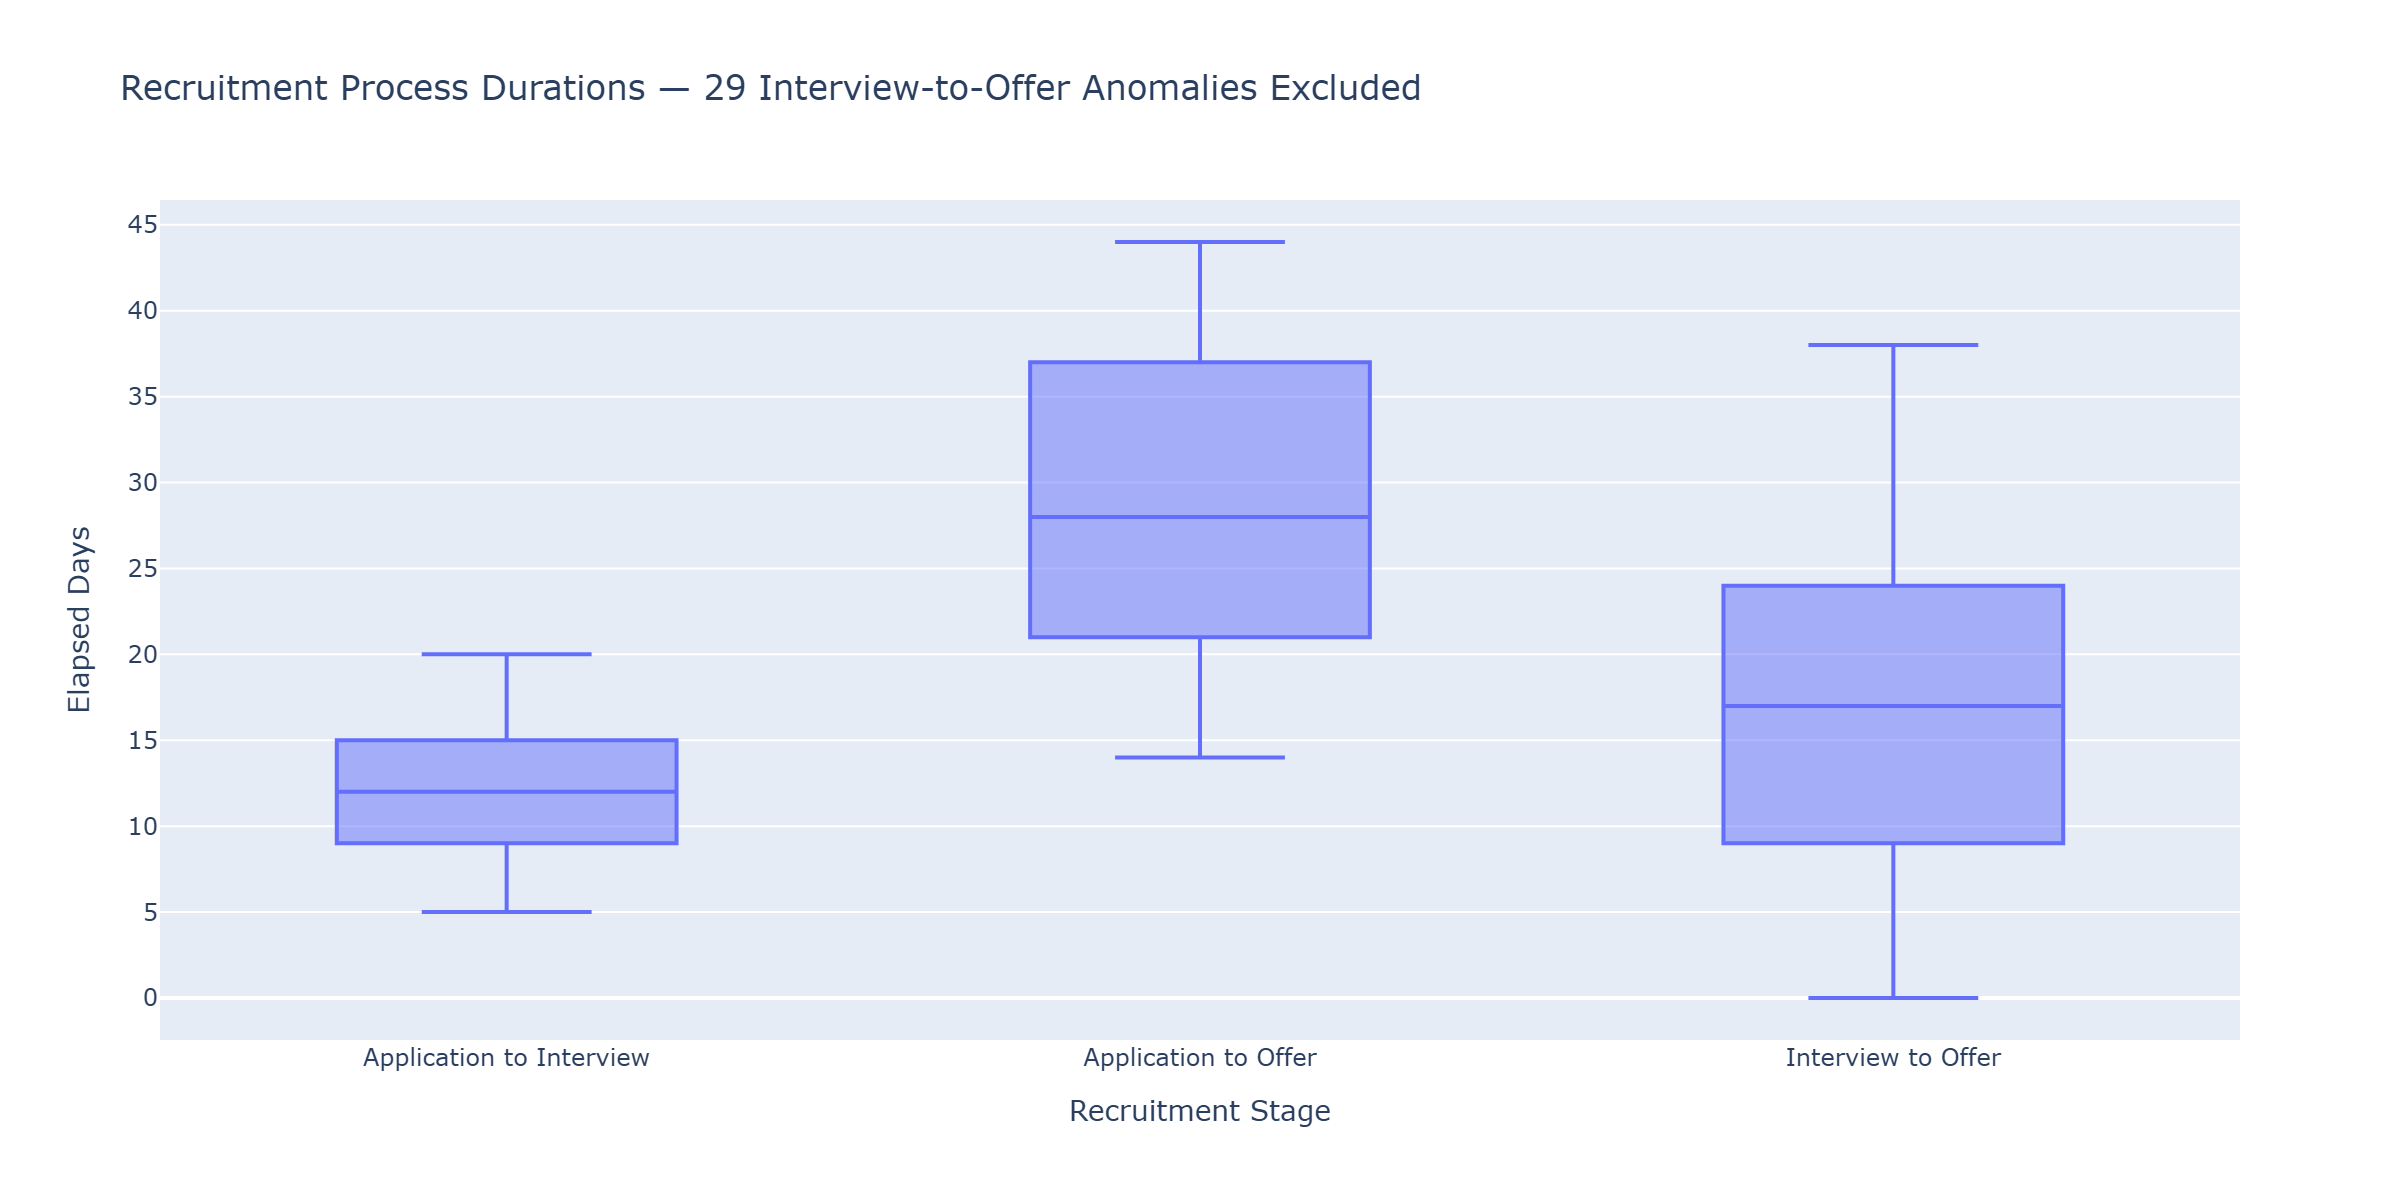

In [125]:
# Select interview waiting times
interview_box = interview_timeline[["Days_to_Interview"]].copy()
interview_box = interview_box.rename(columns={"Days_to_Interview": "Days"})
interview_box["Stage"] = "Application to Interview"

# Select application-to-offer waiting times
offer_box = offer_timeline[["Days_to_Offer"]].copy()
offer_box = offer_box.rename(columns={"Days_to_Offer": "Days"})
offer_box["Stage"] = "Application to Offer"

# Select valid interview-to-offer waiting times
interview_offer_box = valid_interview_offer[["Days_Interview_to_Offer"]].copy()
interview_offer_box = interview_offer_box.rename(
    columns={"Days_Interview_to_Offer": "Days"}
)
interview_offer_box["Stage"] = "Interview to Offer"

# Combine all three durations into one DataFrame
duration_box = pd.concat(
    [interview_box, offer_box, interview_offer_box],
    ignore_index=True
)

# Create the comparative box plot
fig = px.box(
    duration_box,
    x="Stage",
    y="Days",
    points=False,
    title="Recruitment Process Durations — 29 Interview-to-Offer Anomalies Excluded"
)

# Improve chart layout
fig.update_layout(
    xaxis_title="Recruitment Stage",
    yaxis_title="Elapsed Days",
    showlegend=False
)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)


#### Comparative Box Plot — Recruitment Process Durations

**Data Included:**

- **Application to First Interview:** 3,570 applications.
- **Application to Offer:** 938 applications.
- **First Interview to Offer:** 909 applications, excluding 29 negative-duration chronology exceptions.

**Analytical Decision:**

- The 29 chronology exceptions were excluded only from the First Interview-to-Offer duration analysis.
- All original records and timestamps were preserved.
- The exceptions may reflect the synthetic dataset's algorithmically generated timestamps rather than actual recruitment process errors.
- The box plots compare three distributions with different sample sizes and should not be interpreted as matched candidate observations.


### Step 12 — Add Role Families to the Recruitment Durations

In [126]:
# Prepare application-to-interview durations
interview_role = interview_timeline[
    ["application_id", "Days_to_Interview"]
].copy()

interview_role = interview_role.rename(
    columns={"Days_to_Interview": "Days"}
)
interview_role["Stage"] = "Application to Interview"


# Prepare application-to-offer durations
offer_role = offer_timeline[
    ["application_id", "Days_to_Offer"]
].copy()

offer_role = offer_role.rename(
    columns={"Days_to_Offer": "Days"}
)
offer_role["Stage"] = "Application to Offer"


# Prepare chronologically consistent interview-to-offer durations
interview_offer_role = valid_interview_offer[
    ["application_id", "Days_Interview_to_Offer"]
].copy()

interview_offer_role = interview_offer_role.rename(
    columns={"Days_Interview_to_Offer": "Days"}
)
interview_offer_role["Stage"] = "Interview to Offer"


# Combine all three duration datasets
duration_by_role = pd.concat(
    [interview_role, offer_role, interview_offer_role],
    ignore_index=True
)

# Select application IDs and their role families
application_families = hiring_analysis[
    ["application_id", "role_family"]
]

# Add role family information to the duration dataset
duration_by_role = duration_by_role.merge(
    application_families,
    on="application_id",
    how="left"
)

# Verify the data
print("Missing role families:", duration_by_role["role_family"].isna().sum())

# Display a preview
display(duration_by_role.head())

Missing role families: 0


,application_id,Days,Stage,role_family
0,2,13.00,Application to Interview,operations
1,4,10.00,Application to Interview,engineering
2,8,12.00,Application to Interview,data
3,9,13.00,Application to Interview,data
4,10,7.00,Application to Interview,operations


### Step 13 — Visualize Recruitment Process Durations by Role Family

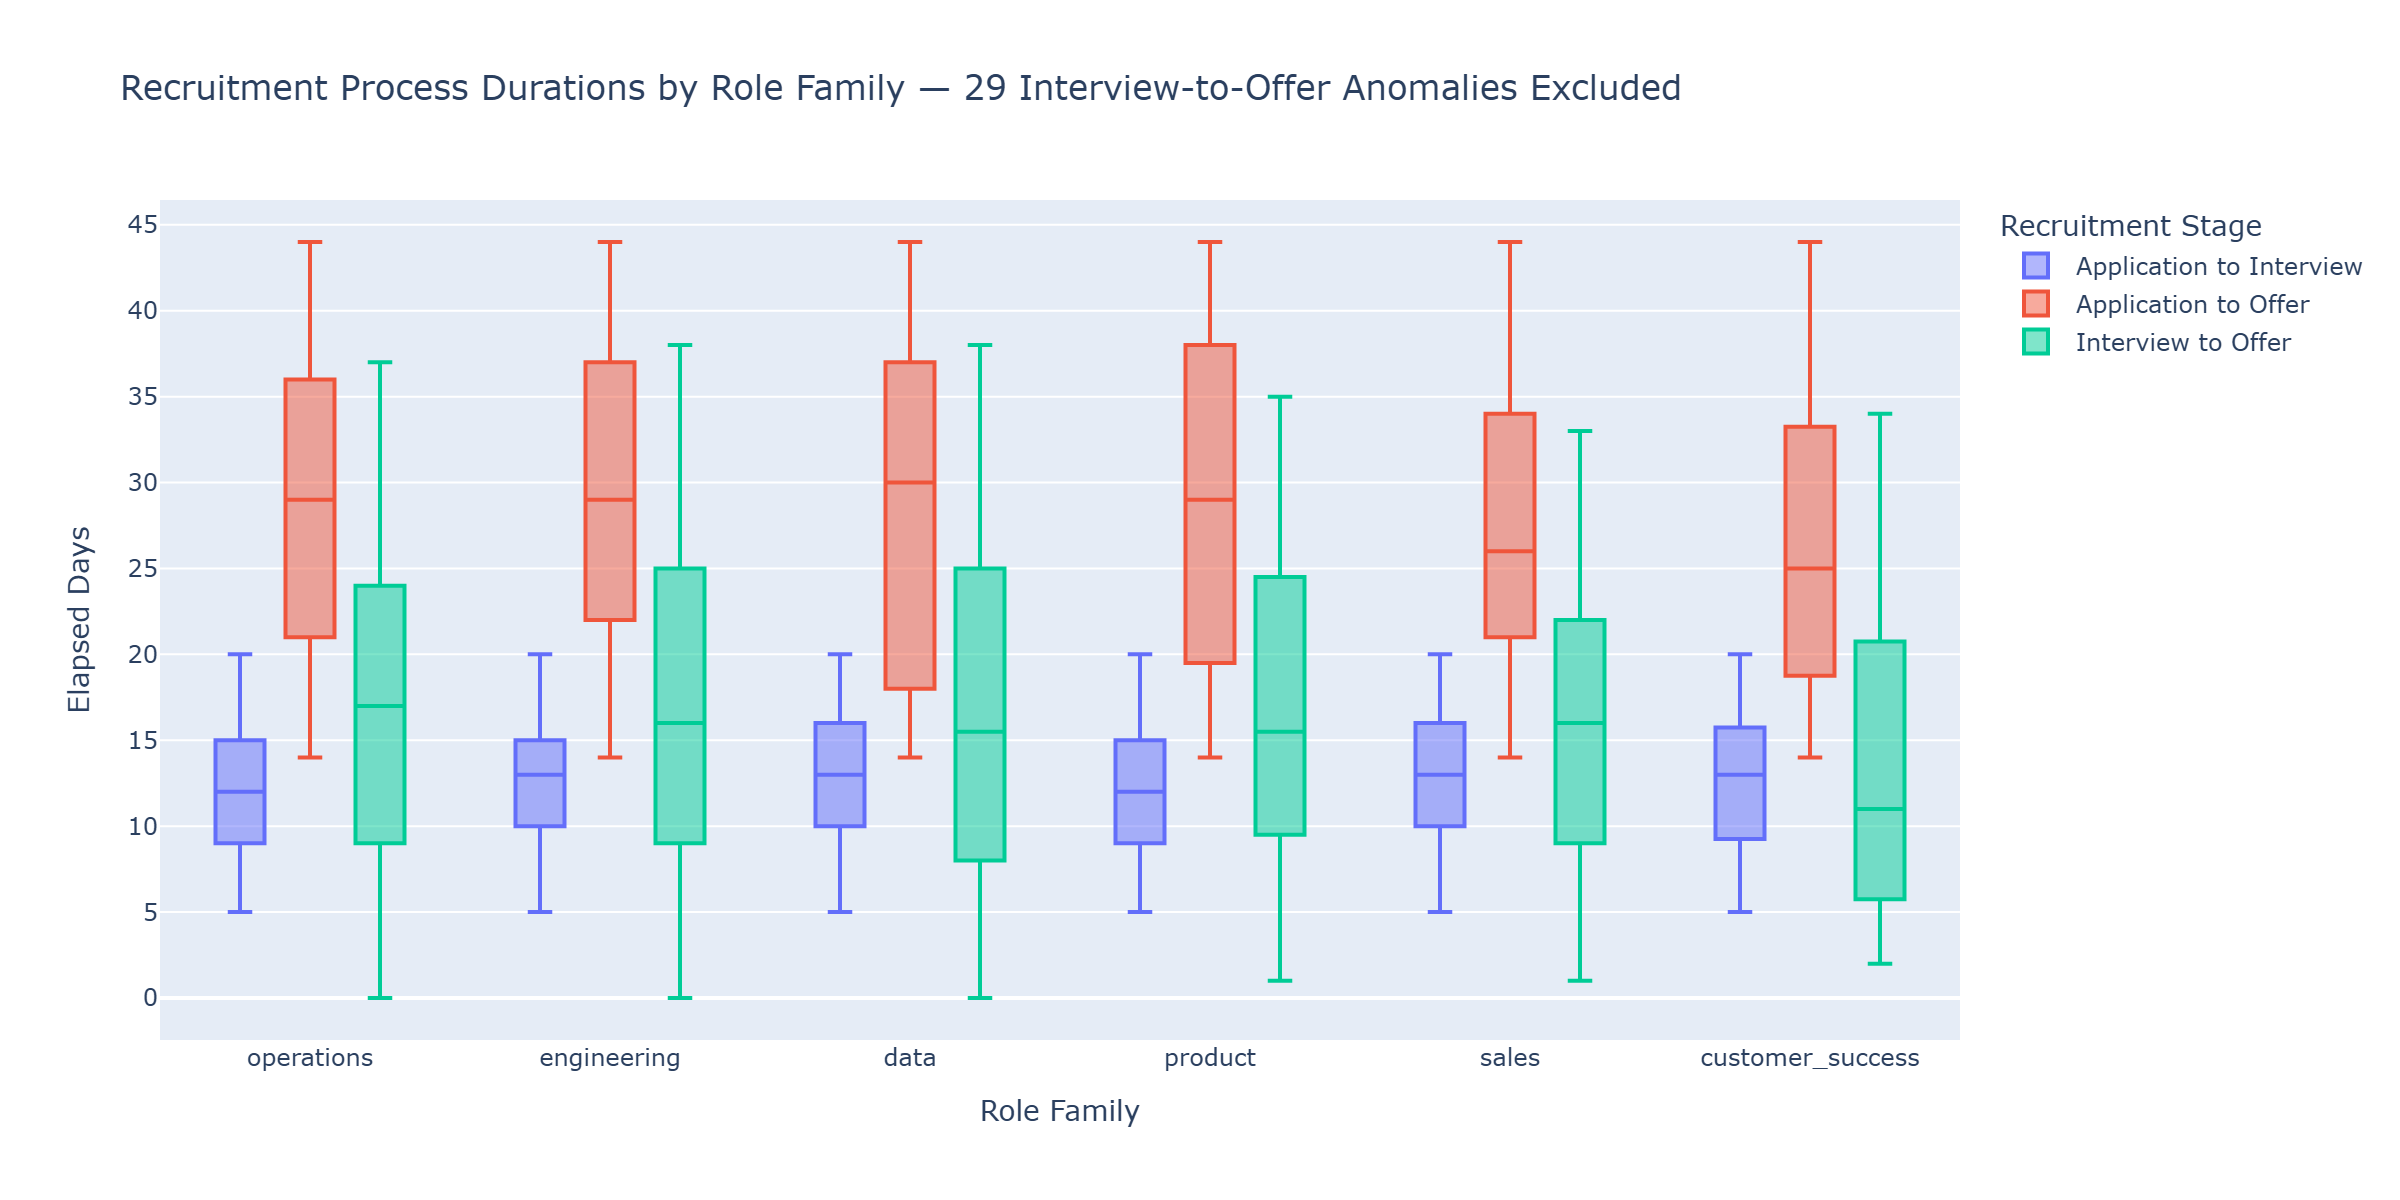

In [127]:
# Create a grouped box plot comparing recruitment durations by role family
fig = px.box(
    duration_by_role,
    x="role_family",
    y="Days",
    color="Stage",
    points=False,
    title="Recruitment Process Durations by Role Family — 29 Interview-to-Offer Anomalies Excluded"
)

# Display the three recruitment stages side by side
fig.update_layout(
    boxmode="group",
    xaxis_title="Role Family",
    yaxis_title="Elapsed Days",
    legend_title="Recruitment Stage",
    height=600
)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

### Step 14 — Verify the Role-Family Box Plot Using Median Durations

In [128]:
# Calculate median recruitment durations by role family and stage
role_duration_medians = duration_by_role.pivot_table(
    index="role_family",
    columns="Stage",
    values="Days",
    aggfunc="median"
)

# Display median durations rounded to two decimal places
display(role_duration_medians.round(2))

Stage,Application to Interview,Application to Offer,Interview to Offer
role_family,,,
customer_success,13.00,25.00,11.00
data,13.00,30.00,15.50
engineering,13.00,29.00,16.00
operations,12.00,29.00,17.00
product,12.00,29.00,15.50
sales,13.00,26.00,16.00



### Business Question #4 — Recruitment Process Efficiency

**Business Question:** How long does it take from application to first scheduled interview and to offer, and where might recruitment delays occur?

#### Key Findings

**1. Application to First Scheduled Interview**

- Of the 15,000 applications, **3,570 had interview records**.
- The average time from application to first scheduled interview was **12.42 days**, with a median of **12 days**.
- The middle 50% of waiting times ranged from **9 to 15 days**, with an overall range of **5 to 20 days**.
- Median waiting times were relatively consistent across role families, ranging from **12 to 13 days**.

**2. Application to Offer**

- A total of **938 applications received offers**.
- The average time from application to offer was **28.70 days**, with a median of **28 days**.
- The middle 50% of offer timelines ranged from **21 to 37 days**, with an overall range of **14 to 44 days**.
- **Data** recorded the longest median application-to-offer duration (**30 days**), followed by Engineering, Operations, and Product (**29 days each**).
- **Customer Success** had the shortest median duration (**25 days**).
- Both the detailed histogram and the grouped weekly-interval chart were retained to illustrate the distribution at different levels of detail.

**3. First Scheduled Interview to Offer**

- All 938 offered applications had corresponding interview records.
- **29 applications** had a first scheduled interview date occurring after the offer date, producing negative durations.
- These 29 chronology exceptions were flagged and excluded **only from the interview-to-offer duration statistics**. The original records and timestamps were preserved.
- The remaining **909 chronologically consistent applications** had an average interview-to-offer duration of **16.65 days** and a median of **17 days**.
- The middle 50% of these durations ranged from **9 to 24 days**, with an overall range of **0 to 38 days**.

**4. Recruitment Efficiency by Role Family**

- Median application-to-interview durations were relatively consistent across all six role families (**12–13 days**).
- Median application-to-offer durations showed greater variation (**25–30 days**).
- **Operations** recorded the longest median interview-to-offer duration (**17 days**), followed by Engineering and Sales (**16 days each**).
- Data and Product recorded median interview-to-offer durations of **15.5 days**.
- **Customer Success** recorded the shortest median interview-to-offer duration (**11 days**).
- The grouped box plot revealed differences in recruitment-stage durations that were less apparent from the overall summary statistics.

#### Business Insights & Recommendations

- **Investigate post-interview processes:** Review additional interviews, technical assessments, hiring-manager decisions, and offer approval procedures to identify potential causes of extended recruitment timelines.
- **Examine Data recruitment timelines:** Investigate why Data positions have the longest median application-to-offer duration (30 days).
- **Review Operations recruitment:** Although Operations has a relatively short application-to-interview median (12 days), its interview-to-offer median (17 days) is the longest among the six role families.
- **Monitor recruitment-stage KPIs:** Track time to first interview, time to offer, and interview-to-offer duration separately to identify where delays may occur.
- **Establish recruitment benchmarks:** Use comparable historical recruitment data to develop realistic internal performance targets by role family and seniority level.
- **Improve ATS event tracking:** Record actual interview dates, candidate status changes, assessment completion dates, and offer approval milestones to support more accurate recruitment efficiency analysis.
- **Evaluate candidate experience:** Consider whether extended recruitment timelines are associated with candidate withdrawals, declined offers, or reduced engagement in future analyses.

#### Analytical Limitations

- **Synthetic dataset:** The recruitment records are artificially generated and should not be interpreted as actual employer performance.
- **Timestamp patterns:** Interview and offer timestamps share the exact hours, minutes, and seconds of their corresponding application timestamps, suggesting algorithmically generated event times.
- **Chronology exceptions:** The initial investigation identified 217 accepted offers with acceptance dates preceding their offer dates. Separately, Question #4 identified 29 applications where the first scheduled interview occurred after the offer date.
- **Exclusion decision:** The 29 negative interview-to-offer durations were excluded only from that specific duration calculation. All original records were retained without date corrections.
- **Different populations:** Application-to-interview statistics use 3,570 applications; application-to-offer statistics use 938; and interview-to-offer statistics use 909 chronologically consistent applications. These distributions should not be interpreted as matched candidate populations.
- **Scheduled versus actual interviews:** The `scheduled_at` field represents a scheduled interview date, not necessarily confirmation that the interview occurred.
- **Incomplete recruitment milestones:** The dataset does not provide sufficient detail about screening, technical assessments, approvals, or other intermediate activities to identify the actual causes of delays.
- **Descriptive analysis:** The observed differences between role families have not been tested for statistical significance.
- **Interpretation:** Chronologically consistent records are not necessarily realistic recruitment timelines because of the synthetic data-generation patterns.

#### Overall Business Conclusion

- The dataset shows relatively consistent timelines from application to first scheduled interview, while application-to-offer and interview-to-offer durations exhibit greater variability.
- The results suggest that **post-interview recruitment activities warrant further investigation**, particularly for Operations, Engineering, and Data positions.
- More detailed ATS event tracking and reliable historical recruitment data would be required to distinguish genuine operational bottlenecks from synthetic-data artifacts.


# Q5 — Candidate Experience and Selection Effectiveness

**Business question:** Do applicants receiving offers differ in years of experience from other applicants, and how do experience profiles vary across job seniority levels?

### Step 1 — Examine Candidate Experience

In [129]:
# Check the number of candidates and missing experience values
print("Total candidates:", len(candidates))
print("Missing experience values:", candidates["years_experience"].isna().sum())

# Examine the distribution of professional experience
experience_stats = candidates["years_experience"].describe()

# Display summary statistics
display(experience_stats.round(2))

# Preview the relevant candidate information
display(candidates[["candidate_id", "years_experience"]].head())

Total candidates: 9000
Missing experience values: 0


count   9000.00
mean       8.55
std        5.22
min        0.00
25%        4.00
50%        9.00
75%       13.00
max       17.00
Name: years_experience, dtype: float64

,candidate_id,years_experience
0,1,2
1,2,5
2,3,17
3,4,4
4,5,9


### Step 2 — Connect Candidate Experience to Applications

- `applications` provides `application_id`, `candidate_id` and `job_id`.
- `candidates` provides `candidate_id` and `years_experience`.
- The unit of analysis is an **application**. A candidate can contribute more than one application.

In [130]:
# Select candidate IDs and years of experience
candidate_experience = candidates[
    ["candidate_id", "years_experience"]
]

# Merge applications with candidate experience
experience_analysis = applications.merge(
    candidate_experience,
    on="candidate_id",
    how="left"
)

# Verify the merge
print("Total applications:", len(experience_analysis))
print("Missing experience values:", experience_analysis["years_experience"].isna().sum())
print("Unique candidates:", experience_analysis["candidate_id"].nunique())

# Preview the relevant columns
display(
    experience_analysis[
        ["application_id", "candidate_id", "years_experience"]
    ].head()
)

Total applications: 15000
Missing experience values: 0
Unique candidates: 7324


,application_id,candidate_id,years_experience
0,1,6949,10
1,2,1387,17
2,3,7960,4
3,4,7384,11
4,5,6407,11


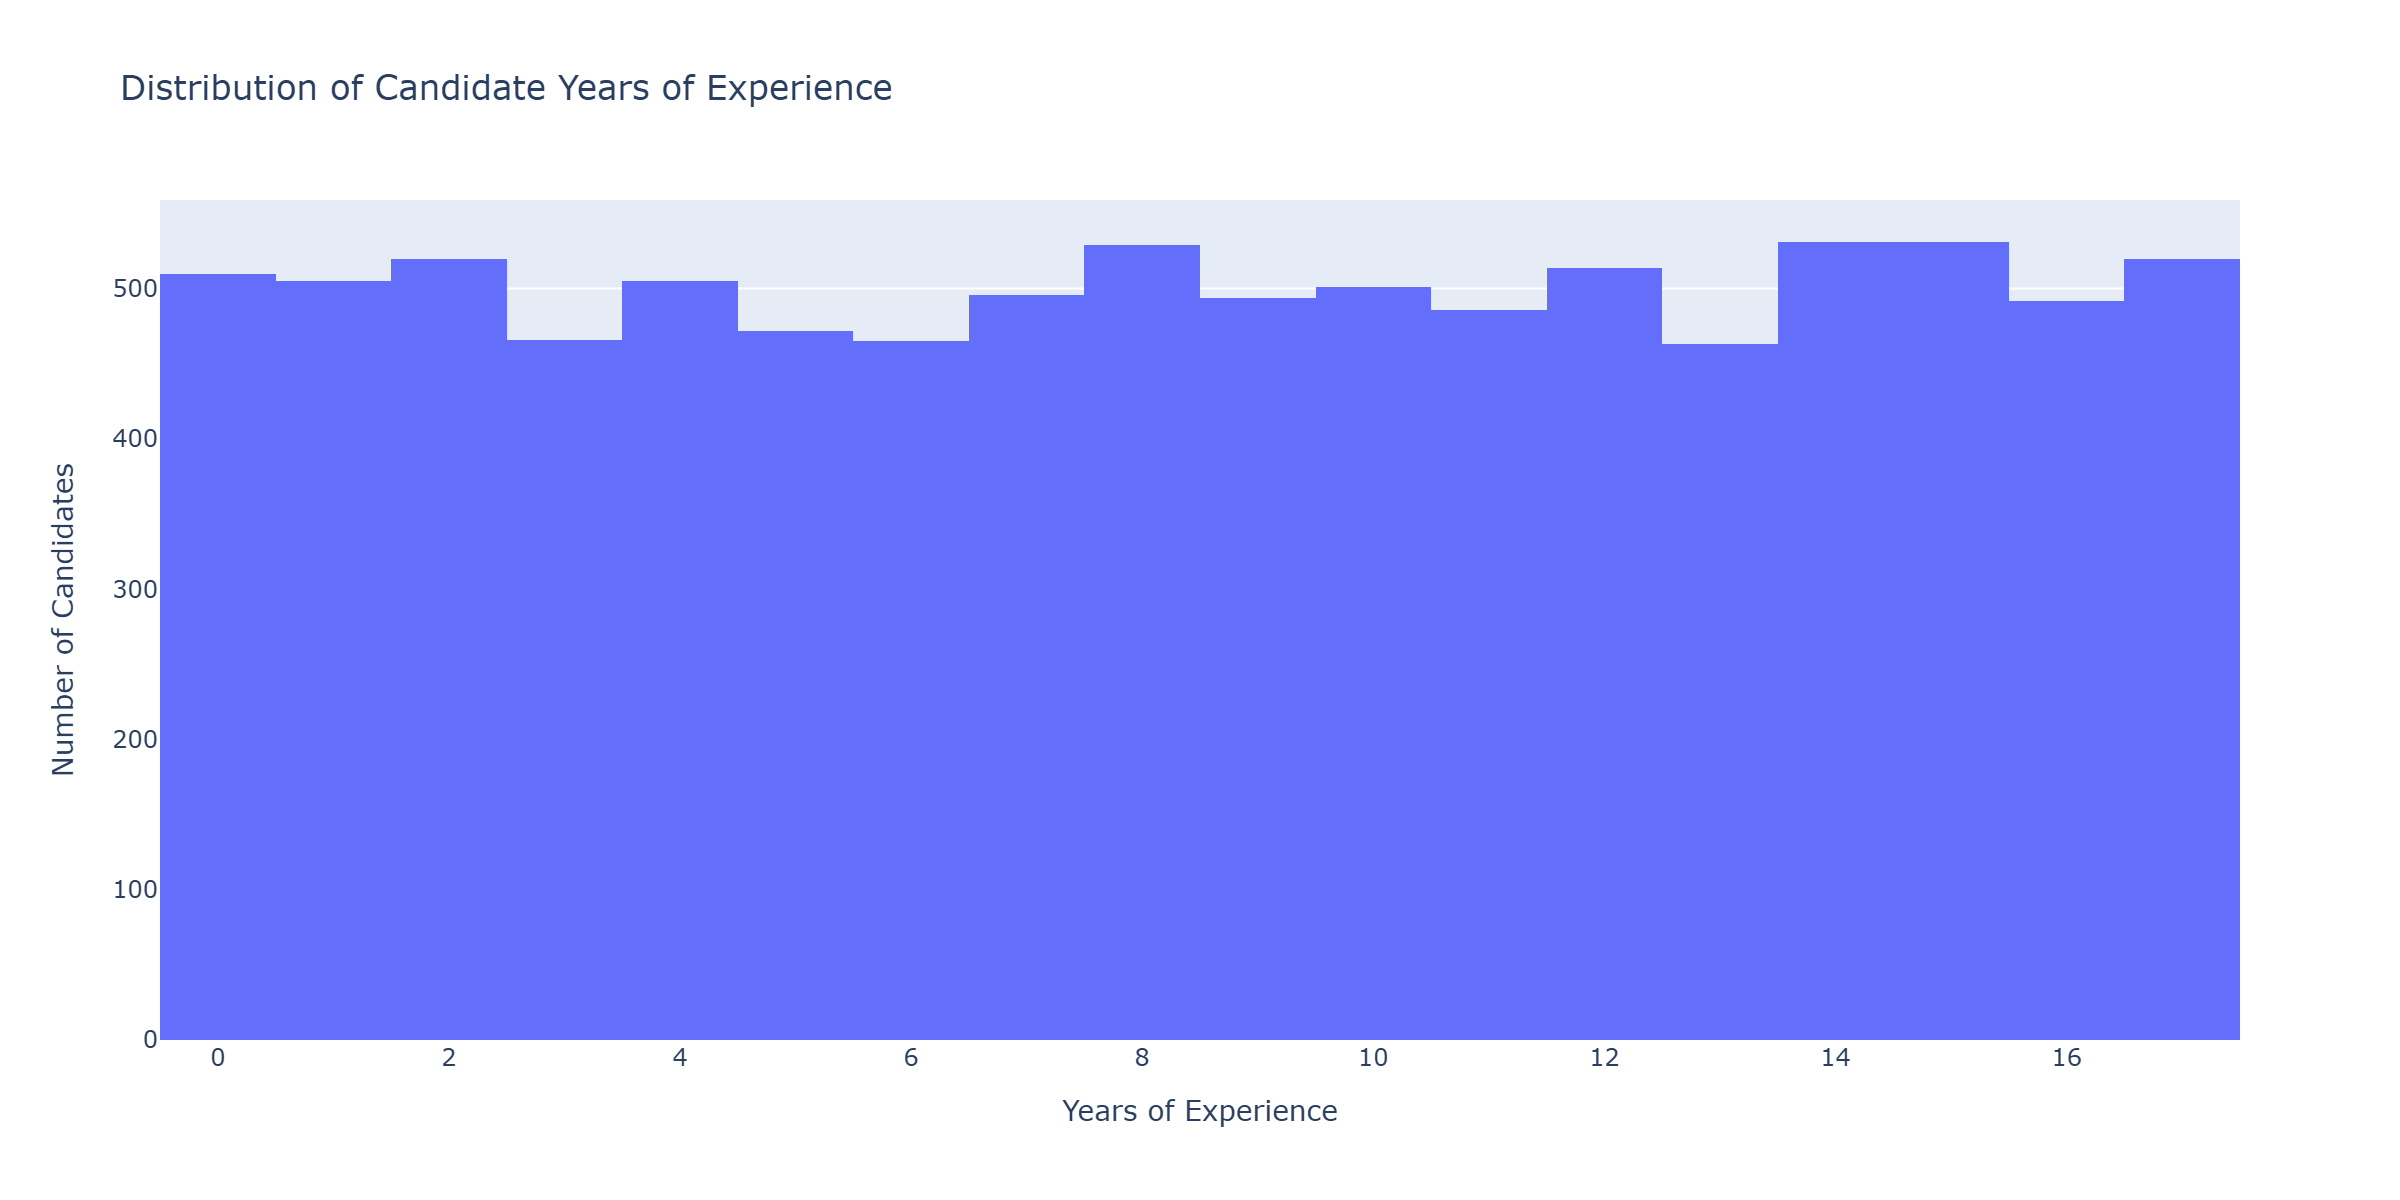

In [131]:
# Create a histogram of candidate years of experience
fig = px.histogram(
    candidates,
    x="years_experience",
    nbins=18,
    title="Distribution of Candidate Years of Experience"
)

# Improve chart layout
fig.update_layout(
    xaxis_title="Years of Experience",
    yaxis_title="Number of Candidates"
)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)


#### Candidate Experience Distribution — Initial Observations

- Candidate experience ranges from 0 to 17 years, with a mean of 8.55 years and a median of 9 years.
- The histogram shows an approximately uniform distribution, with relatively similar numbers of candidates at each experience level.
- There is no pronounced concentration of candidates at any particular experience level.
- The relatively even distribution may reflect the synthetic dataset's generation process rather than a realistic labour-market experience profile.
- This visualization provides a baseline understanding of candidate experience before examining offer outcomes and job seniority.


### Step 3 — Identify Applications Receiving Offers

In [132]:
# Select application IDs from the offers table
offer_ids = offers[["application_id"]].copy()

# Merge offer information with candidate experience
experience_analysis = experience_analysis.merge(
    offer_ids,
    on="application_id",
    how="left",
    indicator=True
)

# Identify applications that received an offer
experience_analysis["Received_Offer"] = (
    experience_analysis["_merge"] == "both"
)

# Remove the temporary merge indicator
experience_analysis = experience_analysis.drop(columns="_merge")

# Verify the results
print("Total applications:", len(experience_analysis))
print("Applications receiving offers:", experience_analysis["Received_Offer"].sum())
print("Applications without recorded offers:", (~experience_analysis["Received_Offer"]).sum())

# Preview the results
display(
    experience_analysis[
        ["application_id", "years_experience", "Received_Offer"]
    ].head()
)

Total applications: 15000
Applications receiving offers: 938
Applications without recorded offers: 14062


,application_id,years_experience,Received_Offer
0,1,10,False
1,2,17,False
2,3,4,False
3,4,11,False
4,5,11,False


### Step 4 — Compare Candidate Experience by Offer Outcome

In [133]:
# Calculate experience statistics by offer outcome
experience_summary = experience_analysis.groupby("Received_Offer")[
    "years_experience"
].describe().T

# Display the results rounded to two decimal places
display(experience_summary.round(2))

Received_Offer,False,True
count,14062.00,938.00
mean,8.54,8.38
std,5.21,5.30
min,0.00,0.00
25%,4.00,4.00
50%,9.00,8.00
75%,13.00,13.00
max,17.00,17.00


### Step 5 — Visualize Experience by Offer Outcome

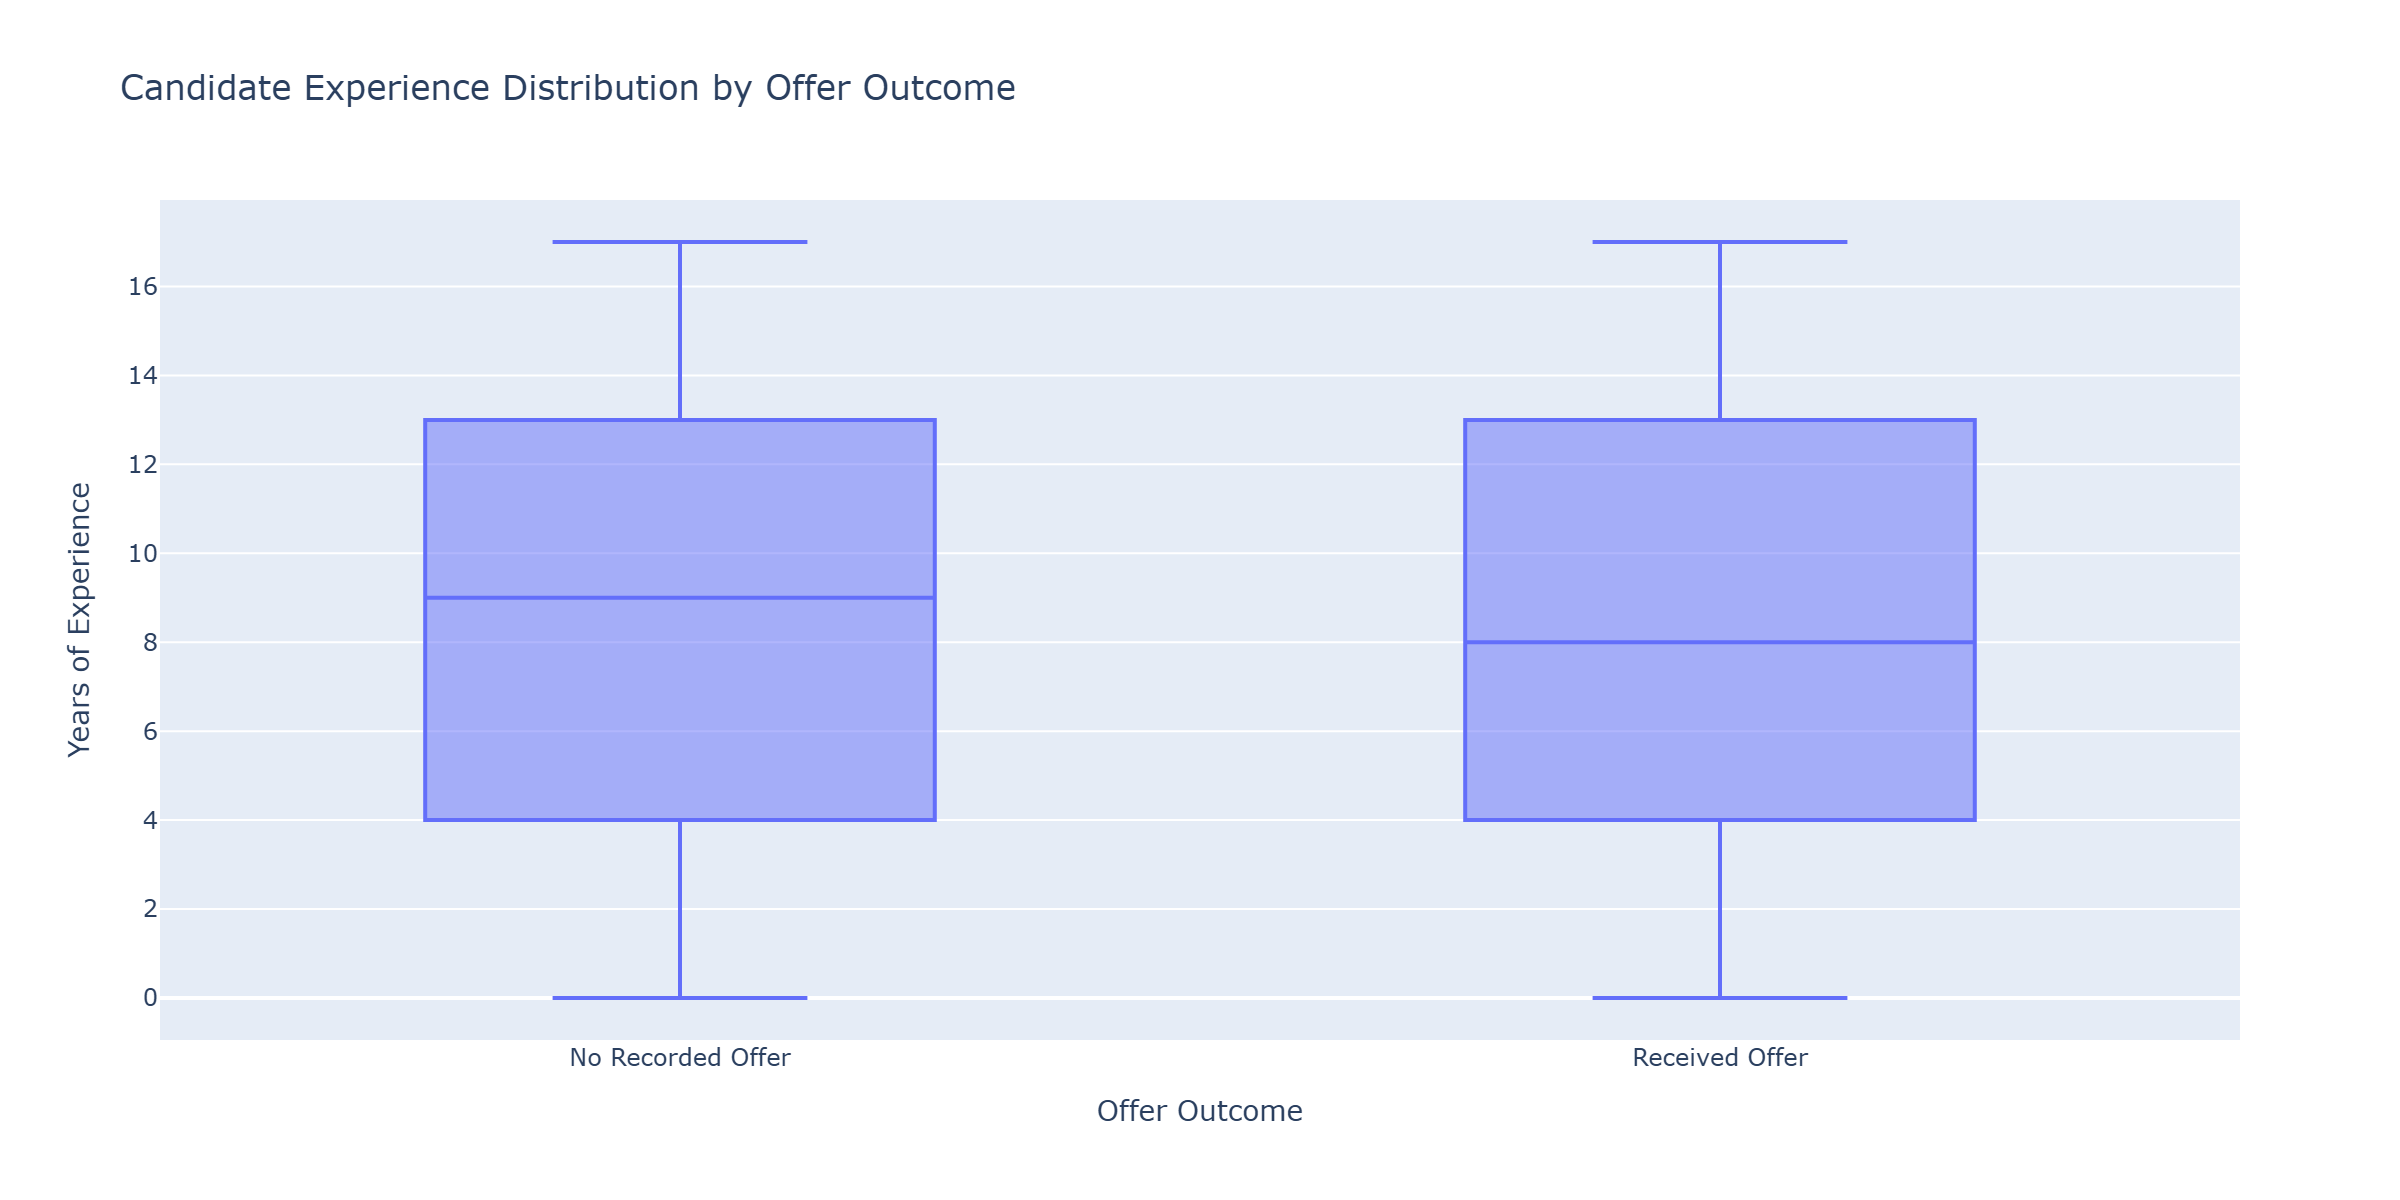

In [134]:
# Create readable labels for offer outcomes
experience_analysis["Offer_Outcome"] = experience_analysis["Received_Offer"].map({
    True: "Received Offer",
    False: "No Recorded Offer"
})

# Create a comparative box plot
fig = px.box(
    experience_analysis,
    x="Offer_Outcome",
    y="years_experience",
    points=False,
    title="Candidate Experience Distribution by Offer Outcome"
)

# Improve chart labels and layout
fig.update_layout(
    xaxis_title="Offer Outcome",
    yaxis_title="Years of Experience",
    showlegend=False
)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

### Step 6 — Introduce Job Seniority Levels

In [135]:
# Select job IDs and their seniority levels
job_levels = jobs[["job_id", "level"]]

# Merge seniority levels with our experience analysis
experience_analysis = experience_analysis.merge(
    job_levels,
    on="job_id",
    how="left"
)

# Verify the results
print("Total applications:", len(experience_analysis))
print("Missing seniority levels:", experience_analysis["level"].isna().sum())

# Preview the relevant columns
display(
    experience_analysis[
        ["application_id", "years_experience", "Offer_Outcome", "level"]
    ].head()
)

Total applications: 15000
Missing seniority levels: 0


,application_id,years_experience,Offer_Outcome,level
0,1,10,No Recorded Offer,mid
1,2,17,No Recorded Offer,mid
2,3,4,No Recorded Offer,lead
3,4,11,No Recorded Offer,junior
4,5,11,No Recorded Offer,lead


### Step 7 — Experience Distribution by Job Seniority and Offer Outcome

In [136]:
# Group applications by job seniority and offer outcome
experience_by_level = experience_analysis.groupby(
    ["level", "Offer_Outcome"]
)["years_experience"].describe().T

# Display the experience statistics
display(experience_by_level.round(2))

level                    junior                             lead  \
Offer_Outcome No Recorded Offer Received Offer No Recorded Offer   
count                   1742.00         114.00           1844.00   
mean                       8.57           7.63              8.54   
std                        5.24           5.47              5.26   
min                        0.00           0.00              0.00   
25%                        4.00           2.25              4.00   
50%                        9.00           8.00              8.00   
75%                       13.00          13.00             13.00   
max                       17.00          17.00             17.00   

level                                      mid                 \
Offer_Outcome Received Offer No Recorded Offer Received Offer   
count                 131.00           5218.00         369.00   
mean                    8.20              8.52           8.72   
std                     5.33              5.23           5.31   
min                     0.00              0.00           0.00   
25%                     3.50              4.00           4.00   
50%                     7.00              8.00           9.00   
75%                    13.00             13.00          13.00   
max                    17.00             17.00          17.00   

level                    senior                 
Offer_Outcome No Recorded Offer Received Offer  
count                   5258.00         324.00  
mean                       8.55           8.31  
std                        5.17           5.21  
min                        0.00           0.00  
25%                        4.00           4.00  
50%                        9.00           8.00  
75%                       13.00          13.00  
max                       17.00          17.00

### Step 8 — Grouped Box Plot by Seniority Level

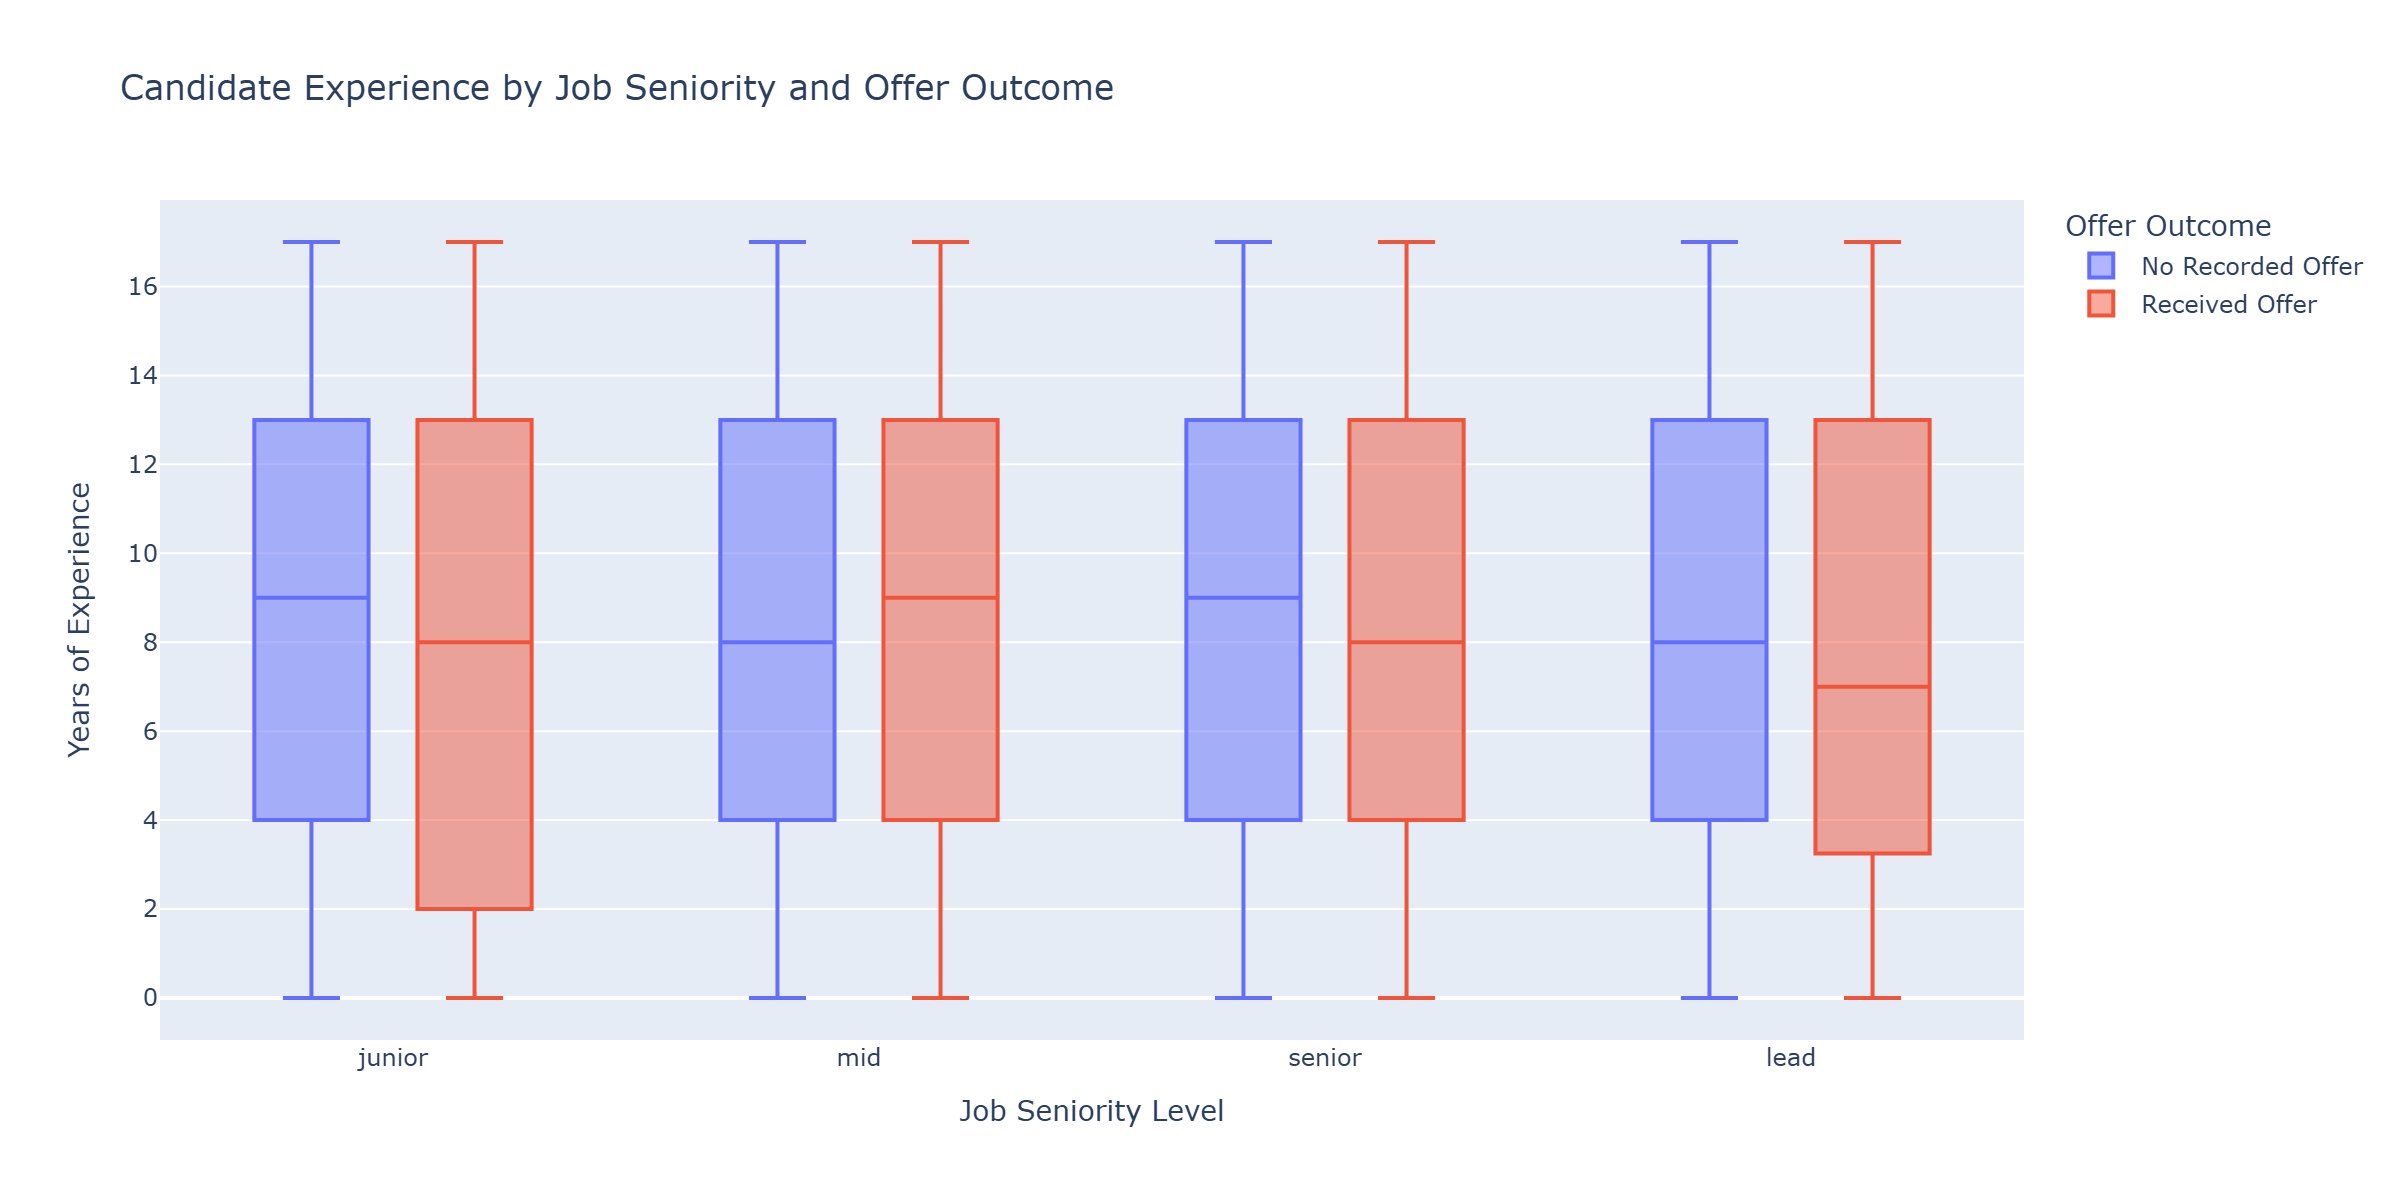

In [137]:
# Define the logical order of job seniority levels
level_order = ["junior", "mid", "senior", "lead"]

# Create grouped box plots comparing experience and offer outcomes
fig = px.box(
    experience_analysis,
    x="level",
    y="years_experience",
    color="Offer_Outcome",
    category_orders={"level": level_order},
    points=False,
    title="Candidate Experience by Job Seniority and Offer Outcome"
)

# Display the two offer-outcome groups side by side
fig.update_layout(
    boxmode="group",
    xaxis_title="Job Seniority Level",
    yaxis_title="Years of Experience",
    legend_title="Offer Outcome",
    height=550
)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

The synthetic dataset does not demonstrate a consistent relationship between job seniority and the years of experience of candidates receiving offers.

### Step 9 — Experience of Offer Recipients by Role Family and Seniority

In [138]:
# Calculate median experience for offered applications by job category
# Select job IDs and role families
job_families = jobs[["job_id", "role_family"]]

# Add role families to our experience analysis
experience_analysis = experience_analysis.merge(
    job_families,
    on="job_id",
    how="left"
)

# Select applications that received offers
offered_experience = experience_analysis[
    experience_analysis["Received_Offer"] == True
]

# Calculate median experience by role family and seniority
experience_role_summary = offered_experience.groupby(
    ["role_family", "level"]
)["years_experience"].median().reset_index()

# Rename the median experience column
experience_role_summary = experience_role_summary.rename(
    columns={"years_experience": "Median_Experience"}
)

# Display the results
display(experience_role_summary)

,role_family,level,Median_Experience
0,customer_success,junior,6.50
1,customer_success,lead,4.00
2,customer_success,mid,13.50
3,customer_success,senior,10.00
4,data,junior,6.00
5,data,lead,7.50
6,data,mid,10.00
7,data,senior,11.00
8,engineering,junior,4.00
9,engineering,lead,7.00


In [139]:
# Select applications that received offers for Sales positions
sales_offers = offered_experience[
    offered_experience["role_family"] == "sales"
]

# Calculate offer counts and median experience by seniority
sales_summary = sales_offers.groupby("level").agg(
    Offers=("application_id", "count"),
    Median_Experience=("years_experience", "median")
)

# Arrange the seniority levels in a logical order
sales_summary = sales_summary.reindex(
    ["junior", "mid", "senior", "lead"]
)

# Display the offer counts as whole numbers and experience to one decimal
display(sales_summary.style.format({"Offers": "{:.0f}", "Median_Experience": "{:.1f}"}))

,Offers,Median_Experience
level,,
junior,1,10.0
mid,16,9.5
senior,12,7.5
lead,5,7.0


#### Step 9C — Sales: Offer Counts and Median Experience

The Junior Sales median comes from **one offer**, so it must not be treated as a representative experience requirement. The table provides offer counts alongside medians for context. The small sample sizes for Sales also warrant caution.

### Step 10 — Experience Heatmap and Readable Summary Table

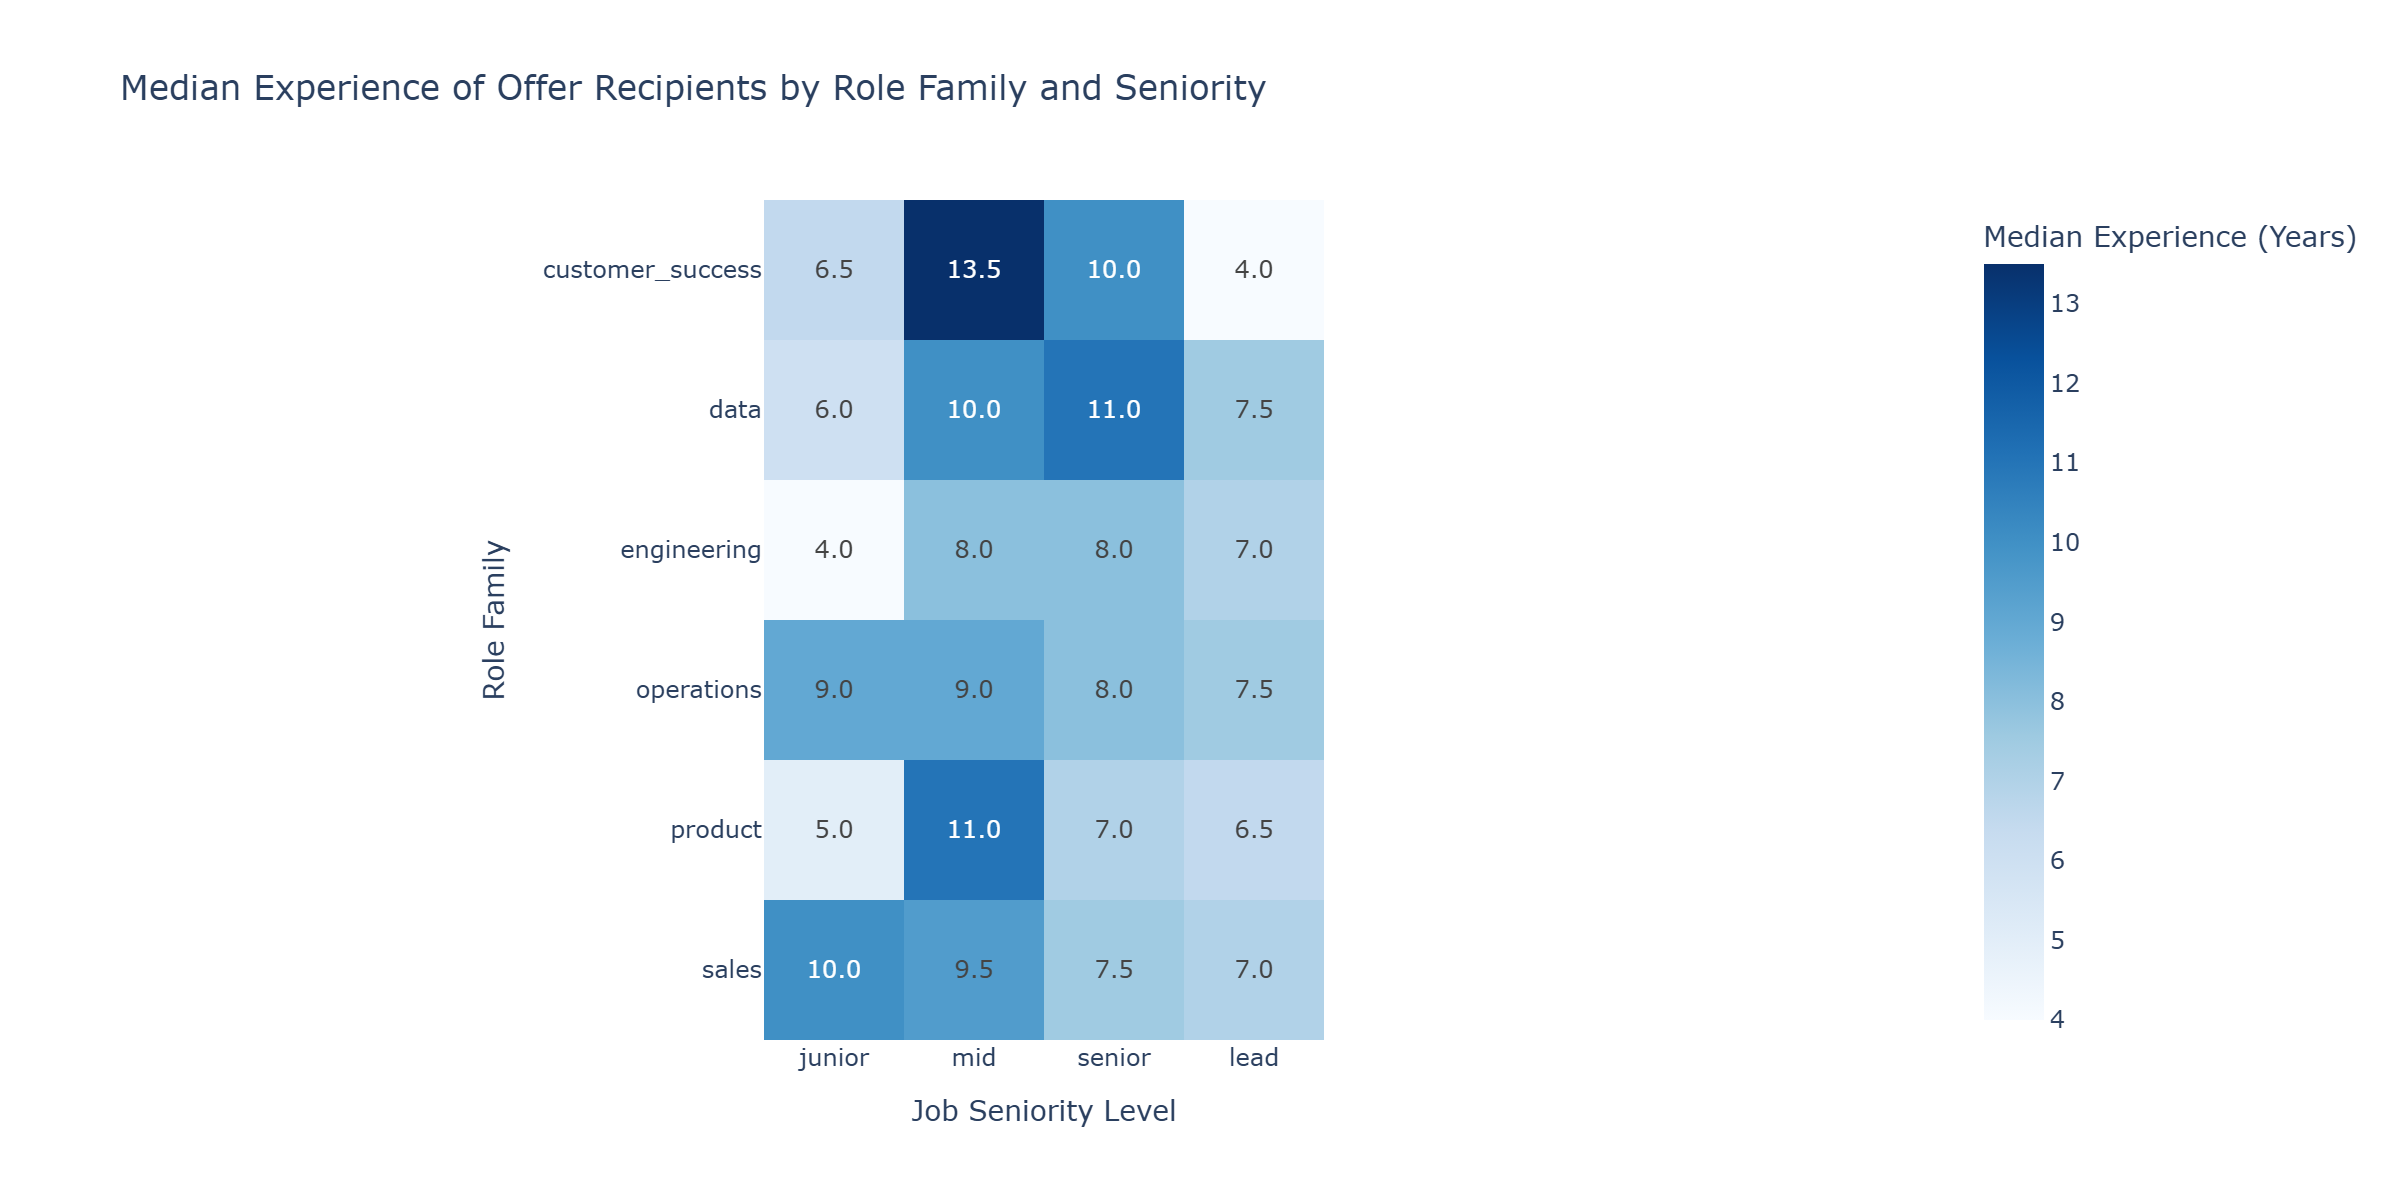

In [140]:
# Reshape the median experience values for the heatmap
experience_heatmap = experience_role_summary.pivot(
    index="role_family",
    columns="level",
    values="Median_Experience"
)

# Arrange seniority levels in a logical order
experience_heatmap = experience_heatmap[
    ["junior", "mid", "senior", "lead"]
]

# Create a heatmap showing median years of experience
fig = px.imshow(
    experience_heatmap,
    text_auto=".1f",
    color_continuous_scale="Blues",
    labels={
        "x": "Job Seniority Level",
        "y": "Role Family",
        "color": "Median Experience (Years)"
    },
    title="Median Experience of Offer Recipients by Role Family and Seniority"
)

# Improve chart layout
fig.update_layout(
    height=550,
    xaxis_title="Job Seniority Level",
    yaxis_title="Role Family"
)

# Display the heatmap
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

In [141]:
# Rename the columns for a professional presentation
experience_table = experience_heatmap.copy()

experience_table.columns = ["Junior", "Mid", "Senior", "Lead"]

# Rename the index
experience_table.index.name = "Role Family"

# Make role family names more readable
experience_table.index = experience_table.index.str.replace("_", " ").str.title()

# Display all values with exactly one decimal place
display(experience_table.style.format("{:.1f}"))

,Junior,Mid,Senior,Lead
Role Family,,,,
Customer Success,6.5,13.5,10.0,4.0
Data,6.0,10.0,11.0,7.5
Engineering,4.0,8.0,8.0,7.0
Operations,9.0,9.0,8.0,7.5
Product,5.0,11.0,7.0,6.5
Sales,10.0,9.5,7.5,7.0



### Business Question #5 — Candidate Experience and Selection Effectiveness

**Business Question:** Do applicants receiving offers differ in years of experience from other applicants, and how do experience profiles vary across job seniority levels?

#### Key Findings

**1. Overall Candidate Experience**

- The dataset contains **9,000 candidate records**, with experience ranging from 0 to 17 years.
- Average candidate experience is **8.55 years**, with a median of **9 years**.
- The experience histogram shows an approximately uniform distribution across the 0–17-year range.
- Of the 9,000 candidates, **7,324 unique candidates** submitted the 15,000 recorded applications.

**2. Experience by Offer Outcome**

- Applications receiving offers (**938**) had a mean experience of **8.38 years**, compared with **8.54 years** for applications without recorded offers (**14,062**).
- Median experience was **8 years** for applications receiving offers and **9 years** for those without recorded offers.
- Both groups had the same interquartile range (**4–13 years**) and overall experience range (**0–17 years**).
- The comparative box plot showed very similar experience distributions, suggesting no substantial descriptive difference between the two groups.

**3. Experience by Job Seniority**

- Median experience among offer recipients was **8 years for Junior**, **9 years for Mid**, **8 years for Senior**, and **7 years for Lead** positions.
- Experience among offer recipients did not consistently increase with job seniority.
- Junior offer recipients had a higher median experience than Lead offer recipients, contrary to what might generally be expected from job seniority classifications.
- The grouped box plots showed substantial overlap in experience distributions across seniority levels and offer outcomes.

**4. Experience by Role Family and Seniority**

- **Engineering:** Median experience among offer recipients ranged from **4 years (Junior)** to **8 years (Mid and Senior)**, with Lead positions at **7 years**.
- **Data:** Median experience increased from **6 years (Junior)** to **11 years (Senior)**, before declining to **7.5 years (Lead)**.
- **Operations:** Median experience decreased from **9 years (Junior and Mid)** to **7.5 years (Lead)**.
- **Customer Success:** Mid-level positions recorded a median of **13.5 years**, compared with **4 years for Lead** positions.
- **Sales:** Junior offer recipients recorded a median of **10 years**, compared with **7 years for Lead** positions.
- The 24-combination heatmap highlighted considerable variation in median experience across role families and seniority levels.
- Some extreme results were based on very small samples, including **Junior Sales (1 offer)** and **Lead Customer Success (5 offers)**.

#### Business Insights & Recommendations

- **Evaluate experience alignment:** Review whether candidate experience profiles are consistent with documented job requirements, particularly for Senior and Lead positions.
- **Improve job requirement tracking:** Record minimum relevant experience, technical qualifications, and required competencies for each job posting.
- **Distinguish total from relevant experience:** Capture years of experience within the candidate's specific discipline, rather than relying solely on total professional experience.
- **Review selection criteria:** Investigate whether screening and offer decisions appropriately consider technical skills, transferable experience, leadership capabilities, and job-specific requirements.
- **Monitor experience profiles by job category:** Compare experience distributions within seniority levels and role families instead of relying exclusively on organization-wide averages.
- **Consider sample sizes:** Evaluate offer counts alongside median experience to avoid drawing misleading conclusions from small recruitment groups.
- **Improve ATS data quality:** Standardize candidate experience fields and job requirement classifications to support more meaningful selection analytics.

#### Analytical Limitations

- **Synthetic dataset:** Candidate experience and selection outcomes are artificially generated and may not reflect real-world recruitment practices.
- **Experience distribution:** Years of experience are distributed approximately uniformly between 0 and 17 years, potentially reflecting the synthetic data-generation process.
- **Missing job requirements:** The dataset does not contain explicit minimum experience requirements for individual positions.
- **Total versus relevant experience:** The `years_experience` column does not identify experience relevant to the specific position.
- **Selection versus quality of hire:** Receiving an offer is a recruitment selection outcome, not evidence of post-hire performance, retention, or actual quality of hire.
- **Different application outcomes:** Applications without recorded offers may still be progressing through recruitment and should not automatically be classified as rejected.
- **Repeated candidates:** The 15,000 applications originate from 7,324 unique candidates, meaning some candidates contribute multiple application records.
- **Small sample sizes:** Some role-family and seniority combinations have very few offers, making their medians less representative.
- **Descriptive analysis:** Observed differences have not been tested for statistical significance. Further investigation will be conducted in `Statistics.ipynb`.

#### Overall Business Conclusion

- Applications receiving offers and those without recorded offers have broadly similar distributions of total professional experience.
- Experience among offer recipients does not consistently increase with job seniority, and several role-family comparisons show unexpected patterns.
- These results highlight the limitations of using total years of experience as a standalone measure of candidate suitability.
- More detailed job requirements, relevant experience measures, and competency assessments would be needed to evaluate how effectively recruitment teams select candidates for specific positions.


# Q6 — Salary Competitiveness and Offer Acceptance

**Business question:** Is offer acceptance associated with an offer's position inside the advertised salary range?

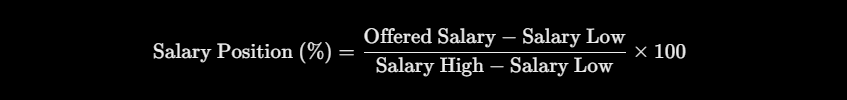

### Step 1 — Examine Salary Data

In [142]:
# Examine advertised salary ranges
display(jobs[["salary_low", "salary_high"]].describe().round(2))

# Examine actual offered salaries
display(offers["base_salary"].describe().round(2))

# Check for missing salary values
print("Missing salary_low:", jobs["salary_low"].isna().sum())
print("Missing salary_high:", jobs["salary_high"].isna().sum())
print("Missing base_salary:", offers["base_salary"].isna().sum())

# Check for invalid advertised salary ranges
invalid_ranges = jobs[jobs["salary_high"] <= jobs["salary_low"]]

print("Invalid salary ranges:", len(invalid_ranges))

,salary_low,salary_high
count,2000.00,2000.00
mean,117845.50,143147.50
std,31834.48,38576.36
min,58000.00,70000.00
25%,91000.00,112000.00
50%,114000.00,138000.00
75%,135250.00,166000.00
max,206000.00,253000.00


count      938.00
mean    129879.69
std      35859.03
min      61321.00
25%     101857.00
50%     126487.50
75%     150348.50
max     240017.00
Name: base_salary, dtype: float64

Missing salary_low: 0
Missing salary_high: 0
Missing base_salary: 0
Invalid salary ranges: 0


### Step 2 — Connect Offers to Advertised Salary Ranges

In [143]:
# Select application IDs and their corresponding job IDs
application_jobs = applications[["application_id", "job_id"]]

# Merge offers with their corresponding job IDs
salary_analysis = offers.merge(
    application_jobs,
    on="application_id",
    how="left"
)

# Select advertised salary ranges from the jobs table
job_salaries = jobs[["job_id", "salary_low", "salary_high"]]

# Add advertised salary ranges to each offer
salary_analysis = salary_analysis.merge(
    job_salaries,
    on="job_id",
    how="left"
)

# Verify the merge
print("Total offers:", len(salary_analysis))
print("Missing job IDs:", salary_analysis["job_id"].isna().sum())
print("Missing salary ranges:", salary_analysis["salary_low"].isna().sum())

# Preview the relevant columns
display(
    salary_analysis[
        ["application_id", "base_salary", "salary_low", "salary_high", "accepted"]
    ].head()
)

Total offers: 938
Missing job IDs: 0
Missing salary ranges: 0


,application_id,base_salary,salary_low,salary_high,accepted
0,8,130303,126000,159000,True
1,13,207647,203000,221000,True
2,25,168168,142000,185000,False
3,29,105156,91000,112000,True
4,30,137936,124000,146000,True


### Step 3 — Calculate Relative Salary Position (%)

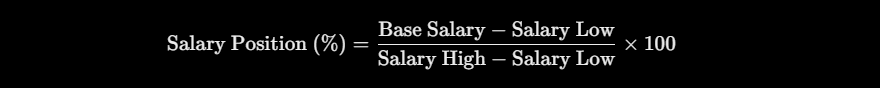

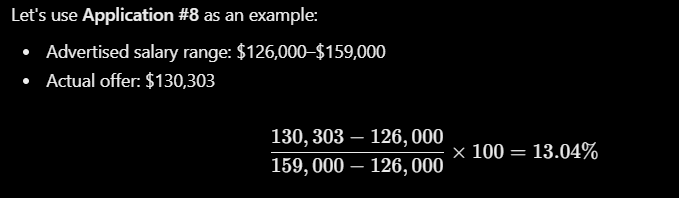

In [144]:
# Calculate the width of each advertised salary range
salary_analysis["Salary_Range"] = (
    salary_analysis["salary_high"] - salary_analysis["salary_low"]
)

# Calculate the difference between offered salary and advertised minimum
salary_analysis["Salary_Above_Minimum"] = (
    salary_analysis["base_salary"] - salary_analysis["salary_low"]
)

# Calculate the relative salary position as a percentage
salary_analysis["Salary_Position"] = (
    salary_analysis["Salary_Above_Minimum"] / salary_analysis["Salary_Range"] * 100
)

# Display the first five offers
display(
    salary_analysis[
        ["application_id", "salary_low", "salary_high",
         "base_salary", "Salary_Position", "accepted"]
    ].head().round(2)
)

,application_id,salary_low,salary_high,base_salary,Salary_Position,accepted
0,8,126000,159000,130303,13.04,True
1,13,203000,221000,207647,25.82,True
2,25,142000,185000,168168,60.86,False
3,29,91000,112000,105156,67.41,True
4,30,124000,146000,137936,63.35,True


### Step 4 — Validate Salary Positions

In [145]:
# Calculate summary statistics for relative salary positions
salary_position_stats = salary_analysis["Salary_Position"].describe()

# Display the statistics
display(salary_position_stats.round(2))

# Count offers below the advertised minimum
below_minimum = (salary_analysis["Salary_Position"] < 0).sum()

# Count offers above the advertised maximum
above_maximum = (salary_analysis["Salary_Position"] > 100).sum()

# Count offers within the advertised salary range
within_range = salary_analysis["Salary_Position"].between(0, 100).sum()

# Display the validation results
print("Offers below advertised minimum:", below_minimum)
print("Offers within advertised range:", within_range)
print("Offers above advertised maximum:", above_maximum)

count   938.00
mean     50.14
std      28.90
min       0.21
25%      25.39
50%      49.42
75%      75.84
max      99.72
Name: Salary_Position, dtype: float64

Offers below advertised minimum: 0
Offers within advertised range: 938
Offers above advertised maximum: 0


### Step 5 — Group Salary Positions into Bands to find Acceptance Rate

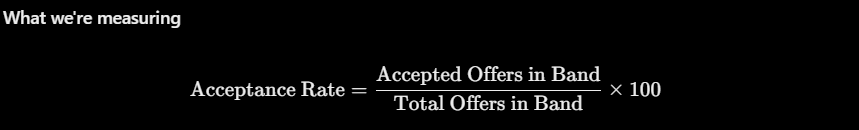

In [146]:
# Define salary-position interval boundaries
bins = [0, 25, 50, 75, 100]

# Define descriptive labels for each salary-position band
labels = ["0–25%", "25–50%", "50–75%", "75–100%"]

# Group offers into salary-position bands
salary_analysis["Salary_Band"] = pd.cut(
    salary_analysis["Salary_Position"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Count offers and accepted offers within each salary band
salary_band_summary = salary_analysis.groupby(
    "Salary_Band",
    observed=True
).agg(
    Offers=("application_id", "count"),
    Accepted_Offers=("accepted", "sum")
).reset_index()

# Calculate offer acceptance rates
salary_band_summary["Acceptance_Rate"] = (
    salary_band_summary["Accepted_Offers"]
    / salary_band_summary["Offers"] * 100
)

# Display the results
display(salary_band_summary.round(2))

,Salary_Band,Offers,Accepted_Offers,Acceptance_Rate
0,0–25%,232,166,71.55
1,25–50%,248,185,74.60
2,50–75%,216,165,76.39
3,75–100%,242,183,75.62


### Step 6 — Visualize Acceptance Rates by Salary Position

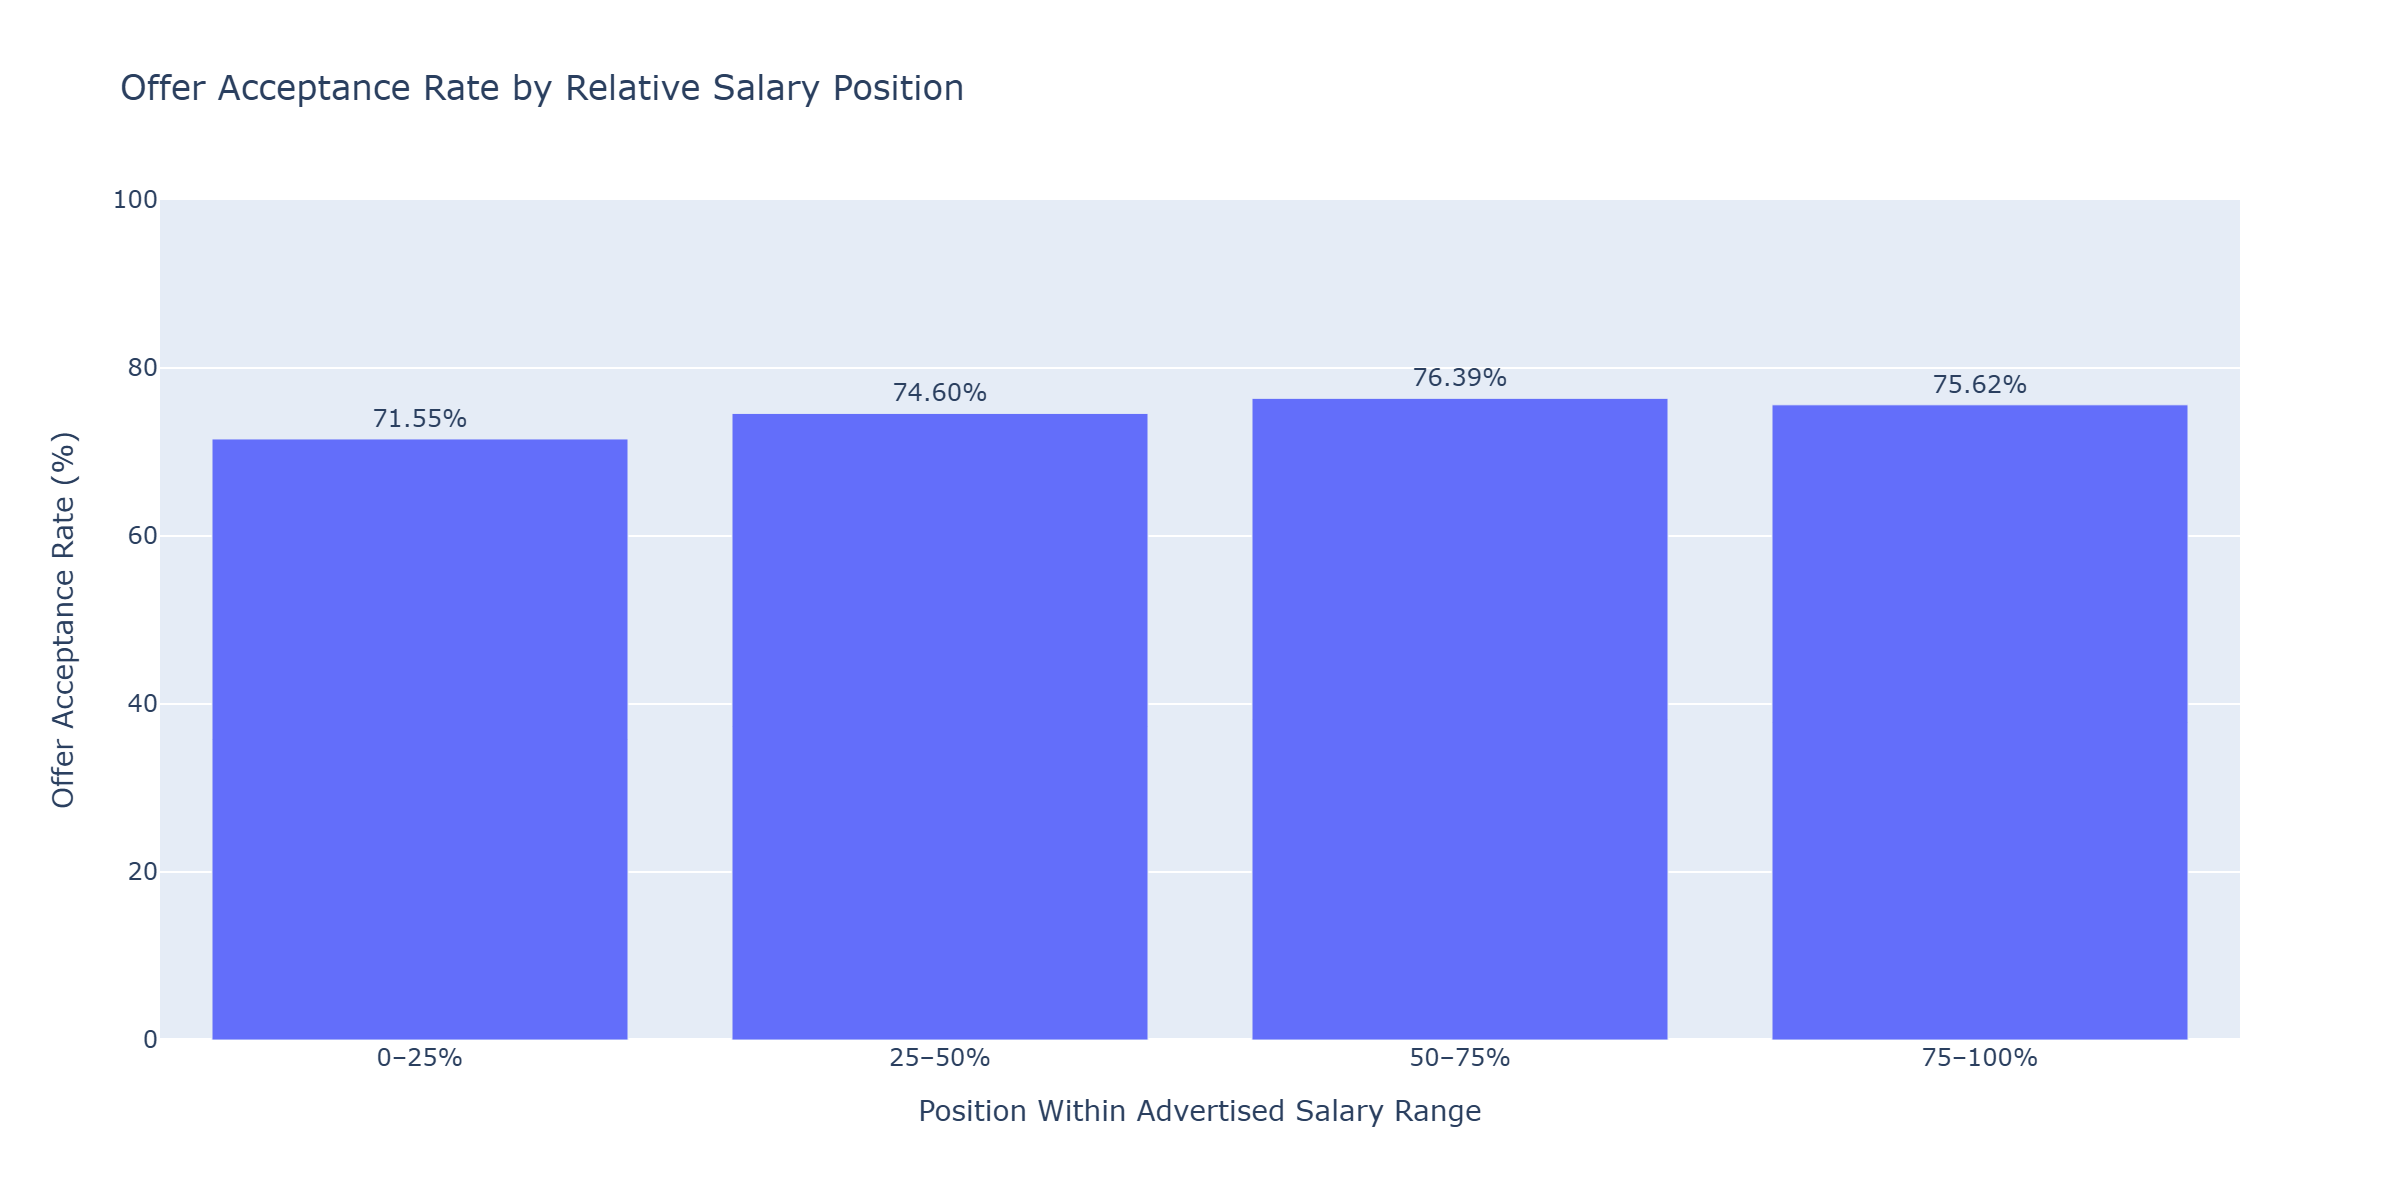

In [147]:
# Create a bar chart comparing acceptance rates by salary band
fig = px.bar(
    salary_band_summary,
    x="Salary_Band",
    y="Acceptance_Rate",
    text="Acceptance_Rate",
    title="Offer Acceptance Rate by Relative Salary Position"
)

# Display percentages above each bar
fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside",
    hovertemplate="<b>%{x}</b><extra></extra>Acceptance Rate: %{y:.2f}%"
)

# Improve chart labels and layout
fig.update_layout(
    xaxis_title="Position Within Advertised Salary Range",
    yaxis_title="Offer Acceptance Rate (%)",
    yaxis_range=[0, 100],
    showlegend=False
)

# Display the chart
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

**Acceptance-rate calculation:** `Accepted_Offers / Offers × 100` for each relative salary-position band. Higher salary position within a *posted range* is not equivalent to higher external market competitiveness.

### Step 7A — Offer Acceptance Rates by Role Family and Salary Band

In [148]:
# Select job IDs and their role families
job_families = jobs[["job_id", "role_family"]]

# Add role family information to salary analysis
salary_analysis = salary_analysis.merge(
    job_families,
    on="job_id",
    how="left"
)

# Verify the merge
print("Total offers:", len(salary_analysis))
print("Missing role families:", salary_analysis["role_family"].isna().sum())

# Preview the relevant columns
display(
    salary_analysis[
        ["application_id", "role_family", "Salary_Band", "accepted"]
    ].head()
)

Total offers: 938
Missing role families: 0


,application_id,role_family,Salary_Band,accepted
0,8,data,0–25%,True
1,13,data,25–50%,True
2,25,product,50–75%,False
3,29,engineering,50–75%,True
4,30,sales,50–75%,True


### Step 7B — Acceptance Rates by Role Family and Salary Band

In [149]:
# Count offers and accepted offers by role family and salary band
department_salary_summary = salary_analysis.groupby(
    ["role_family", "Salary_Band"],
    observed=True
).agg(
    Offers=("application_id", "count"),
    Accepted_Offers=("accepted", "sum")
).reset_index()

# Calculate acceptance rates for each group
department_salary_summary["Acceptance_Rate"] = (
    department_salary_summary["Accepted_Offers"]
    / department_salary_summary["Offers"] * 100
)

# Sort by role family and salary band
department_salary_summary = department_salary_summary.sort_values(
    ["role_family", "Salary_Band"]
)

# Display the results
display(department_salary_summary.round(2))

,role_family,Salary_Band,Offers,Accepted_Offers,Acceptance_Rate
0,customer_success,0–25%,12,10,83.33
1,customer_success,25–50%,7,3,42.86
2,customer_success,50–75%,5,4,80.00
3,customer_success,75–100%,5,3,60.00
4,data,0–25%,27,20,74.07
5,data,25–50%,32,26,81.25
6,data,50–75%,34,28,82.35
7,data,75–100%,36,25,69.44
8,engineering,0–25%,50,35,70.00
9,engineering,25–50%,58,39,67.24


### Step 7C — Create an Acceptance Rate Heatmap

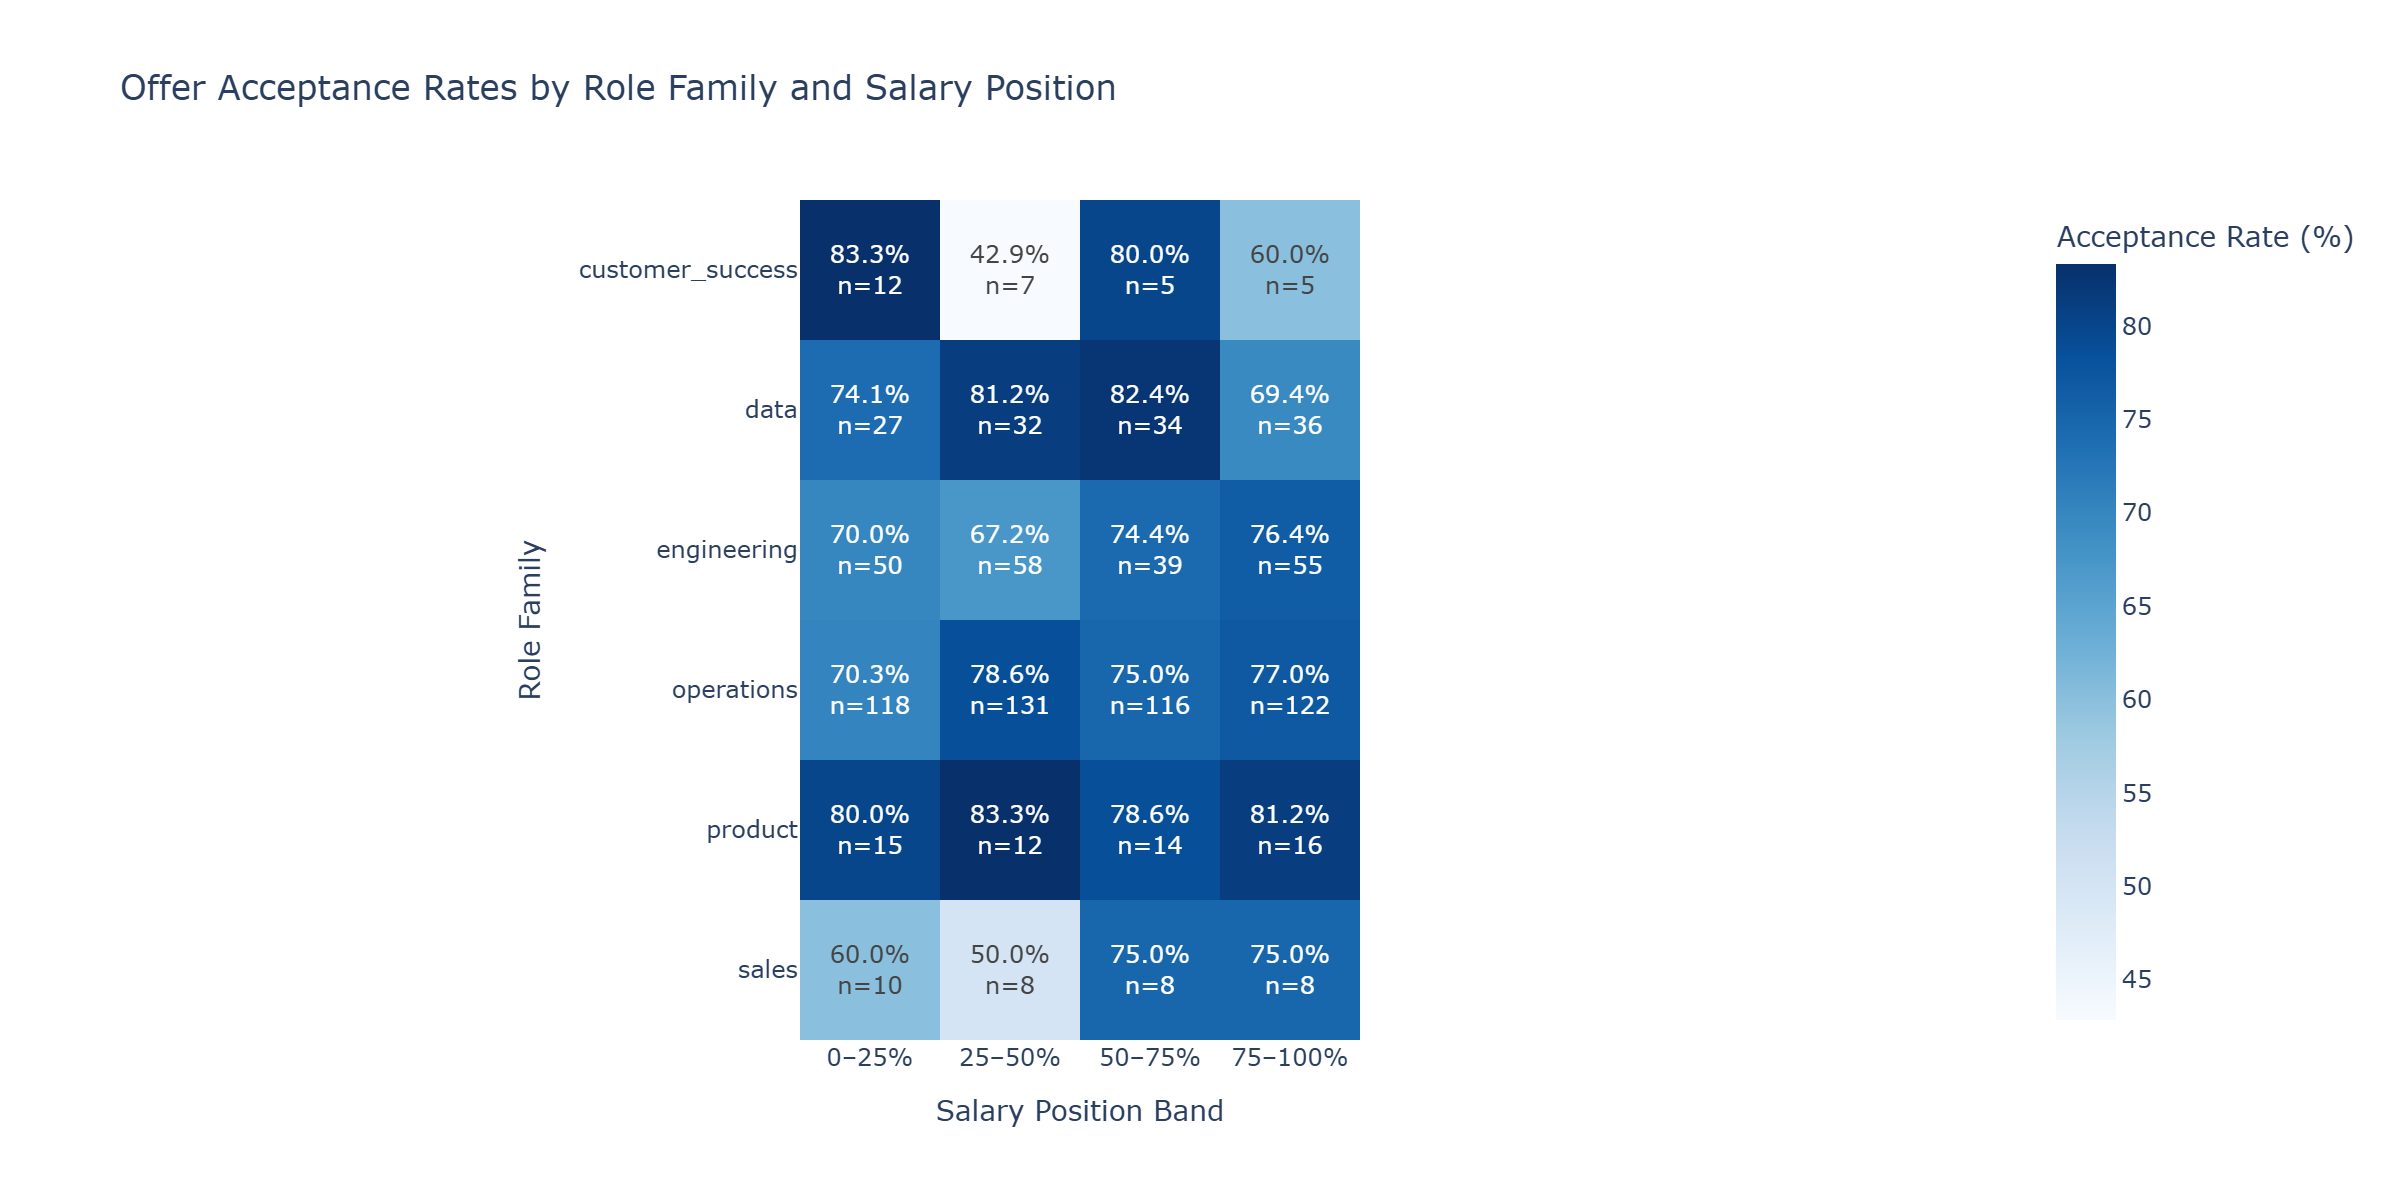

In [150]:
# Create a pivot table of acceptance rates
acceptance_heatmap = department_salary_summary.pivot(
    index="role_family",
    columns="Salary_Band",
    values="Acceptance_Rate"
)

# Create a pivot table of offer counts
offer_counts_heatmap = department_salary_summary.pivot(
    index="role_family",
    columns="Salary_Band",
    values="Offers"
)

# Create labels showing acceptance rates and offer counts
heatmap_labels = (
    acceptance_heatmap.round(1).astype(str) + "%"
    + "<br>n=" + offer_counts_heatmap.astype(str)
)

# Create the Plotly heatmap
fig = px.imshow(
    acceptance_heatmap,
    color_continuous_scale="Blues",
    labels={
        "x": "Position Within Advertised Salary Range",
        "y": "Role Family",
        "color": "Acceptance Rate (%)"
    },
    title="Offer Acceptance Rates by Role Family and Salary Position"
)

# Add acceptance rates and sample sizes inside each cell
fig.update_traces(
    text=heatmap_labels.values,
    texttemplate="%{text}"
)

# Improve chart layout
fig.update_layout(
    height=550,
    xaxis_title="Salary Position Band",
    yaxis_title="Role Family"
)

# Display the heatmap
#fig.show()

# Display a larger, high-resolution static chart for GitHub
fig.show(
    renderer="png",
    width=1200,
    height=600,
    scale=2
)

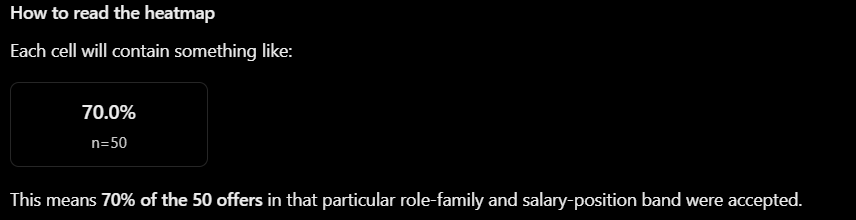


### Business Question #6 — Salary Competitiveness and Offer Acceptance

**Business Question:** Is offer acceptance associated with an offer's position inside the advertised salary range?

#### Key Findings

**1. Advertised Salary Ranges and Offers**

- The dataset contains **2,000 job postings** and **938 salary offers**.
- The average advertised salary range was approximately **$117,845 to $143,148**.
- The average offered base salary was **$129,879.69**.
- No missing salary values or invalid advertised salary ranges were identified.
- All **938 offers** fell within their respective advertised salary ranges.

**2. Relative Salary Position**

- The average salary position was **50.14%**, with a median of **49.42%**.
- The middle 50% of offers were positioned between **25.39% and 75.84%** of their advertised ranges.
- Salary positions ranged from **0.21% to 99.72%**.
- Offers were distributed across the advertised salary ranges rather than concentrated exclusively near the minimum or maximum.

**3. Offer Acceptance by Salary Position**

- **0–25%:** 166 of 232 offers accepted (**71.55%**).
- **25–50%:** 185 of 248 offers accepted (**74.60%**).
- **50–75%:** 165 of 216 offers accepted (**76.39%**).
- **75–100%:** 183 of 242 offers accepted (**75.62%**).
- The overall acceptance rate was **74.52%**, representing **699 accepted offers out of 938**.
- The highest observed acceptance rate occurred in the **50–75% salary band**.
- Acceptance rates differed by only **4.84 percentage points** between the highest and lowest bands.
- Acceptance did not increase consistently across all four salary-position bands.

**4. Offer Acceptance by Role Family**

- **Engineering:** Acceptance ranged from **67.24% to 76.36%**, with the highest rate in the 75–100% salary band.
- **Data:** Acceptance peaked at **82.35%** in the 50–75% band but declined to **69.44%** in the highest band.
- **Operations:** Acceptance ranged from **70.34% to 78.63%**, with the highest rate in the 25–50% band.
- **Product:** Acceptance remained relatively consistent, ranging from **78.57% to 83.33%** across salary bands.
- **Customer Success:** Acceptance ranged from **42.86% to 83.33%**, although individual salary bands contained only 5–12 offers.
- **Sales:** Acceptance ranged from **50.00% to 75.00%**, with only 8–10 offers per salary band.
- The departmental heatmap demonstrated that acceptance patterns vary across role families, with no consistent increase in acceptance as relative salary position rises.

#### Business Insights & Recommendations

- **Evaluate compensation positioning:** Monitor offer acceptance rates across different salary-position bands to identify potential relationships between compensation decisions and recruitment outcomes.
- **Avoid assuming higher offers guarantee acceptance:** The highest overall acceptance rate occurred in the 50–75% band, not the highest salary band.
- **Review Engineering compensation practices:** Investigate whether stronger acceptance in the upper salary band reflects candidate expectations, specialized recruitment requirements, or other factors.
- **Investigate Data recruitment outcomes:** Examine why acceptance declines in the highest salary band despite the relatively stronger results in the middle bands.
- **Monitor Operations recruitment:** Its relatively large offer volumes provide a useful starting point for ongoing internal compensation analysis.
- **Consider smaller sample sizes:** Avoid changing compensation policies based on large percentage differences supported by only a few offers, particularly in Sales and Customer Success.
- **Improve ATS offer tracking:** Capture candidate salary expectations, competing offers, reasons for declining offers, and negotiation outcomes.
- **Introduce external salary benchmarks:** Compare advertised salary ranges and offered compensation against relevant labour-market data to assess genuine salary competitiveness.
- **Evaluate compensation costs alongside acceptance:** Consider whether changes in salary positioning are associated with meaningful improvements in acceptance rates before recommending compensation adjustments.

#### Analytical Limitations

- **Synthetic dataset:** Salary ranges, offered salaries, and acceptance outcomes are artificially generated and may not reflect actual recruitment-market behaviour.
- **Relative salary position versus market competitiveness:** The analysis measures an offer's position within its advertised range, not whether the salary is competitive against external market benchmarks.
- **Missing candidate expectations:** The dataset does not include candidates' salary expectations, competing offers, or reasons for accepting or declining.
- **Potential confounding factors:** Acceptance may also be associated with job seniority, role family, employer characteristics, location, and other factors not accounted for in these descriptive comparisons.
- **Small departmental samples:** Several role-family and salary-band combinations contain relatively few offers, producing acceptance rates that may be sensitive to individual outcomes.
- **Association versus causation:** Differences in acceptance rates do not establish that salary positioning directly influences a candidate's acceptance decision.
- **Descriptive analysis:** Statistical significance and the strength of any association have not yet been evaluated. These will be investigated separately in `Statistics.ipynb`.
- **Offer acceptance versus actual hiring:** An accepted offer does not necessarily confirm that the candidate commenced employment.

#### Overall Business Conclusion

- Offer acceptance rates were relatively similar across the four salary-position bands, ranging from **71.55% to 76.39%**.
- The highest observed acceptance rate occurred when offers were positioned between **50% and 75%** of their advertised salary ranges.
- Departmental comparisons revealed varying acceptance patterns, but no consistent evidence that offers positioned closer to the advertised maximum achieve higher acceptance.
- The findings suggest that **relative salary position alone is insufficient to explain offer acceptance**.
- More detailed compensation benchmarks, candidate expectations, and recruitment outcome data would be required to develop evidence-based salary offer strategies.


## Final Notebook Review — Reproducibility and Caveats

- **Q1–Q6:** Descriptive analyses completed; statistical tests are planned separately.
- **Source integrity:** Six source CSV files remain unchanged; derived columns and flags exist only in notebook DataFrames.
- **Application counts:** 15,000 applications; 938 offer records; 699 accepted offers. Some candidates submitted multiple applications.
- **Chronology:** 217 acceptance-date exceptions were documented in Data Preparation. Separately, 29 first-interview-to-offer negative durations were excluded **only** from that 909-record duration summary, with all original records preserved.
- **Synthetic data:** Shared time-of-day patterns and unusually uniform experience distributions limit real-world interpretation.
- **Recruitment terminology:** Original `source` values are preserved; descriptive `Source_Label` labels do not resolve ambiguous source definitions.
- **Quality of hire and competitiveness:** Post-hire performance and external market salary benchmarks are unavailable, so neither can be established directly.
- **Next deliverables:** Three focused inferential investigations, an executive dashboard, and a GitHub README outlining assumptions and limitations.
